# Temporal Behavioral Analysis for Mental Health Risk Detection

**Project focus:** NLP-based analysis of social-media text and changes in model-estimated emotion and risk signals over time.

This notebook documents the project workflow: GoEmotions inference and quality checks, C-SSRS classifier development and evaluation, temporal feature construction, robustness checks, and interpretation of results.

> **Research and safety note:** This is an exploratory research pipeline, not a clinical tool or a diagnostic system. Model outputs are estimates, not verified mental-health states. Do not use the outputs to diagnose, label, or make decisions about an individual.

> **Data and reproducibility note:** The current workflow reads files from Google Drive under `/content/drive/MyDrive/mental-health-analysis`. The datasets and model artifacts are not included in this notebook. Configure paths and obtain datasets under their applicable terms before running. Some cells perform expensive inference or training; review each cell before executing.

### Contents
- [Environment and GoEmotions inference](#1-environment-and-goemotions-inference)
- [Data quality and exploratory diagnostics](#2-data-quality-and-exploratory-diagnostics)
- [Temporal feature engineering and population analyses](#3-temporal-feature-engineering-and-population-analyses)
- [C-SSRS model development and evaluation](#4-c-ssrs-model-development-and-evaluation)
- [Risk-score analysis and temporal associations](#5-risk-score-analysis-and-temporal-associations)
- [Robustness, leakage audits, and final summaries](#6-robustness-leakage-audits-and-final-summaries)

### How to use this notebook
Run cells selectively and in order within a section. Many later cells expect files created by earlier cells or saved in the project Drive folder. Existing outputs are retained only where they are useful and do not expose individual-level records. Before publishing, verify dataset licensing, paths, and dependencies.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Environment and GoEmotions Inference

This section is organized around the analysis objective. Review data paths and cell dependencies before running it.

### Load Dataset and Initialize GoEmotions
Load the prepared RMHD dataset and initialize the pretrained GoEmotions model for emotion inference.

In [ ]:
from pathlib import Path
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

PROJECT_DIR = Path("/content/drive/MyDrive/mental-health-analysis")
DATA_PATH = PROJECT_DIR / "data/processed/rmhd_emotion_input.csv"

CHECKPOINT_DIR = PROJECT_DIR / "results/predictions/goemotions/checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Verify dataset path
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Unique users:", df["author"].nunique())

assert "post_id" in df.columns and "text" in df.columns
assert df["post_id"].is_unique

# Load model
MODEL_NAME = "SamLowe/roberta-base-go_emotions"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

emotion_labels = model.config.id2label
emotion_columns = [
    f"emotion_{emotion_labels[i]}"
    for i in range(len(emotion_labels))
]

assert len(emotion_columns) == 28

print("Device:", device)
print("Number of emotion labels:", len(emotion_columns))
print("Model initialized successfully!")

Dataset shape: (83516, 9)
Unique users: 680


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Device: cuda
Number of emotion labels: 28
Model initialized successfully!


### GoEmotions Inference
Generate emotion probabilities for each post in batches. Save completed batches as checkpoint files in Google Drive so that processing can resume after an interruption.

In [ ]:
import pandas as pd
import torch

BATCH_SIZE = 32
CHECKPOINT_SIZE = 1000
MAX_LENGTH = 512

# Identify posts already processed
checkpoint_files = sorted(CHECKPOINT_DIR.glob("checkpoint_*.csv"))
completed_ids = set()

for file in checkpoint_files:
    saved = pd.read_csv(file, usecols=["post_id"])
    completed_ids.update(saved["post_id"].tolist())

print("Previously completed posts:", len(completed_ids))

pending = df.loc[~df["post_id"].isin(completed_ids)].reset_index(drop=True)
print("Posts remaining:", len(pending))

metadata_columns = [
    col for col in [
        "post_id", "author", "timestamp",
        "created_utc", "subreddit", "score"
    ]
    if col in df.columns
]

for chunk_start in range(0, len(pending), CHECKPOINT_SIZE):
    chunk = pending.iloc[chunk_start:chunk_start + CHECKPOINT_SIZE]
    chunk_results = []

    for start in range(0, len(chunk), BATCH_SIZE):
        batch = chunk.iloc[start:start + BATCH_SIZE]
        texts = batch["text"].fillna("").astype(str).tolist()

        inputs = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():
            logits = model(**inputs).logits
            probabilities = torch.sigmoid(logits).cpu().numpy()

        predictions = pd.DataFrame(
            probabilities,
            columns=emotion_columns
        )

        metadata = batch[metadata_columns].reset_index(drop=True)
        chunk_results.append(pd.concat([metadata, predictions], axis=1))

    if chunk_results:
        result = pd.concat(chunk_results, ignore_index=True)

        first_id = int(chunk["post_id"].iloc[0])
        last_id = int(chunk["post_id"].iloc[-1])
        checkpoint_path = CHECKPOINT_DIR / (
            f"checkpoint_{first_id}_{last_id}.csv"
        )

        # Write to a temporary file before marking the checkpoint complete
        temp_path = checkpoint_path.with_suffix(".tmp")
        result.to_csv(temp_path, index=False)
        temp_path.replace(checkpoint_path)

    print(
        f"Completed {min(chunk_start + len(chunk), len(pending))}"
        f"/{len(pending)} remaining posts"
    )

print("Inference finished. Checkpoints saved to Google Drive.")

Previously completed posts: 0
Posts remaining: 83516
Completed 1000/83516 remaining posts
Completed 2000/83516 remaining posts
Completed 3000/83516 remaining posts
Completed 4000/83516 remaining posts
Completed 5000/83516 remaining posts
Completed 6000/83516 remaining posts
Completed 7000/83516 remaining posts
Completed 8000/83516 remaining posts
Completed 9000/83516 remaining posts
Completed 10000/83516 remaining posts
Completed 11000/83516 remaining posts
Completed 12000/83516 remaining posts
Completed 13000/83516 remaining posts
Completed 14000/83516 remaining posts
Completed 15000/83516 remaining posts
Completed 16000/83516 remaining posts
Completed 17000/83516 remaining posts
Completed 18000/83516 remaining posts
Completed 19000/83516 remaining posts
Completed 20000/83516 remaining posts
Completed 21000/83516 remaining posts
Completed 22000/83516 remaining posts
Completed 23000/83516 remaining posts
Completed 24000/83516 remaining posts
Completed 25000/83516 remaining posts
Comple

### Export GoEmotions Predictions
Combine all saved inference checkpoints into a single dataset containing post metadata and the 28 predicted emotion probabilities.

In [ ]:
import pandas as pd

checkpoint_files = sorted(CHECKPOINT_DIR.glob("checkpoint_*.csv"))

assert checkpoint_files, "No checkpoint files found."

predictions_df = pd.concat(
    [pd.read_csv(file) for file in checkpoint_files],
    ignore_index=True
)

predictions_df = predictions_df.drop_duplicates(
    subset="post_id",
    keep="last"
)

predictions_df = predictions_df.sort_values(
    "post_id"
).reset_index(drop=True)

OUTPUT_PATH = (
    PROJECT_DIR
    / "results/predictions/goemotions/rmhd_goemotions_predictions.csv"
)
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

predictions_df.to_csv(OUTPUT_PATH, index=False)

print("Saved to:", OUTPUT_PATH)
print("Total rows:", len(predictions_df))
print("Unique posts:", predictions_df["post_id"].nunique())
print("Total columns:", len(predictions_df.columns))

Saved to: /content/drive/MyDrive/mental-health-analysis/results/predictions/goemotions/rmhd_goemotions_predictions.csv
Total rows: 83516
Unique posts: 83516
Total columns: 34


### GoEmotions Prediction Validation
Validate dataset completeness, emotion probability ranges, missing values, and prediction uniqueness.

In [ ]:
import numpy as np
import pandas as pd

predictions_df = pd.read_csv(OUTPUT_PATH)

emotion_columns = [
    col for col in predictions_df.columns
    if col.startswith("emotion_")
]

print("Rows:", len(predictions_df))
print("Unique post IDs:", predictions_df["post_id"].nunique())
print("Emotion columns:", len(emotion_columns))
print("Missing values:", predictions_df.isna().sum().sum())

probabilities = predictions_df[emotion_columns].to_numpy()

print("All probabilities finite:", np.isfinite(probabilities).all())
print("Minimum probability:", probabilities.min())
print("Maximum probability:", probabilities.max())

assert len(predictions_df) == 83516
assert predictions_df["post_id"].nunique() == 83516
assert len(emotion_columns) == 28
assert np.isfinite(probabilities).all()
assert probabilities.min() >= 0
assert probabilities.max() <= 1

print("\nAll technical validation checks passed!")

Rows: 83516
Unique post IDs: 83516
Emotion columns: 28
Missing values: 0
All probabilities finite: True
Minimum probability: 3.9786475e-05
Maximum probability: 0.9921415

All technical validation checks passed!


### Prediction Alignment Verification
Re-run inference on a reproducible random sample of 200 posts and compare the resulting emotion probabilities with the saved predictions to verify consistency.

In [ ]:
import numpy as np
import pandas as pd
import torch

# Select 200 reproducible posts
sample = df.sample(n=200, random_state=42).copy()

# Find the corresponding saved predictions
saved = predictions_df.set_index("post_id")

emotion_columns = [
    f"emotion_{emotion_labels[i]}"
    for i in range(len(emotion_labels))
]

saved_sample = saved.loc[sample["post_id"], emotion_columns].to_numpy()

# Independently run inference
texts = sample["text"].fillna("").astype(str).tolist()
new_probabilities = []

for start in range(0, len(texts), 16):
    batch_texts = texts[start:start + 16]

    inputs = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        logits = model(**inputs).logits
        probabilities = torch.sigmoid(logits).cpu().numpy()

    new_probabilities.append(probabilities)

new_probabilities = np.vstack(new_probabilities)

# Compare saved and independently generated probabilities
differences = np.abs(saved_sample - new_probabilities)

print("Sampled posts:", len(sample))
print("Compared emotion scores:", differences.size)
print("Maximum absolute difference:", differences.max())
print("Mean absolute difference:", differences.mean())

assert np.allclose(
    saved_sample,
    new_probabilities,
    atol=1e-4,
    rtol=1e-4
), "Mismatch detected: investigate inference settings or post alignment."

print("\nPrediction alignment verification passed!")

Sampled posts: 200
Compared emotion scores: 5600
Maximum absolute difference: 3.31546821596973e-06
Mean absolute difference: 3.015494542858254e-08

Prediction alignment verification passed!


### Dataset and Timestamp Integrity
Verify post metadata consistency, timestamp validity, chronological ordering, and the minimum post-count and timeline requirements for each user.

In [ ]:
import pandas as pd

# Check metadata consistency between input and predictions
metadata_cols = ["post_id", "author", "timestamp"]

input_meta = df[metadata_cols].copy()
pred_meta = predictions_df[metadata_cols].copy()

comparison = input_meta.merge(
    pred_meta,
    on="post_id",
    suffixes=("_input", "_prediction"),
    how="outer",
    indicator=True
)

print("Post ID match:", (comparison["_merge"] == "both").all())
print(
    "Author mismatches:",
    (comparison["author_input"] != comparison["author_prediction"]).sum()
)
print(
    "Timestamp mismatches:",
    (
        comparison["timestamp_input"].astype(str)
        != comparison["timestamp_prediction"].astype(str)
    ).sum()
)

# Parse timestamps
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)

print("\nInvalid timestamps:", df["timestamp"].isna().sum())

# Verify per-user requirements
user_stats = df.groupby("author").agg(
    post_count=("post_id", "count"),
    first_post=("timestamp", "min"),
    last_post=("timestamp", "max")
)

user_stats["span_days"] = (
    user_stats["last_post"] - user_stats["first_post"]
).dt.total_seconds() / 86400

print("\nUnique users:", len(user_stats))
print("Users with fewer than 50 posts:", (user_stats["post_count"] < 50).sum())
print("Users with less than 365 days:", (user_stats["span_days"] < 365).sum())

Post ID match: True
Author mismatches: 0
Timestamp mismatches: 0

Invalid timestamps: 0

Unique users: 680
Users with fewer than 50 posts: 0
Users with less than 365 days: 0


### Text Length and Truncation Analysis
Measure post lengths using the GoEmotions tokenizer and determine how many posts exceed the model's 512-token input limit.

In [ ]:
import numpy as np
import pandas as pd

texts = df["text"].fillna("").astype(str).tolist()

token_lengths = []

for start in range(0, len(texts), 256):
    batch_texts = texts[start:start + 256]

    encoded = tokenizer(
        batch_texts,
        truncation=False,
        padding=False,
        add_special_tokens=True
    )

    token_lengths.extend(
        len(input_ids) for input_ids in encoded["input_ids"]
    )

df["token_length"] = token_lengths

print("Total posts:", len(df))
print("Posts exceeding 512 tokens:", (df["token_length"] > 512).sum())
print(
    "Percentage exceeding 512 tokens:",
    round((df["token_length"] > 512).mean() * 100, 2), "%"
)

print("\nToken length statistics:")
print(df["token_length"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (836 > 512). Running this sequence through the model will result in indexing errors


Total posts: 83516
Posts exceeding 512 tokens: 2439
Percentage exceeding 512 tokens: 2.92 %

Token length statistics:
count    83516.000000
mean       111.908700
std        182.268472
min          3.000000
50%         53.000000
90%        266.000000
95%        390.000000
99%        829.000000
max      16046.000000
Name: token_length, dtype: float64


### Emotion Prediction Distribution Analysis
Summarize the distribution of predicted probabilities for each emotion to identify rare, saturated, or potentially redundant features.

In [ ]:
import pandas as pd

emotion_columns = [
    col for col in predictions_df.columns
    if col.startswith("emotion_")
]

emotion_summary = pd.DataFrame(index=emotion_columns)

emotion_summary["mean"] = predictions_df[emotion_columns].mean()
emotion_summary["median"] = predictions_df[emotion_columns].median()
emotion_summary["p90"] = predictions_df[emotion_columns].quantile(0.90)
emotion_summary["p99"] = predictions_df[emotion_columns].quantile(0.99)
emotion_summary["below_0.01_pct"] = (
    predictions_df[emotion_columns].lt(0.01).mean() * 100
)
emotion_summary["above_0.99_pct"] = (
    predictions_df[emotion_columns].gt(0.99).mean() * 100
)
emotion_summary["above_0.5_pct"] = (
    predictions_df[emotion_columns].gt(0.5).mean() * 100
)

emotion_summary = emotion_summary.sort_values("mean", ascending=False)

display(emotion_summary.round(3))

,mean,median,p90,p99,below_0.01_pct,above_0.99_pct,above_0.5_pct
emotion_neutral,0.198,0.073,0.664,0.962,1.160,0.000,13.846
emotion_sadness,0.180,0.073,0.560,0.867,21.500,0.000,12.261
emotion_disappointment,0.148,0.076,0.410,0.640,18.957,0.000,5.009
emotion_annoyance,0.095,0.034,0.287,0.576,16.002,0.000,2.372
emotion_curiosity,0.079,0.006,0.311,0.688,59.987,0.000,5.142
emotion_confusion,0.073,0.008,0.233,0.784,53.157,0.000,2.894
emotion_fear,0.061,0.006,0.162,0.844,63.641,0.000,4.241
emotion_nervousness,0.060,0.009,0.204,0.597,53.288,0.000,2.796
emotion_desire,0.052,0.005,0.119,0.777,69.113,0.000,3.730
emotion_anger,0.049,0.007,0.115,0.733,60.708,0.000,2.801


### Emotion Correlation Analysis
Measure correlations between the 28 predicted emotion probabilities to identify redundant features and groups of related model outputs.

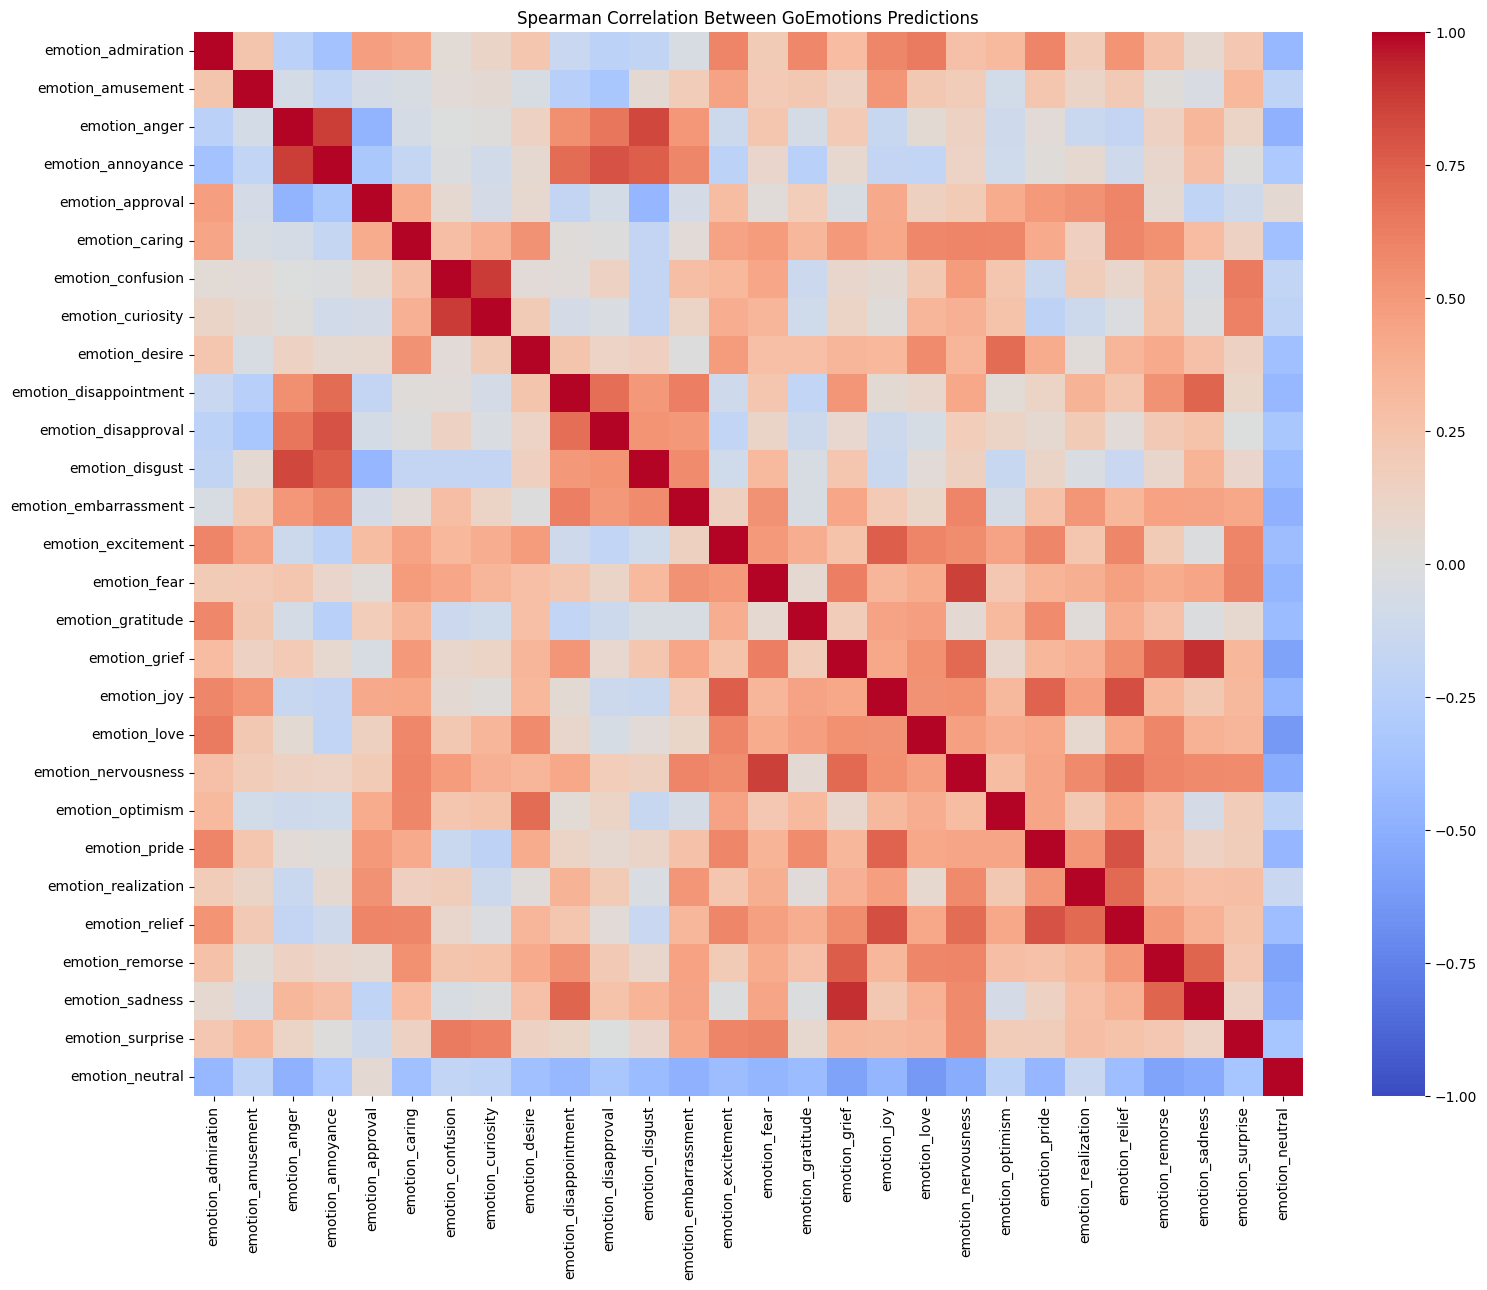

Top 10 positively correlated emotion pairs:


,,spearman_correlation
emotion_grief,emotion_sadness,0.908086
emotion_confusion,emotion_curiosity,0.875472
emotion_anger,emotion_annoyance,0.869547
emotion_fear,emotion_nervousness,0.867182
emotion_anger,emotion_disgust,0.839650
emotion_joy,emotion_relief,0.819640
emotion_pride,emotion_relief,0.800282
emotion_annoyance,emotion_disapproval,0.798665
emotion_grief,emotion_remorse,0.764440
emotion_excitement,emotion_joy,0.755425



Top 10 negatively correlated emotion pairs:


spearman_correlation
emotion_love          emotion_neutral              -0.625893
emotion_grief         emotion_neutral              -0.577280
emotion_remorse       emotion_neutral              -0.568831
emotion_sadness       emotion_neutral              -0.527512
emotion_nervousness   emotion_neutral              -0.518036
emotion_embarrassment emotion_neutral              -0.486474
emotion_anger         emotion_neutral              -0.482350
                      emotion_approval             -0.471306
emotion_joy           emotion_neutral              -0.459649
emotion_fear          emotion_neutral              -0.453438

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

emotion_columns = [
    col for col in predictions_df.columns
    if col.startswith("emotion_")
]

# Spearman correlation captures monotonic relationships
correlation_matrix = predictions_df[emotion_columns].corr(
    method="spearman"
)

plt.figure(figsize=(16, 13))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Spearman Correlation Between GoEmotions Predictions")
plt.tight_layout()
plt.show()

# Show the strongest emotion pairs, excluding self-correlations
upper_triangle = correlation_matrix.where(
    __import__("numpy").triu(
        __import__("numpy").ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

strong_pairs = (
    upper_triangle.stack()
    .sort_values(ascending=False)
)

print("Top 10 positively correlated emotion pairs:")
display(strong_pairs.head(10).to_frame("spearman_correlation"))

print("\nTop 10 negatively correlated emotion pairs:")
display(strong_pairs.tail(10).sort_values().to_frame("spearman_correlation"))

### Within-User and Between-User Emotion Variability
Compare the variability of emotion probabilities within individual users and across users to assess whether personalized emotional baselines may be useful for temporal analysis.

In [ ]:
import pandas as pd

emotion_columns = [
    col for col in predictions_df.columns
    if col.startswith("emotion_")
]

# Mean emotion score for each user
user_means = predictions_df.groupby("author")[emotion_columns].mean()

# Between-user variability: variation in users' mean scores
between_user_variance = user_means.var()

# Within-user variability: average variation of scores within each user
within_user_variance = (
    predictions_df.groupby("author")[emotion_columns]
    .var()
    .mean()
)

variability_summary = pd.DataFrame({
    "between_user_variance": between_user_variance,
    "within_user_variance": within_user_variance
})

variability_summary["within_between_ratio"] = (
    variability_summary["within_user_variance"]
    / variability_summary["between_user_variance"].replace(0, float("nan"))
)

display(
    variability_summary.sort_values(
        "within_between_ratio"
    ).round(5)
)

,between_user_variance,within_user_variance,within_between_ratio
emotion_nervousness,0.00585,0.01203,2.05673
emotion_disappointment,0.00559,0.02455,4.39143
emotion_curiosity,0.00484,0.02162,4.46469
emotion_caring,0.00087,0.00425,4.86325
emotion_fear,0.00481,0.02590,5.38397
emotion_neutral,0.00458,0.02612,5.70458
emotion_approval,0.00049,0.00284,5.73654
emotion_annoyance,0.00264,0.01655,6.26791
emotion_confusion,0.00261,0.01641,6.27928
emotion_gratitude,0.00090,0.00616,6.81687



### Intraclass Correlation of Emotion Scores
Estimate the proportion of emotion-score variation attributable to differences between users, accounting for unequal numbers of posts per user. Treat these results as descriptive because the scores are model predictions rather than human-validated emotion labels.


In [ ]:

import numpy as np
import pandas as pd

emotion_columns = [
    col for col in predictions_df.columns
    if col.startswith("emotion_")
]

icc_results = []

for emotion in emotion_columns:
    data = predictions_df[["author", emotion]].dropna()
    grouped = data.groupby("author")[emotion]

    group_sizes = grouped.size()
    group_means = grouped.mean()

    n = len(data)
    k = len(group_sizes)

    if k < 2 or n <= k:
        continue

    grand_mean = data[emotion].mean()

    # Between-user mean square
    ss_between = (
        group_sizes * (group_means - grand_mean) ** 2
    ).sum()
    ms_between = ss_between / (k - 1)

    # Within-user mean square
    ss_within = grouped.apply(
        lambda values: ((values - values.mean()) ** 2).sum()
    ).sum()
    ms_within = ss_within / (n - k)

    # Effective average group size for unequal group sizes
    k0 = (
        n - (group_sizes.pow(2).sum() / n)
    ) / (k - 1)

    denominator = ms_between + (k0 - 1) * ms_within

    icc = (
        (ms_between - ms_within) / denominator
        if denominator > 0 else np.nan
    )

    icc_results.append({
        "emotion": emotion,
        "users": k,
        "posts": n,
        "icc_1_1": icc,
        "between_user_ms": ms_between,
        "within_user_ms": ms_within
    })

icc_df = pd.DataFrame(icc_results).sort_values("icc_1_1")

display(icc_df.round(5))


,emotion,users,posts,icc_1_1,between_user_ms,within_user_ms
26,emotion_surprise,680,83516,0.00586,0.00143,0.00085
21,emotion_pride,680,83516,0.02396,0.00021,0.00005
11,emotion_disgust,680,83516,0.03270,0.00970,0.00198
24,emotion_remorse,680,83516,0.03394,0.01688,0.00335
22,emotion_realization,680,83516,0.03665,0.01959,0.00364
12,emotion_embarrassment,680,83516,0.03671,0.00555,0.00103
10,emotion_disapproval,680,83516,0.05625,0.04247,0.00541
20,emotion_optimism,680,83516,0.06358,0.05473,0.00621
0,emotion_admiration,680,83516,0.07524,0.02639,0.00255
18,emotion_love,680,83516,0.08914,0.08088,0.00660



### Temporal Baseline Stability
Compare each user's mean emotion probabilities across the first and second halves of their posting history. Measure the correlation and absolute difference between the two halves to assess baseline stability.


In [ ]:

import numpy as np
import pandas as pd

df = predictions_df.copy()
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce", utc=True
)
df = df.dropna(subset=["author", "timestamp"])

emotion_columns = [
    col for col in df.columns if col.startswith("emotion_")
]

df = df.sort_values(["author", "timestamp"])
df["post_order"] = df.groupby("author").cumcount()
df["user_post_count"] = df.groupby("author")["author"].transform("size")
df["half"] = np.where(
    df["post_order"] < df["user_post_count"] / 2,
    "first",
    "second"
)

user_half_means = (
    df.groupby(["author", "half"])[emotion_columns]
    .mean()
    .unstack("half")
)

stability_results = []

for emotion in emotion_columns:
    first = user_half_means[(emotion, "first")]
    second = user_half_means[(emotion, "second")]

    valid = first.notna() & second.notna()
    first = first[valid]
    second = second[valid]

    correlation = (
        first.corr(second, method="spearman")
        if len(first) >= 3 else np.nan
    )

    stability_results.append({
        "emotion": emotion,
        "users_compared": len(first),
        "spearman_correlation": correlation,
        "mean_absolute_difference": (first - second).abs().mean()
    })

stability_df = pd.DataFrame(stability_results).sort_values(
    "spearman_correlation", ascending=False
)

display(stability_df.round(4))


,emotion,users_compared,spearman_correlation,mean_absolute_difference
19,emotion_nervousness,680,0.7807,0.0262
9,emotion_disappointment,680,0.7622,0.0386
2,emotion_anger,680,0.7502,0.0233
3,emotion_annoyance,680,0.7309,0.0306
25,emotion_sadness,680,0.7047,0.0492
7,emotion_curiosity,680,0.7015,0.0346
6,emotion_confusion,680,0.6972,0.0283
27,emotion_neutral,680,0.6560,0.0378
14,emotion_fear,680,0.6549,0.0343
10,emotion_disapproval,680,0.6512,0.0129



### Temporal Change Versus a Shuffled Baseline
Compare observed differences between early and late emotion scores with differences obtained after randomly shuffling post order within each user. This is a diagnostic for temporal ordering, not proof of mental-health risk.


In [ ]:

import numpy as np
import pandas as pd

df = predictions_df.copy()
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce", utc=True
)
df = df.dropna(subset=["author", "timestamp"]).sort_values(
    ["author", "timestamp"]
)

emotion_columns = [
    col for col in df.columns if col.startswith("emotion_")
]

# Use a reproducible subset of users to keep the test lightweight.
rng = np.random.default_rng(42)
users = df["author"].drop_duplicates().to_numpy()
sampled_users = rng.choice(
    users, size=min(150, len(users)), replace=False
)

sample = df[df["author"].isin(sampled_users)].copy()
rng = np.random.default_rng(42)

def mean_half_difference(values):
    midpoint = len(values) // 2
    if midpoint == 0 or midpoint == len(values):
        return np.nan
    return abs(values[:midpoint].mean() - values[midpoint:].mean())

results = []

for emotion in emotion_columns:
    observed_differences = []
    shuffled_differences = []

    for _, group in sample.groupby("author", sort=False):
        values = group[emotion].to_numpy()

        if len(values) < 4:
            continue

        observed_differences.append(
            mean_half_difference(values)
        )

        shuffled_values = rng.permutation(values)
        shuffled_differences.append(
            mean_half_difference(shuffled_values)
        )

    observed = np.nanmean(observed_differences)
    shuffled = np.nanmean(shuffled_differences)

    results.append({
        "emotion": emotion,
        "users": len(observed_differences),
        "observed_difference": observed,
        "shuffled_difference": shuffled,
        "difference_excess": observed - shuffled,
        "observed_to_shuffled_ratio": (
            observed / shuffled if shuffled > 0 else np.nan
        )
    })

temporal_test_df = pd.DataFrame(results).sort_values(
    "difference_excess", ascending=False
)

display(temporal_test_df.round(5))


,emotion,users,observed_difference,shuffled_difference,difference_excess,observed_to_shuffled_ratio
25,emotion_sadness,150,0.05309,0.03856,0.01454,1.37697
19,emotion_nervousness,150,0.02742,0.01741,0.01001,1.57527
9,emotion_disappointment,150,0.03944,0.02998,0.00946,1.31541
27,emotion_neutral,150,0.03595,0.02655,0.00940,1.35392
14,emotion_fear,150,0.03747,0.02871,0.00877,1.30545
7,emotion_curiosity,150,0.03284,0.02420,0.00864,1.35716
3,emotion_annoyance,150,0.02912,0.02322,0.00591,1.25434
18,emotion_love,150,0.01753,0.01171,0.00582,1.49707
6,emotion_confusion,150,0.02763,0.02287,0.00476,1.20832
5,emotion_caring,150,0.01290,0.00970,0.00320,1.32974


## 2. Data Quality and Exploratory Diagnostics

This section is organized around the analysis objective. Review data paths and cell dependencies before running it.


### Check for Existing GoEmotions Evaluation Data
Search the project directory for locally available labelled GoEmotions datasets and evaluation artifacts before downloading data or running the model again.


In [ ]:

from pathlib import Path

project_root = Path(
    "/content/drive/MyDrive/mental-health-analysis"
)

search_roots = [
    project_root / "data",
    project_root / "results",
    project_root / "reports",
]

extensions = {".csv", ".json", ".jsonl", ".parquet", ".arrow"}

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            print(path.relative_to(project_root))


data/processed/rmhd_680_clean.csv
data/processed/rmhd_emotion_input.csv
results/predictions/goemotions/rmhd_goemotions_predictions.csv
results/predictions/goemotions/checkpoints/checkpoint_0_999.csv
results/predictions/goemotions/checkpoints/checkpoint_1000_1999.csv
results/predictions/goemotions/checkpoints/checkpoint_2000_2999.csv
results/predictions/goemotions/checkpoints/checkpoint_3000_3999.csv
results/predictions/goemotions/checkpoints/checkpoint_4000_4999.csv
results/predictions/goemotions/checkpoints/checkpoint_5000_5999.csv
results/predictions/goemotions/checkpoints/checkpoint_6000_6999.csv
results/predictions/goemotions/checkpoints/checkpoint_7000_7999.csv
results/predictions/goemotions/checkpoints/checkpoint_8000_8999.csv
results/predictions/goemotions/checkpoints/checkpoint_9000_9999.csv
results/predictions/goemotions/checkpoints/checkpoint_10000_10999.csv
results/predictions/goemotions/checkpoints/checkpoint_11000_11999.csv
results/predictions/goemotions/checkpoints/checkp


### Check for Cached GoEmotions Evaluation Dataset
Check whether the official GoEmotions dataset is already cached locally before downloading or running any model inference.


In [ ]:

from pathlib import Path

cache_roots = [
    Path("/root/.cache/huggingface/datasets"),
    Path("/root/.cache/huggingface/hub"),
    Path("/content"),
]

for root in cache_roots:
    if not root.exists():
        continue

    print(f"\nSearching: {root}")

    matches = [
        p for p in root.rglob("*")
        if p.is_file()
        and "go_emotions" in str(p).lower()
        and p.suffix.lower() in {
            ".parquet", ".arrow", ".csv", ".json", ".jsonl"
        }
    ]

    for path in matches[:30]:
        print(path)



### Locate Previous GoEmotions Evaluation
Search project scripts and notebooks for the previously reported macro F1 score and evaluation code so the metric can be traced before repeating any experiments.


In [ ]:

from pathlib import Path

project_root = Path(
    "/content/drive/MyDrive/mental-health-analysis"
)

terms = [
    "0.4986",
    "macro_f1",
    "f1_score",
    "classification_report",
    "threshold",
]

extensions = {".py", ".ipynb", ".md", ".txt"}

for path in project_root.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue

    if any(part.startswith(".") for part in path.parts):
        continue

    try:
        content = path.read_text(
            encoding="utf-8", errors="ignore"
        )
    except OSError:
        continue

    matches = [
        term for term in terms
        if term.lower() in content.lower()
    ]

    if matches:
        print(f"{path.relative_to(project_root)}: {matches}")



### Prediction Quality Diagnostics
Assess probability saturation, zero median absolute deviation (MAD), the relationship between text length and predicted emotion probabilities, and the distribution of truncated posts across users using existing predictions only.


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/mental-health-analysis"
)

predictions_path = (
    PROJECT_ROOT
    / "results/predictions/goemotions/rmhd_goemotions_predictions.csv"
)

input_path = (
    PROJECT_ROOT
    / "data/processed/rmhd_emotion_input.csv"
)

predictions_df = pd.read_csv(predictions_path)
df = pd.read_csv(input_path)

print("Predictions loaded:", predictions_df.shape)
print("Input data loaded:", df.shape)
print("Prediction columns:", predictions_df.columns.tolist())
print("Input columns:", df.columns.tolist())


# Emotion prediction columns
emotion_columns = [
    c for c in predictions_df.columns
    if c.startswith("emotion_")
]

# 1. Probability saturation and zero-MAD diagnostics
saturation_rows = []

for emotion in emotion_columns:
    values = predictions_df[emotion].dropna()
    median = values.median()
    mad = (values - median).abs().median()

    saturation_rows.append({
        "emotion": emotion,
        "mean": values.mean(),
        "below_0.01_pct": (values < 0.01).mean() * 100,
        "above_0.99_pct": (values > 0.99).mean() * 100,
        "zero_mad": mad == 0,
        "mad": mad
    })

saturation_df = pd.DataFrame(saturation_rows)
print("PROBABILITY SATURATION AND MAD")
display(saturation_df.round(5))

# 2. Text length versus emotion scores
text_df = df[["post_id", "author", "text"]].copy()
text_df["text"] = text_df["text"].fillna("").astype(str)
text_df["character_length"] = text_df["text"].str.len()

text_df = text_df.merge(
    predictions_df[["post_id"] + emotion_columns],
    on="post_id",
    how="inner",
    validate="one_to_one"
)

# Character length is a CPU-only proxy; exact token length
# requires the model tokenizer.
length_rows = []

for emotion in emotion_columns:
    length_rows.append({
        "emotion": emotion,
        "spearman_length_correlation": text_df[
            ["character_length", emotion]
        ].corr(method="spearman").iloc[0, 1]
    })

length_df = pd.DataFrame(length_rows)
print("TEXT LENGTH CORRELATIONS")
display(
    length_df.assign(
        abs_correlation=length_df[
            "spearman_length_correlation"
        ].abs()
    ).sort_values("abs_correlation", ascending=False).round(4)
)

# 3. Truncated-post distribution across users
# This assumes the existing df has the same text used for inference.
# If exact tokenizer lengths were saved earlier, use those instead.
truncated_post_ids = set()

# Use the recorded token lengths if available; do not load the model.
if "token_length" in df.columns:
    truncated_post_ids = set(
        df.loc[df["token_length"] > 512, "post_id"]
    )
elif "token_length" in predictions_df.columns:
    truncated_post_ids = set(
        predictions_df.loc[
            predictions_df["token_length"] > 512, "post_id"
        ]
    )

if truncated_post_ids:
    truncation = df[["post_id", "author"]].copy()
    truncation["is_truncated"] = truncation["post_id"].isin(
        truncated_post_ids
    )

    user_truncation = truncation.groupby("author").agg(
        posts=("post_id", "size"),
        truncated_posts=("is_truncated", "sum")
    )
    user_truncation["truncated_pct"] = (
        user_truncation["truncated_posts"]
        / user_truncation["posts"] * 100
    )

    print("USER-LEVEL TRUNCATION")
    display(user_truncation["truncated_pct"].describe().to_frame())
    print(
        "Users with more than 10% truncated posts:",
        int((user_truncation["truncated_pct"] > 10).sum())
    )
else:
    print(
        "Exact token lengths are not present in these DataFrames. "
        "We already know 2,439 posts (2.92%) exceeded 512 tokens. "
        "We will calculate user-level truncation after loading the "
        "previously saved token-length results, if available."
    )



### Relationship Between Text Length and Emotion Scores
Measure the Spearman correlation between post character length and each predicted emotion probability to identify possible text-length effects.


In [ ]:

import pandas as pd

text_df = df[["post_id", "text"]].copy()
text_df["text"] = text_df["text"].fillna("").astype(str)
text_df["character_length"] = text_df["text"].str.len()

text_df = text_df.merge(
    predictions_df[["post_id"] + emotion_columns],
    on="post_id",
    how="inner",
    validate="one_to_one"
)

length_results = []

for emotion in emotion_columns:
    correlation = text_df[
        ["character_length", emotion]
    ].corr(method="spearman").iloc[0, 1]

    length_results.append({
        "emotion": emotion,
        "spearman_length_correlation": correlation
    })

length_df = pd.DataFrame(length_results)
length_df["absolute_correlation"] = (
    length_df["spearman_length_correlation"].abs()
)

display(
    length_df.sort_values(
        "absolute_correlation", ascending=False
    ).round(4)
)


,emotion,spearman_length_correlation,absolute_correlation
19,emotion_nervousness,0.4868,0.4868
27,emotion_neutral,-0.4824,0.4824
9,emotion_disappointment,0.4494,0.4494
10,emotion_disapproval,0.4369,0.4369
23,emotion_relief,0.4235,0.4235
12,emotion_embarrassment,0.4097,0.4097
22,emotion_realization,0.4033,0.4033
21,emotion_pride,0.3901,0.3901
20,emotion_optimism,0.3603,0.3603
14,emotion_fear,0.3567,0.3567



### Distribution of Truncated Posts Across Users
Use previously calculated token lengths to quantify how many posts exceed 512 tokens for each user. Identify whether truncation is concentrated among particular users before deciding whether a targeted robustness experiment is necessary.


In [ ]:

import pandas as pd

# Look for previously saved token-length columns
print("Input token-length columns:",
      [c for c in df.columns if "token" in c.lower() or "length" in c.lower()])

print("Prediction token-length columns:",
      [c for c in predictions_df.columns if "token" in c.lower() or "length" in c.lower()])


Input token-length columns: []
Prediction token-length columns: []



### Calculate Token Lengths for Truncation Analysis
Load the tokenizer only, calculate token lengths in batches, and save the results to Google Drive. Do not load the model or generate predictions.


In [ ]:

from transformers import AutoTokenizer
from pathlib import Path
import pandas as pd

tokenizer = AutoTokenizer.from_pretrained(
    "SamLowe/roberta-base-go_emotions"
)

token_lengths = []

for start in range(0, len(df), 256):
    texts = df["text"].iloc[start:start + 256].fillna("").tolist()
    encoded = tokenizer(
        texts,
        truncation=False,
        padding=False,
        add_special_tokens=True
    )
    token_lengths.extend(len(ids) for ids in encoded["input_ids"])

lengths_df = df[["post_id", "author"]].copy()
lengths_df["token_length"] = token_lengths
lengths_df["exceeds_512_tokens"] = lengths_df["token_length"] > 512

output_path = (
    PROJECT_ROOT / "results" / "predictions" /
    "goemotions" / "token_lengths.csv"
)
output_path.parent.mkdir(parents=True, exist_ok=True)
lengths_df.to_csv(output_path, index=False)

print("Posts processed:", len(lengths_df))
print("Posts exceeding 512 tokens:", int(lengths_df["exceeds_512_tokens"].sum()))
print("Percentage exceeding 512:", round(lengths_df["exceeds_512_tokens"].mean() * 100, 2), "%")
print("Saved to:", output_path)


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (836 > 512). Running this sequence through the model will result in indexing errors


Posts processed: 83516
Posts exceeding 512 tokens: 2439
Percentage exceeding 512: 2.92 %
Saved to: /content/drive/MyDrive/mental-health-analysis/results/predictions/goemotions/token_lengths.csv



### User-Level Truncation Analysis
Measure the proportion of posts exceeding 512 tokens for each user and identify whether truncation is concentrated among particular users.


In [ ]:

lengths_df = pd.read_csv(
    PROJECT_ROOT / "results/predictions/goemotions/token_lengths.csv"
)

user_truncation = (
    lengths_df.groupby("author")
    .agg(
        total_posts=("post_id", "size"),
        truncated_posts=("exceeds_512_tokens", "sum"),
        median_tokens=("token_length", "median")
    )
    .reset_index()
)

user_truncation["truncation_pct"] = (
    user_truncation["truncated_posts"]
    / user_truncation["total_posts"] * 100
)

print("Users:", len(user_truncation))
print("Users with at least one truncated post:",
      (user_truncation["truncated_posts"] > 0).sum())
print("Users with over 10% of posts truncated:",
      (user_truncation["truncation_pct"] > 10).sum())
print("\nHighest truncation rates:")
print(
    user_truncation.sort_values(
        ["truncation_pct", "truncated_posts"],
        ascending=False
    ).head(10).to_string(index=False)
)



### Truncation Sensitivity Analysis
Compare user-level truncation rates with their mean GoEmotions prediction scores. Treat associations as diagnostic rather than causal.


In [ ]:

from scipy.stats import spearmanr
import numpy as np
import pandas as pd

# Match predictions to token lengths by post ID.
token_info = lengths_df[["post_id", "token_length", "exceeds_512_tokens"]]

analysis_df = predictions_df.merge(
    token_info,
    on="post_id",
    how="inner",
    validate="one_to_one"
)

emotion_columns = [
    c for c in predictions_df.columns
    if c.startswith("emotion_")
]

# User-level truncation rate and emotion means.
user_rates = (
    analysis_df.groupby("author")
    .agg(
        total_posts=("post_id", "size"),
        truncation_pct=("exceeds_512_tokens", lambda x: x.mean() * 100)
    )
)

user_emotions = analysis_df.groupby("author")[emotion_columns].mean()
user_analysis = user_rates.join(user_emotions)

results = []
for emotion in emotion_columns:
    rho, p = spearmanr(
        user_analysis["truncation_pct"],
        user_analysis[emotion]
    )
    results.append({
        "emotion": emotion.replace("emotion_", ""),
        "spearman_rho": rho,
        "p_value": p
    })

truncation_correlations = pd.DataFrame(results)
truncation_correlations["abs_rho"] = (
    truncation_correlations["spearman_rho"].abs()
)

print("Matched posts:", len(analysis_df))
print("\nStrongest associations with user truncation rate:")
print(
    truncation_correlations.sort_values(
        "abs_rho", ascending=False
    ).head(10).round(4).to_string(index=False)
)


Matched posts: 83516

Strongest associations with user truncation rate:
       emotion  spearman_rho  p_value  abs_rho
   realization        0.2405   0.0000   0.2405
 embarrassment        0.2302   0.0000   0.2302
disappointment        0.2112   0.0000   0.2112
        desire       -0.1649   0.0000   0.1649
         pride        0.1550   0.0000   0.1550
      approval        0.1499   0.0001   0.1499
   nervousness        0.1440   0.0002   0.1440
       neutral       -0.1417   0.0002   0.1417
        relief        0.1412   0.0002   0.1412
     curiosity       -0.1081   0.0048   0.1081



### Temporal Window Coverage Analysis
Measure how many users have enough posts in a recent 30-day window and a preceding 180-day baseline. Use only timestamps and post counts at this stage; no model inference is required.


In [ ]:

import pandas as pd

temporal_df = analysis_df[["author", "timestamp"]].copy()
temporal_df["timestamp"] = pd.to_datetime(
    temporal_df["timestamp"], errors="coerce", utc=True
)
temporal_df = temporal_df.dropna(subset=["timestamp"])

# Define windows relative to each user's latest observed post.
coverage_rows = []

for author, group in temporal_df.groupby("author"):
    dates = group["timestamp"]
    latest = dates.max()

    recent_start = latest - pd.Timedelta(days=30)
    baseline_start = latest - pd.Timedelta(days=210)

    recent_count = ((dates > recent_start) & (dates <= latest)).sum()
    baseline_count = ((dates > baseline_start) & (dates <= recent_start)).sum()

    coverage_rows.append({
        "author": author,
        "recent_30d_posts": int(recent_count),
        "baseline_180d_posts": int(baseline_count)
    })

coverage_df = pd.DataFrame(coverage_rows)

print("Total users:", len(coverage_df))
for recent_min, baseline_min in [(5, 15), (8, 20), (10, 30)]:
    eligible = (
        (coverage_df["recent_30d_posts"] >= recent_min) &
        (coverage_df["baseline_180d_posts"] >= baseline_min)
    )
    print(
        f"Recent >= {recent_min}, baseline >= {baseline_min}: "
        f"{eligible.sum()} users ({eligible.mean() * 100:.1f}%)"
    )

print("\nRecent-window post-count quantiles:")
print(coverage_df["recent_30d_posts"].quantile([0, .25, .5, .75, .9, 1]))

print("\nBaseline-window post-count quantiles:")
print(coverage_df["baseline_180d_posts"].quantile([0, .25, .5, .75, .9, 1]))


Total users: 680
Recent >= 5, baseline >= 15: 148 users (21.8%)
Recent >= 8, baseline >= 20: 87 users (12.8%)
Recent >= 10, baseline >= 30: 58 users (8.5%)

Recent-window post-count quantiles:
0.00     1.00
0.25     1.00
0.50     2.00
0.75     5.25
0.90    11.00
1.00    91.00
Name: recent_30d_posts, dtype: float64

Baseline-window post-count quantiles:
0.00      0.0
0.25      5.0
0.50     13.0
0.75     27.0
0.90     45.0
1.00    529.0
Name: baseline_180d_posts, dtype: float64



### Subreddit Composition and User-Level Affect
Measure how many subreddits each user participates in and how strongly each subreddit contributes to the dataset. This is a descriptive diagnostic before adjusting for subreddit effects.


In [ ]:

# Use the existing input data and prediction metadata.
subreddit_df = df[["post_id", "author", "subreddit", "timestamp"]].copy()

subreddit_df["subreddit"] = subreddit_df["subreddit"].fillna("UNKNOWN")

user_subreddit = (
    subreddit_df.groupby("author")
    .agg(
        total_posts=("post_id", "size"),
        subreddit_count=("subreddit", "nunique")
    )
)

subreddit_counts = (
    subreddit_df["subreddit"]
    .value_counts()
    .rename_axis("subreddit")
    .reset_index(name="post_count")
)

subreddit_counts["post_percentage"] = (
    subreddit_counts["post_count"] / len(subreddit_df) * 100
)

print("Unique subreddits:", subreddit_df["subreddit"].nunique())
print("\nUser subreddit-count quantiles:")
print(user_subreddit["subreddit_count"].quantile([0, .25, .5, .75, .9, 1]))

print("\nTop 15 subreddits by post volume:")
print(subreddit_counts.head(15).round(2).to_string(index=False))

print("\nUsers participating in only one subreddit:",
      (user_subreddit["subreddit_count"] == 1).sum())


Unique subreddits: 3480

User subreddit-count quantiles:
0.00       1.0
0.25       2.0
0.50       3.0
0.75       4.0
0.90       4.0
1.00    3480.0
Name: subreddit_count, dtype: float64

Top 15 subreddits by post volume:
                                                                                                         subreddit  post_count  post_percentage
                                                                                                        depression       29366            35.16
                                                                                                      SuicideWatch       21334            25.54
                                                                                                           Anxiety       12013            14.38
                                                                                                      mentalhealth       10463            12.53
                                                            


### Subreddit Metadata Quality Check
Inspect subreddit-name patterns, compare suspicious values with the original title and text fields, and quantify how many records may have malformed subreddit metadata.


In [ ]:

import re
import pandas as pd

check_df = df[["author", "subreddit", "title", "text"]].copy()
check_df["subreddit"] = check_df["subreddit"].fillna("").astype(str).str.strip()

# Heuristic flags only; these do not automatically prove a record is invalid.
check_df["contains_spaces"] = check_df["subreddit"].str.contains(r"\s", regex=True)
check_df["sentence_like"] = check_df["subreddit"].str.len().ge(40)
check_df["punctuation_heavy"] = check_df["subreddit"].str.contains(
    r"[.!?❤️]", regex=True
)

print("Rows:", len(check_df))
print("Unique subreddit strings:", check_df["subreddit"].nunique())
print("Values containing spaces:", int(check_df["contains_spaces"].sum()))
print("Values 40+ characters:", int(check_df["sentence_like"].sum()))
print("Values with sentence-like punctuation:", int(check_df["punctuation_heavy"].sum()))

print("\nLongest suspicious values:")
suspicious = check_df[
    check_df["contains_spaces"] |
    check_df["sentence_like"] |
    check_df["punctuation_heavy"]
]

print(
    suspicious[["subreddit", "title", "text"]]
    .drop_duplicates(subset=["subreddit"])
    .assign(subreddit_length=lambda x: x["subreddit"].str.len())
    .sort_values("subreddit_length", ascending=False)
    [["subreddit", "title"]]
    .head(15)
    .to_string(index=False)
)



### Verify and Recover Subreddit Metadata
Extract subreddit names from Reddit URLs in the title field and compare them against the existing subreddit column. Preserve the original data and create a corrected analysis-only column.


In [ ]:

import pandas as pd

# Extract subreddit names from Reddit URLs in the title.
url_subreddit = df["title"].fillna("").str.extract(
    r"reddit\.com/r/([^/]+)/",
    expand=False
)

check = pd.DataFrame({
    "original_subreddit": df["subreddit"].fillna("").astype(str),
    "extracted_subreddit": url_subreddit
})

valid_url = check["extracted_subreddit"].notna()

print("Total posts:", len(check))
print("Posts with subreddit recoverable from URL:", int(valid_url.sum()))
print("Recovery percentage:", round(valid_url.mean() * 100, 2), "%")
print("\nExtracted subreddit counts:")
print(check.loc[valid_url, "extracted_subreddit"].value_counts().head(15))

print("\nExamples where original and extracted values differ:")
print(
    check.loc[
        valid_url &
        (check["original_subreddit"] != check["extracted_subreddit"])
    ].head(10).to_string(index=False)
)


Total posts: 83516
Posts with subreddit recoverable from URL: 3702
Recovery percentage: 4.43 %

Extracted subreddit counts:
extracted_subreddit
depression      2099
SuicideWatch    1067
lonely           247
mentalhealth     189
Anxiety          100
Name: count, dtype: int64

Examples where original and extracted values differ:
                                                                                                                  original_subreddit extracted_subreddit
                                                                                                                                 Sad          depression
                                                                                        Please I need to know what to do. [TRIGGERS]             Anxiety
                                                                                                           This post is not about me          depression
                                                           


### Monthly Emotion-Score Drift
Calculate monthly mean GoEmotions scores across the dataset. Report the number of posts and active users per month to identify changes in data coverage alongside changes in predicted affect.


In [ ]:

import pandas as pd

monthly_df = analysis_df.copy()
monthly_df["timestamp"] = pd.to_datetime(
    monthly_df["timestamp"], errors="coerce", utc=True
)
monthly_df = monthly_df.dropna(subset=["timestamp"])
monthly_df["month"] = monthly_df["timestamp"].dt.to_period("M").astype(str)

emotion_columns = [
    c for c in predictions_df.columns
    if c.startswith("emotion_")
]

monthly_summary = (
    monthly_df.groupby("month")
    .agg(
        posts=("post_id", "size"),
        active_users=("author", "nunique")
    )
    .join(monthly_df.groupby("month")[emotion_columns].mean())
    .reset_index()
)

print("Months covered:", len(monthly_summary))
print("\nMonthly coverage:")
print(monthly_summary[["month", "posts", "active_users"]].to_string(index=False))

print("\nLargest month-to-month changes in mean emotion scores:")
monthly_changes = monthly_summary.set_index("month")[emotion_columns].diff()
change_summary = monthly_changes.abs().max().sort_values(ascending=False)

print(change_summary.head(10).round(4).to_string())


/tmp/ipykernel_2123/3406389089.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_df["month"] = monthly_df["timestamp"].dt.to_period("M").astype(str)


Months covered: 44

Monthly coverage:
  month  posts  active_users
2019-01    721           112
2019-02    851           126
2019-03    932           130
2019-04   1056           149
2019-05   1021           162
2019-06   1041           178
2019-07   1159           190
2019-08   1171           202
2019-09   1266           215
2019-10   1348           228
2019-11   1309           239
2019-12    616           171
2020-01   1892           264
2020-02   1382           262
2020-03   1383           285
2020-04   2937           271
2020-05   1821           284
2020-06   3845           289
2020-07   3710           311
2020-08   1575           321
2020-09   1952           346
2020-10   1753           346
2020-11   3053           346
2020-12   3010           385
2021-01   2857           392
2021-02   5673           352
2021-03   2212           331
2021-04   2002           369
2021-05   1499           309
2021-06   3719           411
2021-07   2277           412
2021-08   2573           395
2021-

## 3. Temporal Feature Engineering and Population Analyses

This section is organized around the analysis objective. Review data paths and cell dependencies before running it.


### Temporal Feature Engineering — Window Coverage
Compare post availability for a recent 90-day window and the preceding 180-day baseline. Use per-user post counts to estimate how many users qualify for temporal comparisons.


In [ ]:

import pandas as pd

temporal_df = analysis_df[["post_id", "author", "timestamp"]].copy()
temporal_df["timestamp"] = pd.to_datetime(
    temporal_df["timestamp"], errors="coerce", utc=True
)
temporal_df = temporal_df.dropna(subset=["timestamp"])

coverage_rows = []

for author, group in temporal_df.groupby("author"):
    dates = group["timestamp"]
    latest = dates.max()

    recent_start = latest - pd.Timedelta(days=90)
    baseline_start = latest - pd.Timedelta(days=270)

    recent_count = ((dates > recent_start) & (dates <= latest)).sum()
    baseline_count = ((dates > baseline_start) & (dates <= recent_start)).sum()

    coverage_rows.append({
        "author": author,
        "recent_90d_posts": int(recent_count),
        "baseline_180d_posts": int(baseline_count)
    })

coverage_90d = pd.DataFrame(coverage_rows)

print("Total users:", len(coverage_90d))

for recent_min, baseline_min in [(5, 15), (8, 20), (10, 30)]:
    eligible = (
        (coverage_90d["recent_90d_posts"] >= recent_min) &
        (coverage_90d["baseline_180d_posts"] >= baseline_min)
    )
    print(
        f"Recent >= {recent_min}, baseline >= {baseline_min}: "
        f"{eligible.sum()} users ({eligible.mean() * 100:.1f}%)"
    )

print("\nPost-count quantiles:")
print(
    coverage_90d[
        ["recent_90d_posts", "baseline_180d_posts"]
    ].quantile([0, .25, .5, .75, .9, 1]).round(1)
)


Total users: 680
Recent >= 5, baseline >= 15: 258 users (37.9%)
Recent >= 8, baseline >= 20: 166 users (24.4%)
Recent >= 10, baseline >= 30: 92 users (13.5%)

Post-count quantiles:
      recent_90d_posts  baseline_180d_posts
0.00               1.0                  0.0
0.25               3.0                  6.0
0.50               6.0                 15.0
0.75              14.0                 27.0
0.90              28.0                 46.0
1.00             289.0               1072.0



### User-Level Temporal Emotion Deviations
For each eligible user, calculate the mean model-derived affect score during the recent 90-day window and the preceding 180-day baseline. Compute signed deviations and retain post counts for quality control.


In [ ]:

import pandas as pd

emotion_columns = [
    c for c in predictions_df.columns
    if c.startswith("emotion_")
]

temporal_df = analysis_df[
    ["post_id", "author", "timestamp"] + emotion_columns
].copy()

temporal_df["timestamp"] = pd.to_datetime(
    temporal_df["timestamp"], errors="coerce", utc=True
)
temporal_df = temporal_df.dropna(subset=["timestamp"])

feature_rows = []

for author, group in temporal_df.groupby("author"):
    latest = group["timestamp"].max()
    recent_start = latest - pd.Timedelta(days=90)
    baseline_start = latest - pd.Timedelta(days=270)

    recent = group[
        (group["timestamp"] > recent_start) &
        (group["timestamp"] <= latest)
    ]
    baseline = group[
        (group["timestamp"] > baseline_start) &
        (group["timestamp"] <= recent_start)
    ]

    if len(recent) < 5 or len(baseline) < 15:
        continue

    row = {
        "author": author,
        "recent_posts": len(recent),
        "baseline_posts": len(baseline)
    }

    for col in emotion_columns:
        name = col.replace("emotion_", "")
        row[f"baseline_{name}"] = baseline[col].mean()
        row[f"recent_{name}"] = recent[col].mean()
        row[f"delta_{name}"] = recent[col].mean() - baseline[col].mean()

    feature_rows.append(row)

temporal_features = pd.DataFrame(feature_rows)

output_path = PROJECT_ROOT / "results" / "temporal_features_90d_180d.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
temporal_features.to_csv(output_path, index=False)

print("Eligible users:", len(temporal_features))
print("Feature columns:", len(temporal_features.columns))
print("Saved to:", output_path)

delta_columns = [c for c in temporal_features.columns if c.startswith("delta_")]
print("\nLargest absolute average changes:")
print(
    temporal_features[delta_columns].mean().abs()
    .sort_values(ascending=False)
    .head(10)
    .round(4)
    .to_string()
)


Eligible users: 258
Feature columns: 87
Saved to: /content/drive/MyDrive/mental-health-analysis/results/temporal_features_90d_180d.csv

Largest absolute average changes:
delta_neutral           0.0070
delta_disappointment    0.0060
delta_optimism          0.0052
delta_sadness           0.0045
delta_fear              0.0039
delta_anger             0.0035
delta_desire            0.0025
delta_confusion         0.0023
delta_disapproval       0.0019
delta_gratitude         0.0019


In [ ]:

import pandas as pd
from pathlib import Path

feature_path = (
    PROJECT_ROOT / "results" / "temporal_features_90d_180d.csv"
)
features_df = pd.read_csv(feature_path)

delta_cols = [c for c in features_df.columns if c.startswith("delta_")]
baseline_cols = [c for c in features_df.columns if c.startswith("baseline_")]
recent_cols = [c for c in features_df.columns if c.startswith("recent_")]

print("Shape:", features_df.shape)
print("Duplicate users:", features_df["author"].duplicated().sum())
print("Missing values:", features_df.isna().sum().sum())
print("Delta features:", len(delta_cols))
print("Baseline features:", len(baseline_cols))
print("Recent features:", len(recent_cols))
print("Recent post-count minimum:", features_df["recent_posts"].min())
print("Baseline post-count minimum:", features_df["baseline_posts"].min())

print("\nLargest absolute mean changes:")
print(
    features_df[delta_cols].mean().abs()
    .sort_values(ascending=False)
    .head(10)
    .round(5)
    .to_string()
)


Shape: (258, 87)
Duplicate users: 0
Missing values: 0
Delta features: 28
Baseline features: 29
Recent features: 29
Recent post-count minimum: 5
Baseline post-count minimum: 15

Largest absolute mean changes:
delta_neutral           0.00699
delta_disappointment    0.00597
delta_optimism          0.00520
delta_sadness           0.00446
delta_fear              0.00392
delta_anger             0.00350
delta_desire            0.00252
delta_confusion         0.00227
delta_disapproval       0.00192
delta_gratitude         0.00187



### Freeze Analysis Configuration
Record the primary temporal windows, eligibility thresholds, feature groups, null procedures, multiple-testing correction, and truncation sensitivity criteria before formal hypothesis testing.


In [ ]:

import json
import hashlib
from pathlib import Path

config = {
    "project": "NLP-Based Early Risk Indicator Detection System",
    "prediction_source": "results/predictions/goemotions/rmhd_goemotions_predictions.csv",
    "feature_source": "results/temporal_features_90d_180d.csv",
    "primary_window": {
        "recent_days": 90,
        "baseline_days": 180,
        "anchor": "each user's latest observed post"
    },
    "eligibility": {
        "primary": {"min_recent_posts": 5, "min_baseline_posts": 15},
        "strict": {"min_recent_posts": 8, "min_baseline_posts": 20}
    },
    "emotion_groups": {
        "sadness_grief": ["sadness", "grief"],
        "fear_nervousness": ["fear", "nervousness"],
        "anger_annoyance": ["anger", "annoyance"],
        "confusion_curiosity": ["confusion", "curiosity"]
    },
    "multiple_testing": {
        "method": "Benjamini-Hochberg FDR",
        "alpha": 0.05
    },
    "null_tests": [
        "within-user permutation",
        "autocorrelation-preserving block or circular-shift null"
    ],
    "truncation": {
        "max_tokens": 512,
        "flag_user_if_truncated_share_at_least": 0.10,
        "recompute_only_affected_posts": True
    },
    "constraints": [
        "Do not overwrite raw data or predictions",
        "Do not select windows based on observed significance",
        "Interpret scores as model-derived affect, not clinical measurements"
    ]
}

config_dir = PROJECT_ROOT / "configs"
config_dir.mkdir(parents=True, exist_ok=True)

config_path = config_dir / "batch3_analysis_config.json"
config_text = json.dumps(config, indent=2, sort_keys=True)
config_path.write_text(config_text, encoding="utf-8")

config_hash = hashlib.sha256(config_text.encode("utf-8")).hexdigest()
hash_path = config_dir / "batch3_analysis_config.sha256"
hash_path.write_text(config_hash + "\n", encoding="utf-8")

print("Config saved:", config_path)
print("SHA-256:", config_hash)
print("Configuration files exist:", config_path.exists() and hash_path.exists())



Config saved: /content/drive/MyDrive/mental-health-analysis/configs/batch3_analysis_config.json
SHA-256: 8bef19aa4c1cb38c7246eabe688463847ad555e4c6aeba454e3732679b9bf0cf
Configuration files exist: True



### Emotion Redundancy Analysis
Measure pairwise Spearman correlations between the 28 model-derived emotion scores. Identify highly correlated pairs to inform an interpretable feature-grouping strategy.


In [ ]:

from scipy.stats import spearmanr
import numpy as np
import pandas as pd

emotion_columns = [
    c for c in predictions_df.columns
    if c.startswith("emotion_")
]

corr = predictions_df[emotion_columns].corr(method="spearman")

pairs = []
for i in range(len(emotion_columns)):
    for j in range(i + 1, len(emotion_columns)):
        pairs.append({
            "emotion_1": emotion_columns[i].replace("emotion_", ""),
            "emotion_2": emotion_columns[j].replace("emotion_", ""),
            "spearman_rho": corr.iloc[i, j]
        })

pairs_df = pd.DataFrame(pairs)
pairs_df["abs_rho"] = pairs_df["spearman_rho"].abs()

print("Emotion labels:", len(emotion_columns))
print("Unique pairs:", len(pairs_df))

print("\nPairs with |rho| >= 0.80:")
print(
    pairs_df[pairs_df["abs_rho"] >= 0.80]
    .sort_values("abs_rho", ascending=False)
    .round(4)
    .to_string(index=False)
)

print("\nPairs with |rho| between 0.70 and 0.80:")
print(
    pairs_df[
        (pairs_df["abs_rho"] >= 0.70) &
        (pairs_df["abs_rho"] < 0.80)
    ]
    .sort_values("abs_rho", ascending=False)
    .round(4)
    .to_string(index=False)
)


Emotion labels: 28
Unique pairs: 378

Pairs with |rho| >= 0.80:
emotion_1   emotion_2  spearman_rho  abs_rho
    grief     sadness        0.9081   0.9081
confusion   curiosity        0.8755   0.8755
    anger   annoyance        0.8695   0.8695
     fear nervousness        0.8672   0.8672
    anger     disgust        0.8397   0.8397
      joy      relief        0.8196   0.8196
    pride      relief        0.8003   0.8003

Pairs with |rho| between 0.70 and 0.80:
     emotion_1      emotion_2  spearman_rho  abs_rho
     annoyance    disapproval        0.7987   0.7987
         grief        remorse        0.7644   0.7644
    excitement            joy        0.7554   0.7554
     annoyance        disgust        0.7537   0.7537
           joy          pride        0.7377   0.7377
disappointment        sadness        0.7321   0.7321
       remorse        sadness        0.7308   0.7308
         grief    nervousness        0.7173   0.7173
   realization         relief        0.7123   0.7123
     


### Batch 3 — Update Candidate Emotion Groups
Save the proposed emotion groups based on semantic interpretability and observed correlation. Retain the original 28 emotion scores for sensitivity analysis.


In [ ]:

import json
import hashlib

config_path = PROJECT_ROOT / "configs" / "batch3_analysis_config.json"

config = json.loads(config_path.read_text(encoding="utf-8"))

config["emotion_groups"] = {
    "sadness_grief": ["sadness", "grief"],
    "fear_nervousness": ["fear", "nervousness"],
    "anger_annoyance": ["anger", "annoyance"],
    "confusion_curiosity": ["confusion", "curiosity"],
    "positive_affect_candidate": [
        "joy", "amusement", "optimism", "gratitude", "love",
        "admiration", "excitement", "relief", "pride"
    ]
}

config["emotion_grouping_status"] = (
    "provisional; validate composite coherence before final inference"
)
config["retain_all_28_original_scores"] = True

config_text = json.dumps(config, indent=2, sort_keys=True)
config_path.write_text(config_text, encoding="utf-8")

config_hash = hashlib.sha256(config_text.encode("utf-8")).hexdigest()
hash_path = PROJECT_ROOT / "configs" / "batch3_analysis_config.sha256"
hash_path.write_text(config_hash + "\n", encoding="utf-8")

print("Updated configuration:", config_path)
print("New SHA-256:", config_hash)
print("Groups:", list(config["emotion_groups"]))


Updated configuration: /content/drive/MyDrive/mental-health-analysis/configs/batch3_analysis_config.json
New SHA-256: 7d46ef99e3c607d9d91e4183f0c650863b61d3eb1ce52802de248b66dbac64a8
Groups: ['sadness_grief', 'fear_nervousness', 'anger_annoyance', 'confusion_curiosity', 'positive_affect_candidate']



### Monthly Drift and Anchor-Date Coverage
Calculate monthly mean emotion scores, post counts, and active users. Also examine the distribution of each user's last observed post date, which anchors the current temporal features.


In [ ]:

import pandas as pd

drift_df = analysis_df[
    ["post_id", "author", "timestamp"] + emotion_columns
].copy()

drift_df["timestamp"] = pd.to_datetime(
    drift_df["timestamp"], errors="coerce", utc=True
)
drift_df = drift_df.dropna(subset=["timestamp"])

# Remove timezone before converting to monthly periods.
drift_df["month"] = (
    drift_df["timestamp"].dt.tz_convert(None).dt.to_period("M").astype(str)
)

monthly = (
    drift_df.groupby("month")
    .agg(
        posts=("post_id", "size"),
        active_users=("author", "nunique")
    )
    .join(drift_df.groupby("month")[emotion_columns].mean())
    .reset_index()
)

anchor_dates = (
    drift_df.groupby("author")["timestamp"]
    .max()
    .rename("anchor_date")
    .reset_index()
)

print("Monthly records:", len(monthly))
print("Month range:", monthly["month"].min(), "to", monthly["month"].max())

print("\nMonthly coverage (first and last 6 months):")
print(
    pd.concat([monthly.head(6), monthly.tail(6)])
    [["month", "posts", "active_users"]]
    .to_string(index=False)
)

print("\nAnchor-date quantiles:")
print(
    anchor_dates["anchor_date"]
    .quantile([0, .1, .25, .5, .75, .9, 1])
    .to_string()
)

print("\nUsers per anchor month (most common):")
print(
    anchor_dates["anchor_date"]
    .dt.tz_convert(None).dt.to_period("M")
    .value_counts().sort_values(ascending=False).head(12)
    .to_string()
)


Monthly records: 44
Month range: 2019-01 to 2022-08

Monthly coverage (first and last 6 months):
  month  posts  active_users
2019-01    721           112
2019-02    851           126
2019-03    932           130
2019-04   1056           149
2019-05   1021           162
2019-06   1041           178
2022-03   1576           310
2022-04   1523           292
2022-05   1531           279
2022-06    936           204
2022-07   1103           235
2022-08    997           225

Anchor-date quantiles:
0.00             2020-01-15 00:51:28+00:00
0.10      2021-02-15 08:18:12.300000+00:00
0.25             2021-11-09 05:13:17+00:00
0.50             2022-05-29 21:39:19+00:00
0.75   2022-08-15 14:31:21.750000128+00:00
0.90      2022-08-28 16:23:21.600000+00:00
1.00             2022-08-31 23:08:38+00:00

Users per anchor month (most common):
anchor_date
2022-08    225
2022-07     75
2022-05     50
2022-06     34
2022-04     32
2021-12     28
2022-03     23
2021-10     21
2022-01     16
2022-02     16



### Within-User Monthly Drift
Remove each user's average emotion score from their monthly scores, then estimate the overall month-to-month pattern from these within-user deviations. This helps separate temporal changes from differences in which users are active.


In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

emotion_columns = [
    c for c in predictions_df.columns
    if c.startswith("emotion_")
]

drift_df = analysis_df[
    ["post_id", "author", "timestamp"] + emotion_columns
].copy()

drift_df["timestamp"] = pd.to_datetime(
    drift_df["timestamp"], errors="coerce", utc=True
)
drift_df = drift_df.dropna(subset=["timestamp"])
drift_df["month"] = (
    drift_df["timestamp"].dt.tz_convert(None).dt.to_period("M")
)

# Average scores for each user in each month.
user_month = (
    drift_df.groupby(["author", "month"])[emotion_columns]
    .mean()
    .reset_index()
)

# Demean within each user to reduce composition effects.
for col in emotion_columns:
    user_month[f"within_{col}"] = (
        user_month[col] -
        user_month.groupby("author")[col].transform("mean")
    )

# Average within-user deviations by month.
within_cols = [f"within_{c}" for c in emotion_columns]
monthly_within = user_month.groupby("month")[within_cols].mean()

# Measure monotonic association with calendar time.
month_number = np.arange(len(monthly_within))
results = []

for col in within_cols:
    rho, p = spearmanr(month_number, monthly_within[col])
    results.append({
        "emotion": col.replace("within_emotion_", ""),
        "monthly_trend_rho": rho,
        "unadjusted_p": p
    })

drift_results = pd.DataFrame(results)
drift_results["abs_rho"] = drift_results["monthly_trend_rho"].abs()

print("User-month observations:", len(user_month))
print("Months:", len(monthly_within))

print("\nLargest within-user monthly trends (descriptive):")
print(
    drift_results.sort_values("abs_rho", ascending=False)
    .head(10)
    .round(4)
    .to_string(index=False)
)


User-month observations: 12399
Months: 44

Largest within-user monthly trends (descriptive):
    emotion  monthly_trend_rho  unadjusted_p  abs_rho
    neutral             0.5497        0.0001   0.5497
disapproval             0.4037        0.0066   0.4037
  curiosity            -0.3906        0.0088   0.3906
     caring            -0.3690        0.0137   0.3690
  confusion            -0.3407        0.0236   0.3407
    remorse            -0.3135        0.0383   0.3135
nervousness            -0.2817        0.0639   0.2817
     desire             0.2716        0.0745   0.2716
    sadness            -0.2622        0.0856   0.2622
    disgust             0.2330        0.1280   0.2330



### Alternative Temporal Window Coverage
Compare user eligibility for a 60-day recent window and a preceding 120-day baseline against the existing 90-day and 180-day design.


In [ ]:

coverage_rows = []

for author, group in temporal_df.groupby("author"):
    dates = group["timestamp"]
    latest = dates.max()

    recent_start = latest - pd.Timedelta(days=60)
    baseline_start = latest - pd.Timedelta(days=180)

    recent_count = ((dates > recent_start) & (dates <= latest)).sum()
    baseline_count = ((dates > baseline_start) & (dates <= recent_start)).sum()

    coverage_rows.append({
        "author": author,
        "recent_60d_posts": int(recent_count),
        "baseline_120d_posts": int(baseline_count)
    })

coverage_60d = pd.DataFrame(coverage_rows)

print("Total users:", len(coverage_60d))

for recent_min, baseline_min in [(5, 15), (8, 20)]:
    eligible = (
        (coverage_60d["recent_60d_posts"] >= recent_min) &
        (coverage_60d["baseline_120d_posts"] >= baseline_min)
    )
    print(
        f"Recent >= {recent_min}, baseline >= {baseline_min}: "
        f"{eligible.sum()} users ({eligible.mean() * 100:.1f}%)"
    )


Total users: 680
Recent >= 5, baseline >= 15: 156 users (22.9%)
Recent >= 8, baseline >= 20: 103 users (15.1%)



### Temporal Feature Quality Checks
Validate the existing feature table against the primary 90-day recent and 180-day baseline design. Check eligibility, window ordering, anchor dates, and per-user truncation rates without modifying raw data.


In [ ]:

import pandas as pd

features_df = pd.read_csv(
    PROJECT_ROOT / "results/temporal_features_90d_180d.csv"
)

# Build per-user timestamp boundaries and truncation shares.
temporal_df = analysis_df[["author", "timestamp"]].copy()
temporal_df["timestamp"] = pd.to_datetime(
    temporal_df["timestamp"], errors="coerce", utc=True
)
temporal_df = temporal_df.dropna(subset=["timestamp"])

length_info = lengths_df[["post_id", "exceeds_512_tokens"]]
temporal_df = analysis_df[["post_id", "author", "timestamp"]].merge(
    length_info, on="post_id", validate="one_to_one"
)
temporal_df["timestamp"] = pd.to_datetime(
    temporal_df["timestamp"], errors="coerce", utc=True
)
temporal_df = temporal_df.dropna(subset=["timestamp"])

checks = []

for _, row in features_df.iterrows():
    author = row["author"]
    user_posts = temporal_df[temporal_df["author"] == author]
    anchor = user_posts["timestamp"].max()

    recent_start = anchor - pd.Timedelta(days=90)
    baseline_start = anchor - pd.Timedelta(days=270)

    recent = user_posts[
        (user_posts["timestamp"] > recent_start) &
        (user_posts["timestamp"] <= anchor)
    ]
    baseline = user_posts[
        (user_posts["timestamp"] > baseline_start) &
        (user_posts["timestamp"] <= recent_start)
    ]

    checks.append({
        "author": author,
        "recent_count_matches": len(recent) == row["recent_posts"],
        "baseline_count_matches": len(baseline) == row["baseline_posts"],
        "no_window_overlap": baseline["timestamp"].max() <= recent["timestamp"].min()
            if len(baseline) and len(recent) else False,
        "anchor_date": anchor,
        "truncated_share": user_posts["exceeds_512_tokens"].mean()
    })

checks_df = pd.DataFrame(checks)

print("Feature rows:", len(features_df))
print("Recent count mismatches:", (~checks_df["recent_count_matches"]).sum())
print("Baseline count mismatches:", (~checks_df["baseline_count_matches"]).sum())
print("Window ordering failures:", (~checks_df["no_window_overlap"]).sum())
print("Missing truncation shares:", checks_df["truncated_share"].isna().sum())
print("Users with >=10% truncated posts:", (checks_df["truncated_share"] >= 0.10).sum())

checks_path = PROJECT_ROOT / "results" / "temporal_feature_quality_checks.csv"
checks_df.to_csv(checks_path, index=False)
print("Saved checks:", checks_path)


Feature rows: 258
Recent count mismatches: 0
Baseline count mismatches: 0
Window ordering failures: 0
Missing truncation shares: 0
Users with >=10% truncated posts: 31
Saved checks: /content/drive/MyDrive/mental-health-analysis/results/temporal_feature_quality_checks.csv


#### Freeze Temporal Analysis Plan
Define and save the primary temporal windows, eligibility thresholds, statistical settings, and sensitivity analyses before formal testing.

In [ ]:

from pathlib import Path
import json
import hashlib

PROJECT_ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
CONFIG_DIR = PROJECT_ROOT / "configs"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

config = {
    "analysis_name": "temporal_behavioral_analysis",
    "version": "1.0",
    "primary_window": {
        "recent_days": 90,
        "baseline_days": 180,
        "minimum_recent_posts": 5,
        "minimum_baseline_posts": 15
    },
    "strict_sensitivity": {
        "minimum_recent_posts": 8,
        "minimum_baseline_posts": 20
    },
    "alternative_window": {
        "recent_days": 60,
        "baseline_days": 120,
        "minimum_recent_posts": 5,
        "minimum_baseline_posts": 15
    },
    "primary_features": {
        "source": "GoEmotions model probabilities",
        "individual_emotions": "all 28 emotion probabilities",
        "directional_test": "two-sided unless direction is prespecified",
        "multiple_testing_correction": "Benjamini-Hochberg FDR"
    },
    "statistical_plan": {
        "primary_null": "autocorrelation-preserving circular-shift null",
        "null_calibration_required": True,
        "confidence_intervals": "user-cluster bootstrap",
        "random_seed": 42
    },
    "sensitivity_checks": [
        "strict eligibility tier",
        "alternative 60-day recent and 120-day baseline window",
        "exclude users with at least 10 percent truncated posts"
    ],
    "limitations": [
        "Model outputs are predicted emotion probabilities, not verified human emotions",
        "Temporal deviations are not clinical diagnoses",
        "Subreddit metadata is unreliable and will not be used as a covariate"
    ]
}

config_path = CONFIG_DIR / "temporal_analysis_config.json"
hash_path = CONFIG_DIR / "temporal_analysis_config.sha256"

# Save a deterministic JSON representation
config_text = json.dumps(config, indent=2, sort_keys=True) + "\n"
config_hash = hashlib.sha256(config_text.encode("utf-8")).hexdigest()

config_path.write_text(config_text, encoding="utf-8")
hash_path.write_text(config_hash + "\n", encoding="utf-8")

print("Configuration saved:", config_path)
print("SHA-256 saved:", hash_path)
print("SHA-256:", config_hash)
print("\nPrimary analysis: 90-day recent vs preceding 180-day baseline")
print("Eligibility: at least 5 recent posts and 15 baseline posts")
print("Formal tests must wait until null calibration is complete.")


Configuration saved: /content/drive/MyDrive/mental-health-analysis/configs/temporal_analysis_config.json
SHA-256 saved: /content/drive/MyDrive/mental-health-analysis/configs/temporal_analysis_config.sha256
SHA-256: 518efb076fad0157f80f40e87a10cdd59eaa7111dda40cb4f0f138431b67886d

Primary analysis: 90-day recent vs preceding 180-day baseline
Eligibility: at least 5 recent posts and 15 baseline posts
Formal tests must wait until null calibration is complete.


#### Build Post-Level Temporal Dataset
Assign each post to a recent or baseline window relative to its author's latest post. Validate the resulting post counts against the existing temporal feature table.

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

pred_path = (
    PROJECT_ROOT / "results/predictions/goemotions/"
    "rmhd_goemotions_predictions.csv"
)
features_path = PROJECT_ROOT / "results/temporal_features_90d_180d.csv"
output_path = PROJECT_ROOT / "results/post_level_temporal_90d_180d.csv"

pred = pd.read_csv(pred_path)
features = pd.read_csv(features_path)

emotion_cols = [
    c for c in pred.columns
    if c not in {
        "post_id", "author", "timestamp",
        "created_utc", "subreddit", "score"
    }
]

pred["timestamp"] = pd.to_datetime(
    pred["timestamp"], errors="coerce", utc=True
)

assert pred["post_id"].is_unique, "Duplicate post IDs found."
assert pred["author"].notna().all(), "Missing author values."
assert pred["timestamp"].notna().all(), "Invalid timestamps found."
assert len(emotion_cols) == 28, (
    f"Expected 28 emotion columns; found {len(emotion_cols)}"
)

# Build the post-level table for eligible users
feature_counts = features.set_index("author")
records = []

for author, group in pred.groupby("author", sort=False):
    if author not in feature_counts.index:
        continue

    anchor = group["timestamp"].max()
    recent_start = anchor - pd.Timedelta(days=90)
    baseline_start = anchor - pd.Timedelta(days=270)

    recent = group[
        (group["timestamp"] > recent_start)
        & (group["timestamp"] <= anchor)
    ]
    baseline = group[
        (group["timestamp"] > baseline_start)
        & (group["timestamp"] <= recent_start)
    ]

    expected = feature_counts.loc[author]

    # Check eligibility and existing feature-table counts
    if len(recent) < 5 or len(baseline) < 15:
        raise AssertionError(
            f"Eligibility mismatch for author {author}"
        )

    if (
        len(recent) != int(expected["recent_posts"])
        or len(baseline) != int(expected["baseline_posts"])
    ):
        raise AssertionError(
            f"Post-count mismatch for author {author}"
        )

    for window_name, window_df in [
        ("baseline", baseline),
        ("recent", recent)
    ]:
        part = window_df[
            ["post_id", "author", "timestamp"] + emotion_cols
        ].copy()
        part["anchor_date"] = anchor
        part["window"] = window_name
        records.append(part)

post_level = pd.concat(records, ignore_index=True)
post_level = post_level.sort_values(
    ["author", "timestamp"]
).reset_index(drop=True)

# Validate output
assert not post_level.duplicated(["post_id", "window"]).any()
assert set(post_level["window"].unique()) == {"baseline", "recent"}
assert post_level[emotion_cols].notna().all().all()

output_path.parent.mkdir(parents=True, exist_ok=True)
post_level.to_csv(output_path, index=False)

print("Post-level table saved:", output_path)
print("Eligible users:", post_level["author"].nunique())
print("Posts by window:")
print(post_level.groupby("window").size())
print("Rows and columns:", post_level.shape)
print("Validation passed: counts match the existing feature table.")


Post-level table saved: /content/drive/MyDrive/mental-health-analysis/results/post_level_temporal_90d_180d.csv
Eligible users: 258
Posts by window:
window
baseline    11129
recent       5510
dtype: int64
Rows and columns: (16639, 33)
Validation passed: counts match the existing feature table.


#### Statistical Null Calibration
Simulate stationary autocorrelated time series using the observed window sizes. Evaluate whether the circular-shift procedure maintains an acceptable false-positive rate under a null hypothesis of no temporal change.

In [ ]:

import numpy as np

rng = np.random.default_rng(42)

# Small calibration experiment
N_SIMULATIONS = 300
N_NULL = 499
ALPHA = 0.05

def simulate_ar1(n, rho, rng):
    """Generate a stationary AR(1) series with approximately unit variance."""
    x = np.empty(n)
    x[0] = rng.normal()
    noise_scale = np.sqrt(1 - rho**2)

    for i in range(1, n):
        x[i] = rho * x[i - 1] + noise_scale * rng.normal()

    return x

def circular_shift_pvalue(x, n_recent, rng, n_null=N_NULL):
    """Two-sided circular-shift test for the mean recent-baseline difference."""
    n = len(x)
    observed = x[-n_recent:].mean() - x[:-n_recent].mean()

    # Randomly rotate the complete sequence, preserving its circular order.
    shifts = rng.integers(1, n, size=n_null)
    null_stats = np.array([
        np.roll(x, shift)[-n_recent:].mean()
        - np.roll(x, shift)[:-n_recent].mean()
        for shift in shifts
    ])

    p_value = (
        1 + np.sum(np.abs(null_stats) >= abs(observed))
    ) / (n_null + 1)

    return p_value

# Approximate autocorrelation range to examine
results = []

for rho in [0.0, 0.3, 0.6, 0.8]:
    rejected = 0

    for _ in range(N_SIMULATIONS):
        n_recent = int(rng.integers(5, 21))
        n_baseline = int(rng.integers(15, 61))

        x = simulate_ar1(n_recent + n_baseline, rho, rng)
        p = circular_shift_pvalue(x, n_recent, rng)

        rejected += p <= ALPHA

    rate = rejected / N_SIMULATIONS
    results.append({
        "rho": rho,
        "simulations": N_SIMULATIONS,
        "false_positive_rate": rate
    })

calibration_df = __import__("pandas").DataFrame(results)
print(calibration_df.to_string(index=False))
print("\nNominal false-positive rate:", ALPHA)
print("Interpretation: rates near 0.05 are desirable; this small experiment")
print("is preliminary and cannot establish validity on its own.")


 rho  simulations  false_positive_rate
 0.0          300             0.046667
 0.3          300             0.090000
 0.6          300             0.093333
 0.8          300             0.100000

Nominal false-positive rate: 0.05
Interpretation: rates near 0.05 are desirable; this small experiment
is preliminary and cannot establish validity on its own.


#### Calibrate User-Level Temporal Change Test
Simulate independent users with autocorrelated time series and no true recent-versus-baseline change. Check whether a user-level test maintains the expected false-positive rate.

In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import ttest_1samp

rng = np.random.default_rng(42)

N_SIMULATIONS = 2000
N_USERS = 258
ALPHA = 0.05

def simulate_ar1(n, rho, rng):
    x = np.empty(n)
    x[0] = rng.normal()
    scale = np.sqrt(1 - rho**2)

    for i in range(1, n):
        x[i] = rho * x[i - 1] + scale * rng.normal()

    return x

results = []

for rho in [0.0, 0.3, 0.6, 0.8]:
    rejected = 0

    for _ in range(N_SIMULATIONS):
        user_differences = []

        for _ in range(N_USERS):
            n_recent = int(rng.integers(5, 21))
            n_baseline = int(rng.integers(15, 61))

            series = simulate_ar1(n_recent + n_baseline, rho, rng)

            baseline = series[:n_baseline]
            recent = series[n_baseline:]

            user_differences.append(
                recent.mean() - baseline.mean()
            )

        p_value = ttest_1samp(user_differences, popmean=0).pvalue
        rejected += p_value < ALPHA

    results.append({
        "rho": rho,
        "simulations": N_SIMULATIONS,
        "false_positive_rate": rejected / N_SIMULATIONS
    })

calibration_df = pd.DataFrame(results)
print(calibration_df.to_string(index=False))
print("\nTarget false-positive rate:", ALPHA)


 rho  simulations  false_positive_rate
 0.0         2000               0.0575
 0.3         2000               0.0480
 0.6         2000               0.0480
 0.8         2000               0.0510

Target false-positive rate: 0.05


#### Population-Level Temporal Emotion Analysis
Calculate recent-minus-baseline changes for each of the 28 GoEmotions scores across eligible users. Estimate mean changes, 95% user-level bootstrap confidence intervals, p-values, and Benjamini–Hochberg-adjusted q-values.

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import ttest_1samp

PROJECT_ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
INPUT = PROJECT_ROOT / "results/post_level_temporal_90d_180d.csv"
OUT = PROJECT_ROOT / "results"

post_df = pd.read_csv(INPUT)

metadata_cols = {
    "post_id", "author", "timestamp", "anchor_date", "window"
}
emotion_cols = [c for c in post_df.columns if c not in metadata_cols]

assert len(emotion_cols) == 28, f"Expected 28 scores, got {len(emotion_cols)}"

# Calculate each user's recent and baseline mean per emotion
user_means = post_df.groupby(["author", "window"])[emotion_cols].mean()

recent = user_means.xs("recent", level="window")
baseline = user_means.xs("baseline", level="window")

common_users = recent.index.intersection(baseline.index)
recent = recent.loc[common_users]
baseline = baseline.loc[common_users]

differences = recent - baseline

assert len(differences) == 258, (
    f"Expected 258 users, found {len(differences)}"
)
assert differences.notna().all().all()

# User-level bootstrap confidence intervals
rng = np.random.default_rng(42)
N_BOOT = 5000
n_users = len(differences)
results = []

for emotion in emotion_cols:
    values = differences[emotion].to_numpy()
    mean_change = values.mean()
    p_value = ttest_1samp(values, popmean=0).pvalue

    # Resample users, preserving each user's paired difference
    sampled_indices = rng.integers(
        0, n_users, size=(N_BOOT, n_users)
    )
    boot_means = values[sampled_indices].mean(axis=1)
    ci_low, ci_high = np.quantile(boot_means, [0.025, 0.975])

    results.append({
        "emotion": emotion,
        "n_users": n_users,
        "mean_change": mean_change,
        "ci_95_low": ci_low,
        "ci_95_high": ci_high,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

# Benjamini-Hochberg correction across the 28 emotion tests
p = results_df["p_value"].to_numpy()
m = len(p)
order = np.argsort(p)
ranked = p[order]
adjusted = ranked * m / np.arange(1, m + 1)
adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
q = np.empty(m)
q[order] = np.clip(adjusted, 0, 1)
results_df["q_value_BH"] = q

results_df["significant_q_lt_0.05"] = (
    results_df["q_value_BH"] < 0.05
)

results_df = results_df.sort_values("p_value")
results_df.to_csv(
    OUT / "temporal_population_emotion_tests.csv", index=False
)
differences.to_csv(OUT / "temporal_user_emotion_differences.csv")

print("Users analyzed:", n_users)
print("Emotion tests:", m)
print("Saved results:", OUT / "temporal_population_emotion_tests.csv")
print(
    results_df[
        ["emotion", "mean_change", "ci_95_low", "ci_95_high",
         "p_value", "q_value_BH", "significant_q_lt_0.05"]
    ].round(6).to_string(index=False)
)


Users analyzed: 258
Emotion tests: 28
Saved results: /content/drive/MyDrive/mental-health-analysis/results/temporal_population_emotion_tests.csv
               emotion  mean_change  ci_95_low  ci_95_high  p_value  q_value_BH  significant_q_lt_0.05
      emotion_optimism     0.005199   0.001666    0.008981 0.005147    0.144106                  False
    emotion_excitement    -0.001426  -0.002969    0.000138 0.074902    0.731209                  False
       emotion_neutral     0.006988  -0.001565    0.015868 0.112363    0.731209                  False
emotion_disappointment    -0.005975  -0.013812    0.001717 0.133484    0.731209                  False
       emotion_remorse    -0.001590  -0.003867    0.000703 0.171460    0.731209                  False
         emotion_pride    -0.000094  -0.000240    0.000045 0.196191    0.731209                  False
   emotion_disapproval     0.001916  -0.001443    0.005515 0.281515    0.731209                  False
           emotion_joy    -0.00

#### Strict Eligibility Sensitivity Analysis
Repeat the population-level temporal emotion analysis using users with at least 8 recent posts and 20 baseline posts. Apply Benjamini–Hochberg correction across the 28 emotion features.

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import ttest_1samp

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
post_df = pd.read_csv(ROOT / "results/post_level_temporal_90d_180d.csv")

meta = {"post_id", "author", "timestamp", "anchor_date", "window"}
emotion_cols = [c for c in post_df.columns if c not in meta]

# Select users meeting strict thresholds
counts = post_df.groupby(["author", "window"]).size().unstack(fill_value=0)
eligible = counts.index[
    (counts.get("recent", 0) >= 8) &
    (counts.get("baseline", 0) >= 20)
]

strict_df = post_df[post_df["author"].isin(eligible)]

means = strict_df.groupby(["author", "window"])[emotion_cols].mean()
recent = means.xs("recent", level="window")
baseline = means.xs("baseline", level="window")
differences = recent - baseline

assert len(differences) == len(eligible)
assert len(differences) > 1

rng = np.random.default_rng(42)
n_users = len(differences)
n_boot = 5000
rows = []

for emotion in emotion_cols:
    values = differences[emotion].to_numpy()
    p_value = ttest_1samp(values, 0).pvalue

    sample_idx = rng.integers(0, n_users, size=(n_boot, n_users))
    boot_means = values[sample_idx].mean(axis=1)
    low, high = np.quantile(boot_means, [0.025, 0.975])

    rows.append({
        "emotion": emotion,
        "n_users": n_users,
        "mean_change": values.mean(),
        "ci_95_low": low,
        "ci_95_high": high,
        "p_value": p_value
    })

results = pd.DataFrame(rows)

# Benjamini–Hochberg correction
p = results["p_value"].to_numpy()
order = np.argsort(p)
ranked = p[order]
adjusted = ranked * len(p) / np.arange(1, len(p) + 1)
adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
q = np.empty(len(p))
q[order] = np.clip(adjusted, 0, 1)
results["q_value_BH"] = q

out = ROOT / "results/temporal_population_emotion_tests_strict.csv"
results.sort_values("p_value").to_csv(out, index=False)

print("Strict-tier users:", n_users)
print("Saved:", out)
print(
    results.sort_values("p_value")[
        ["emotion", "mean_change", "ci_95_low", "ci_95_high",
         "p_value", "q_value_BH"]
    ].round(6).to_string(index=False)
)


Strict-tier users: 166
Saved: /content/drive/MyDrive/mental-health-analysis/results/temporal_population_emotion_tests_strict.csv
               emotion  mean_change  ci_95_low  ci_95_high  p_value  q_value_BH
emotion_disappointment    -0.008614  -0.016059   -0.001120 0.027999    0.783979
       emotion_sadness    -0.009640  -0.020597    0.001454 0.088267    0.924996
      emotion_optimism     0.002589  -0.001033    0.006181 0.162146    0.924996
         emotion_anger     0.005063  -0.002228    0.012501 0.182821    0.924996
       emotion_neutral     0.004871  -0.003965    0.014080 0.284052    0.924996
    emotion_excitement    -0.000762  -0.002399    0.001050 0.364100    0.924996
        emotion_caring     0.002081  -0.002476    0.007155 0.395082    0.924996
   emotion_nervousness     0.002930  -0.003795    0.009980 0.397873    0.924996
         emotion_pride    -0.000077  -0.000268    0.000090 0.404976    0.924996
 emotion_embarrassment    -0.000703  -0.002385    0.001110 0.433599    

#### Alternative Temporal Window Sensitivity Analysis
Repeat the population-level emotion analysis using a 60-day recent window and the preceding 120-day baseline. Require at least 5 recent and 15 baseline posts per user, and apply Benjamini–Hochberg correction across 28 emotion features.

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import ttest_1samp

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
PRED = ROOT / "results/predictions/goemotions/rmhd_goemotions_predictions.csv"
OUT = ROOT / "results/temporal_population_emotion_tests_60d_120d.csv"

df = pd.read_csv(PRED)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)

meta = {
    "post_id", "author", "timestamp",
    "created_utc", "subreddit", "score"
}
emotion_cols = [c for c in df.columns if c not in meta]

# Create paired baseline/recent means anchored at each user's latest post
rows = []

for author, group in df.groupby("author", sort=False):
    anchor = group["timestamp"].max()

    recent = group[
        (group["timestamp"] > anchor - pd.Timedelta(days=60))
        & (group["timestamp"] <= anchor)
    ]
    baseline = group[
        (group["timestamp"] > anchor - pd.Timedelta(days=180))
        & (group["timestamp"] <= anchor - pd.Timedelta(days=60))
    ]

    if len(recent) < 5 or len(baseline) < 15:
        continue

    row = {"author": author,
           "recent_posts": len(recent),
           "baseline_posts": len(baseline)}

    for col in emotion_cols:
        row[col] = recent[col].mean() - baseline[col].mean()

    rows.append(row)

diff_df = pd.DataFrame(rows)
assert len(diff_df) > 1

rng = np.random.default_rng(42)
n_users = len(diff_df)
n_boot = 5000
results = []

for emotion in emotion_cols:
    values = diff_df[emotion].to_numpy()
    p_value = ttest_1samp(values, 0).pvalue

    idx = rng.integers(0, n_users, size=(n_boot, n_users))
    boot_means = values[idx].mean(axis=1)
    low, high = np.quantile(boot_means, [0.025, 0.975])

    results.append({
        "emotion": emotion,
        "n_users": n_users,
        "mean_change": values.mean(),
        "ci_95_low": low,
        "ci_95_high": high,
        "p_value": p_value
    })

results = pd.DataFrame(results)

p = results["p_value"].to_numpy()
order = np.argsort(p)
adjusted = p[order] * len(p) / np.arange(1, len(p) + 1)
adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
q = np.empty(len(p))
q[order] = np.clip(adjusted, 0, 1)
results["q_value_BH"] = q

results.sort_values("p_value").to_csv(OUT, index=False)

print("Eligible users:", n_users)
print("Posts per user — recent window:")
print(diff_df["recent_posts"].describe().round(2))
print("Saved:", OUT)
print(
    results.sort_values("p_value")[
        ["emotion", "mean_change", "ci_95_low", "ci_95_high",
         "p_value", "q_value_BH"]
    ].round(6).to_string(index=False)
)



Eligible users: 156
Posts per user — recent window:
count    156.00
mean      20.22
std       26.26
min        5.00
25%        8.00
50%       12.50
75%       21.00
max      204.00
Name: recent_posts, dtype: float64
Saved: /content/drive/MyDrive/mental-health-analysis/results/temporal_population_emotion_tests_60d_120d.csv
               emotion  mean_change  ci_95_low  ci_95_high  p_value  q_value_BH
        emotion_desire    -0.009406  -0.018900   -0.000092 0.054096    0.994455
    emotion_excitement    -0.001484  -0.003174    0.000170 0.082823    0.994455
      emotion_optimism     0.003252  -0.001276    0.008119 0.177759    0.994455
         emotion_anger     0.005886  -0.002572    0.014846 0.186362    0.994455
 emotion_embarrassment    -0.001226  -0.003362    0.000539 0.220798    0.994455
     emotion_annoyance     0.004182  -0.003746    0.012025 0.305332    0.994455
     emotion_curiosity     0.005214  -0.004923    0.015666 0.322434    0.994455
       emotion_disgust     0.001579  

#### Truncation Sensitivity Analysis
Repeat the primary 90-day recent and 180-day baseline population analysis after excluding users with at least 10% of posts exceeding 512 tokens. Compare results with the original primary analysis.

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import ttest_1samp

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

post_path = ROOT / "results/post_level_temporal_90d_180d.csv"
length_path = ROOT / "results/predictions/goemotions/token_lengths.csv"
primary_path = ROOT / "results/temporal_population_emotion_tests.csv"
quality_path = ROOT / "results/temporal_feature_quality_checks.csv"
output_path = ROOT / "results/temporal_population_emotion_tests_truncation_excluded.csv"

posts = pd.read_csv(post_path)
lengths = pd.read_csv(length_path)
primary = pd.read_csv(primary_path)

# Estimate truncation share for each user from token-length records
user_truncation = lengths.groupby("author")["exceeds_512_tokens"].mean()
excluded_users = set(user_truncation[user_truncation >= 0.10].index)

meta = {"post_id", "author", "timestamp", "anchor_date", "window"}
emotion_cols = [c for c in posts.columns if c not in meta]

filtered = posts[~posts["author"].isin(excluded_users)].copy()
means = filtered.groupby(["author", "window"])[emotion_cols].mean()
recent = means.xs("recent", level="window")
baseline = means.xs("baseline", level="window")
differences = recent - baseline

n_users = len(differences)
assert n_users > 1

rng = np.random.default_rng(42)
n_boot = 5000
rows = []

for emotion in emotion_cols:
    values = differences[emotion].to_numpy()
    p_value = ttest_1samp(values, 0).pvalue

    idx = rng.integers(0, n_users, size=(n_boot, n_users))
    boot_means = values[idx].mean(axis=1)
    low, high = np.quantile(boot_means, [0.025, 0.975])

    rows.append({
        "emotion": emotion,
        "n_users": n_users,
        "mean_change": values.mean(),
        "ci_95_low": low,
        "ci_95_high": high,
        "p_value": p_value
    })

results = pd.DataFrame(rows)

p = results["p_value"].to_numpy()
order = np.argsort(p)
adjusted = p[order] * len(p) / np.arange(1, len(p) + 1)
adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
q = np.empty(len(p))
q[order] = np.clip(adjusted, 0, 1)
results["q_value_BH"] = q

results.to_csv(output_path, index=False)

comparison = primary[
    ["emotion", "mean_change", "q_value_BH"]
].merge(
    results[["emotion", "mean_change", "q_value_BH"]],
    on="emotion",
    suffixes=("_primary", "_truncation_excluded")
)

comparison["absolute_mean_change_difference"] = (
    comparison["mean_change_truncation_excluded"]
    - comparison["mean_change_primary"]
).abs()

print("Users in primary analysis:", posts["author"].nunique())
print("Users excluded:", len(excluded_users.intersection(set(posts["author"]))))
print("Users remaining:", n_users)
print("Saved:", output_path)
print("\nLargest changes in mean estimates:")
print(
    comparison.sort_values(
        "absolute_mean_change_difference", ascending=False
    ).head(10).round(6).to_string(index=False)
)
print("\nSignificant after BH correction:",
      int((results["q_value_BH"] < 0.05).sum()))


Users in primary analysis: 258
Users excluded: 31
Users remaining: 227
Saved: /content/drive/MyDrive/mental-health-analysis/results/temporal_population_emotion_tests_truncation_excluded.csv

Largest changes in mean estimates:
               emotion  mean_change_primary  q_value_BH_primary  mean_change_truncation_excluded  q_value_BH_truncation_excluded  absolute_mean_change_difference
       emotion_neutral             0.006988            0.731209                         0.005436                        0.770527                         0.001552
        emotion_desire            -0.002518            0.766041                        -0.003926                        0.770527                         0.001408
emotion_disappointment            -0.005975            0.731209                        -0.004730                        0.770527                         0.001244
 emotion_embarrassment            -0.000538            0.811074                         0.000706                        0.7781

## 4. C-SSRS Model Development and Evaluation

This section is organized around the analysis objective. Review data paths and cell dependencies before running it.

#### C-SSRS Dataset Integrity Check
Verify duplicate post IDs, duplicate texts, missing text values, cross-split text overlap, and the six-class label mapping before training the baseline DistilBERT classifier.

In [ ]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/mental-health-analysis/data/CSSRS"
)

train = pd.read_parquet(DATA_DIR / "Copy of cssrs_train.parquet")
val = pd.read_parquet(DATA_DIR / "Copy of cssrs_val.parquet")
test = pd.read_parquet(DATA_DIR / "Copy of cssrs_test.parquet")

datasets = {
    "train": train,
    "validation": val,
    "test": test,
}

for name, df in datasets.items():
    print(f"\n{'=' * 45}\n{name.upper()}")
    print("Rows:", len(df))
    print("Duplicate post IDs:", df["post_id"].duplicated().sum())
    print("Duplicate texts:", df["text"].fillna("").duplicated().sum())
    print("Missing text:", df["text"].isna().sum())
    print("Missing labels:", df["risk_label"].isna().sum())

def normalize_text(series):
    return set(
        series.dropna().astype(str).str.strip().str.lower()
    )

text_sets = {
    name: normalize_text(df["text"])
    for name, df in datasets.items()
}

print("\nCROSS-SPLIT EXACT TEXT OVERLAP")
for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    print(f"{a} vs {b}:", len(text_sets[a] & text_sets[b]))

print("\nLABELS:", sorted(train["risk_label"].dropna().unique()))

print("\nCLASS COUNTS")
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df["risk_label"].value_counts().to_string())



TRAIN
Rows: 1815
Duplicate post IDs: 0
Duplicate texts: 2
Missing text: 0
Missing labels: 0

VALIDATION
Rows: 482
Duplicate post IDs: 0
Duplicate texts: 0
Missing text: 0
Missing labels: 0

TEST
Rows: 443
Duplicate post IDs: 0
Duplicate texts: 0
Missing text: 0
Missing labels: 0

CROSS-SPLIT EXACT TEXT OVERLAP
train vs validation: 0
train vs test: 0
validation vs test: 0

LABELS: ['attempt', 'behavior', 'ideation', 'indicator', 'supportive', 'uninformative']

CLASS COUNTS

TRAIN
risk_label
supportive       836
uninformative    309
indicator        297
ideation         237
behavior          77
attempt           59

VALIDATION
risk_label
supportive       310
indicator         61
uninformative     50
ideation          43
attempt           10
behavior           8

TEST
risk_label
supportive       206
uninformative     86
indicator         62
ideation          57
behavior          22
attempt           10


### E0 — TF-IDF + Logistic Regression Baseline
Objective:
Train a traditional machine-learning text classifier for the six C-SSRS classes.

Method:
1. Convert text into TF-IDF features.
2. Train Logistic Regression on the training split.
3. Select the best regularization parameter using validation macro-F1.
4. Keep the test split untouched until final evaluation.

Evaluation metric: Macro-F1.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

# Dataset paths
DATA_DIR = Path("/content/drive/MyDrive/mental-health-analysis/data/CSSRS")

train_df = pd.read_parquet(DATA_DIR / "Copy of cssrs_train.parquet")
val_df = pd.read_parquet(DATA_DIR / "Copy of cssrs_val.parquet")

# Prepare text and labels
X_train = train_df["text"].fillna("").astype(str)
y_train = train_df["risk_label"].astype(str)

X_val = val_df["text"].fillna("").astype(str)
y_val = val_df["risk_label"].astype(str)

# TF-IDF + Logistic Regression
# Fit TF-IDF only on training data to avoid data leakage.
best_model = None
best_c = None
best_macro_f1 = -1

for c in [0.1, 1.0, 10.0]:
    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=100_000,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            C=c,
            max_iter=2000,
            class_weight=None,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    val_predictions = model.predict(X_val)
    macro_f1 = f1_score(y_val, val_predictions, average="macro")

    print(f"C={c:<4} | Validation Macro-F1={macro_f1:.4f}")

    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1
        best_model = model
        best_c = c

print("\nBest E0 configuration")
print("C:", best_c)
print(f"Validation Macro-F1: {best_macro_f1:.4f}")

# Save the selected model
MODEL_DIR = Path(
    "/content/drive/MyDrive/mental-health-analysis/models/e0_tfidf_logreg"
)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

import joblib

joblib.dump(best_model, MODEL_DIR / "best_model.joblib")

print("\nModel saved to:", MODEL_DIR / "best_model.joblib")

C=0.1  | Validation Macro-F1=0.1305
C=1.0  | Validation Macro-F1=0.2671
C=10.0 | Validation Macro-F1=0.2986

Best E0 configuration
C: 10.0
Validation Macro-F1: 0.2986

Model saved to: /content/drive/MyDrive/mental-health-analysis/models/e0_tfidf_logreg/best_model.joblib


### E1 — DistilBERT Baseline: Data Preparation
Load the fixed C-SSRS train, validation, and test splits.
Create a consistent six-class label mapping and verify GPU availability.
The test set will remain unused during training and model selection.

In [ ]:
import pandas as pd
import torch
from pathlib import Path
from sklearn.preprocessing import LabelEncoder

# Load datasets
DATA_DIR = Path("/content/drive/MyDrive/mental-health-analysis/data/CSSRS")

train_df = pd.read_parquet(DATA_DIR / "Copy of cssrs_train.parquet")
val_df   = pd.read_parquet(DATA_DIR / "Copy of cssrs_val.parquet")
test_df  = pd.read_parquet(DATA_DIR / "Copy of cssrs_test.parquet")

# Consistent label IDs
label_encoder = LabelEncoder()
label_encoder.fit(train_df["risk_label"].astype(str))

label2id = {
    label: int(label_encoder.transform([label])[0])
    for label in label_encoder.classes_
}
id2label = {v: k for k, v in label2id.items()}

# Verify labels without changing the splits
for name, df in [("Train", train_df), ("Validation", val_df),
                 ("Test", test_df)]:
    labels = set(df["risk_label"].astype(str))
    unknown = labels - set(label2id)
    assert not unknown, f"{name} has unseen labels: {unknown}"
    assert df["text"].notna().all(), f"{name} contains missing text"

print("Dataset sizes:")
print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test:       {len(test_df)}")

print("\nLabel mapping:")
print(label2id)

print("\nGPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nPreparation complete.")

Dataset sizes:
Train:      1815
Validation: 482
Test:       443

Label mapping:
{'attempt': 0, 'behavior': 1, 'ideation': 2, 'indicator': 3, 'supportive': 4, 'uninformative': 5}

GPU available: True
GPU: Tesla T4

Preparation complete.


### E1 — DistilBERT Tokenization
- Pretrained tokenizer: distilbert-base-uncased
- Maximum sequence length: 256 tokens
- Padding and truncation: enabled
- Labels: six C-SSRS categories
- Test data: not tokenized or used for model selection yet

In [ ]:
from transformers import AutoTokenizer
from datasets import Dataset

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def prepare_dataset(df):
    dataset = Dataset.from_pandas(
        df[["text", "risk_label"]].copy(),
        preserve_index=False
    )

    # Convert text to tokens
    dataset = dataset.map(
        lambda batch: tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH
        ),
        batched=True
    )

    # Convert string labels to integer IDs
    dataset = dataset.map(
        lambda batch: {
            "labels": [label2id[label] for label in batch["risk_label"]]
        },
        batched=True
    )

    dataset = dataset.remove_columns(["text", "risk_label"])
    return dataset

train_ds = prepare_dataset(train_df)
val_ds = prepare_dataset(val_df)

print("Training examples:", len(train_ds))
print("Validation examples:", len(val_ds))
print("\nTokenized fields:", train_ds.column_names)
print("\nSample token count:", len(train_ds[0]["input_ids"]))
print("Label mapping:", label2id)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1815 [00:00<?, ? examples/s]

Map:   0%|          | 0/1815 [00:00<?, ? examples/s]

Map:   0%|          | 0/482 [00:00<?, ? examples/s]

Map:   0%|          | 0/482 [00:00<?, ? examples/s]

Training examples: 1815
Validation examples: 482

Tokenized fields: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']

Sample token count: 128
Label mapping: {'attempt': 0, 'behavior': 1, 'ideation': 2, 'indicator': 3, 'supportive': 4, 'uninformative': 5}


### E1 — DistilBERT Baseline Training
- Model: distilbert-base-uncased
- Loss: standard cross-entropy
- Maximum sequence length: 256
- Batch size: 8
- Maximum epochs: 8
- Warmup: 10% of training steps
- Early stopping: patience of 2 epochs
- Best checkpoint: validation macro-F1

In [ ]:
import random
import numpy as np
import torch
from pathlib import Path

from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from sklearn.metrics import f1_score, accuracy_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

MODEL_NAME = "distilbert-base-uncased"

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/mental-health-analysis/models/e1_distilbert"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Calculate warmup steps (10% of total planned training steps)
BATCH_SIZE = 8
EPOCHS = 8
steps_per_epoch = int(np.ceil(len(train_ds) / BATCH_SIZE))
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(total_steps * 0.1)

print("Steps per epoch:", steps_per_epoch)
print("Total planned steps:", total_steps)
print("Warmup steps:", warmup_steps)

# Initialize a fresh pretrained model for E1
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label2id),
    label2id=label2id,
    id2label=id2label
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "macro_f1": f1_score(
            labels, predictions, average="macro", zero_division=0
        ),
        "accuracy": accuracy_score(labels, predictions)
    }

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=16,
    num_train_epochs=EPOCHS,
    warmup_steps=warmup_steps,
    weight_decay=0.01,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=SEED,
    data_seed=SEED,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

train_result = trainer.train()

# Save best validation checkpoint
BEST_DIR = OUTPUT_DIR / "best_model"
trainer.save_model(str(BEST_DIR))
tokenizer.save_pretrained(str(BEST_DIR))

print("\nTraining complete.")
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro-F1:", trainer.state.best_metric)
print("Saved model:", BEST_DIR)

Steps per epoch: 227
Total planned steps: 1816
Warmup steps: 181


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.437335,0.972340,0.244839,0.661826
2,1.102257,1.049474,0.311615,0.612033
3,0.911365,1.022904,0.323828,0.624481
4,0.690620,1.138418,0.324289,0.601660
5,0.491393,1.136145,0.320865,0.655602
6,0.341251,1.275582,0.321203,0.636929


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training complete.
Best checkpoint: /content/drive/MyDrive/mental-health-analysis/models/e1_distilbert/checkpoints/checkpoint-908
Best validation macro-F1: 0.32428871583285857
Saved model: /content/drive/MyDrive/mental-health-analysis/models/e1_distilbert/best_model


### E2 — DistilBERT with Class-Weighted Cross-Entropy
Objective: Improve recognition of underrepresented C-SSRS classes.

- Model: distilbert-base-uncased
- Classes: 6
- Loss: square-root inverse-frequency weighted cross-entropy
- Batch size: 8
- Maximum epochs: 8
- Early stopping: patience 2
- Checkpoint selection: validation macro-F1
- Test set: untouched

In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from sklearn.metrics import f1_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility: same seed as E1
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

MODEL_NAME = "distilbert-base-uncased"
BATCH_SIZE = 8
EPOCHS = 8

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/mental-health-analysis/models/e2_weighted_distilbert"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Calculate square-root inverse-frequency weights
num_classes = len(label2id)
class_counts = (
    train_df["risk_label"].astype(str)
    .value_counts()
    .reindex([id2label[i] for i in range(num_classes)])
)

counts = class_counts.to_numpy(dtype=float)
weights = np.sqrt(counts.mean() / counts)
weights = weights / np.average(weights, weights=counts)

class_weights = torch.tensor(weights, dtype=torch.float32)

print("Class weights:")
for i in range(num_classes):
    print(f"{id2label[i]:15s}: {class_weights[i].item():.4f}")

# Fresh pretrained model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_classes,
    label2id=label2id,
    id2label=id2label
)

# Custom Trainer applies class-weighted cross-entropy
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        loss_fn = nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )
        loss = loss_fn(
            logits.reshape(-1, num_classes),
            labels.reshape(-1)
        )

        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "macro_f1": f1_score(
            labels, predictions, average="macro", zero_division=0
        ),
        "accuracy": accuracy_score(labels, predictions)
    }

steps_per_epoch = int(np.ceil(len(train_ds) / BATCH_SIZE))
warmup_steps = int(steps_per_epoch * EPOCHS * 0.1)

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=16,
    num_train_epochs=EPOCHS,
    warmup_steps=warmup_steps,
    weight_decay=0.01,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=SEED,
    data_seed=SEED,
    report_to="none"
)

trainer_e2 = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

trainer_e2.train()

# Save the best validation checkpoint
BEST_DIR = OUTPUT_DIR / "best_model"
trainer_e2.save_model(str(BEST_DIR))
tokenizer.save_pretrained(str(BEST_DIR))

print("\nE2 training complete.")
print("Best checkpoint:", trainer_e2.state.best_model_checkpoint)
print("Best validation macro-F1:", trainer_e2.state.best_metric)
print("Saved model:", BEST_DIR)

Class weights:
attempt        : 2.4723
behavior       : 2.1641
ideation       : 1.2335
indicator      : 1.1019
supportive     : 0.6568
uninformative  : 1.0803


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.566035,1.207158,0.273502,0.647303
2,1.223384,1.287504,0.291305,0.539419
3,1.013093,1.217377,0.300967,0.564315
4,0.768459,1.279195,0.321375,0.576763
5,0.544707,1.325524,0.338336,0.653527
6,0.378284,1.437242,0.327828,0.636929
7,0.265649,1.645958,0.318553,0.599585


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


E2 training complete.
Best checkpoint: /content/drive/MyDrive/mental-health-analysis/models/e2_weighted_distilbert/checkpoints/checkpoint-1135
Best validation macro-F1: 0.3383357871317601
Saved model: /content/drive/MyDrive/mental-health-analysis/models/e2_weighted_distilbert/best_model


### Compare E0, E1 and E2 on Validation Data
Evaluate all three saved models on the same validation split.
Report macro-F1, per-class precision, recall, F1 and confusion matrices.
Do not evaluate on the test set yet.

In [ ]:
import joblib
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from datasets import Dataset
from sklearn.metrics import classification_report, confusion_matrix, f1_score

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

# Load E0
e0 = joblib.load(
    ROOT / "models/e0_tfidf_logreg/best_model.joblib"
)

X_val = val_df["text"].fillna("").astype(str)
y_val = val_df["risk_label"].astype(str)
labels = sorted(train_df["risk_label"].astype(str).unique())

pred_e0 = e0.predict(X_val)

print("E0 macro-F1:", round(f1_score(y_val, pred_e0, average="macro"), 4))

# Load E1 and E2 saved best models
def predict_transformer(model_dir):
    model_dir = str(model_dir)
    tok = AutoTokenizer.from_pretrained(model_dir)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_dir)

    ds = Dataset.from_dict({"text": X_val.tolist()})
    ds = ds.map(
        lambda batch: tok(
            batch["text"],
            truncation=True,
            max_length=256
        ),
        batched=True
    )
    ds = ds.remove_columns(["text"])

    args = TrainingArguments(
        output_dir="/tmp/validation_prediction",
        per_device_eval_batch_size=16,
        report_to="none",
        fp16=torch.cuda.is_available()
    )

    pred_trainer = Trainer(
        model=mdl,
        args=args,
        data_collator=DataCollatorWithPadding(tokenizer=tok)
    )

    logits = pred_trainer.predict(ds).predictions
    pred_ids = np.argmax(logits, axis=1)

    return np.array([mdl.config.id2label[int(i)] for i in pred_ids])

pred_e1 = predict_transformer(
    ROOT / "models/e1_distilbert/best_model"
)
pred_e2 = predict_transformer(
    ROOT / "models/e2_weighted_distilbert/best_model"
)

# Detailed reports
for name, predictions in [
    ("E0", pred_e0),
    ("E1", pred_e1),
    ("E2", pred_e2)
]:
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    print(
        classification_report(
            y_val,
            predictions,
            labels=labels,
            zero_division=0,
            digits=4
        )
    )

    print("Confusion matrix (labels:", labels, ")")
    print(confusion_matrix(y_val, predictions, labels=labels))

# Summary comparison
summary = pd.DataFrame([
    {
        "Model": name,
        "Macro-F1": f1_score(y_val, pred, labels=labels,
                             average="macro", zero_division=0)
    }
    for name, pred in [
        ("E0", pred_e0),
        ("E1", pred_e1),
        ("E2", pred_e2)
    ]
])

print("\nSUMMARY")
print(summary.to_string(index=False))

E0 macro-F1: 0.2986


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Map:   0%|          | 0/482 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Map:   0%|          | 0/482 [00:00<?, ? examples/s]


==================== E0 ====================
               precision    recall  f1-score   support

      attempt     0.0000    0.0000    0.0000        10
     behavior     0.0000    0.0000    0.0000         8
     ideation     0.3704    0.2326    0.2857        43
    indicator     0.3478    0.2623    0.2991        61
   supportive     0.7391    0.9323    0.8245       310
uninformative     0.7222    0.2600    0.3824        50

     accuracy                         0.6805       482
    macro avg     0.3633    0.2812    0.2986       482
 weighted avg     0.6274    0.6805    0.6333       482

Confusion matrix (labels: ['attempt', 'behavior', 'ideation', 'indicator', 'supportive', 'uninformative'] )
[[  0   0   1   1   7   1]
 [  0   0   1   4   3   0]
 [  0   0  10  10  23   0]
 [  0   0  10  16  33   2]
 [  0   0   5  14 289   2]
 [  0   0   0   1  36  13]]

==================== E1 ====================
               precision    recall  f1-score   support

      attempt     0.0000    

### E2 Model Evaluation on the Validation Dataset
#### ObjectiveEvaluate the trained E2 weighted DistilBERT model on the C-SSRS validation dataset containing 482 posts, without retraining the model.

#### Procedure1. Load the validation dataset and the saved E2 model from Google Drive.
2. Use the GPU, if available, to generate predictions in batches.
3. Compare the predicted labels with the actual labels.
4. Calculate macro-F1 and the classification report for all six risk categories.
5. Combine the `attempt` and `behavior` categories into a single high-risk group and calculate precision, recall, and F1-score.
6. Save the predictions to a CSV file for comparison with the previous hierarchical model.

#### Evaluation Metrics- **Macro-F1:** Measures performance across all six classes, giving each class equal weight.
- **Precision:** Measures how many predicted high-risk posts are actually high-risk.
- **Recall:** Measures how many actual high-risk posts are correctly identified.
- **High-risk F1-score:** Balances precision and recall for the combined high-risk group.

#### Expected Output- Validation macro-F1 score
- Precision, recall, and F1-score for each class
- High-risk precision, recall, and F1-score
- CSV file containing actual and predicted labels

#### PurposeThe evaluation results will be used to compare E2 weighted DistilBERT with the previous hierarchical C-SSRS model on the same 482 validation examples.

In [ ]:
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score
)

DATA_PATH = (
    "/content/drive/MyDrive/mental-health-analysis/"
    "data/CSSRS/Copy of cssrs_val.parquet"
)

MODEL_PATH = (
    "/content/drive/MyDrive/mental-health-analysis/"
    "models/e2_weighted_distilbert/best_model"
)

# Load validation data
df = pd.read_parquet(DATA_PATH)
df["text"] = df["text"].fillna("").astype(str)
df["risk_label"] = df["risk_label"].astype(str)

# Select GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load tokenizer and model from the correct folder
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
model.to(device)
model.eval()

print("Validation examples:", len(df))
print("Model labels:", model.config.id2label)

# Generate predictions only
predictions = []

with torch.inference_mode():
    for start in range(0, len(df), 16):
        texts = df["text"].iloc[start:start + 16].tolist()

        inputs = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)

        logits = model(**inputs).logits
        predictions.extend(logits.argmax(dim=1).cpu().tolist())

id2label = model.config.id2label
df["e2_prediction"] = [str(id2label[int(p)]) for p in predictions]

# Overall metrics
print("\nMacro-F1:", round(
    f1_score(df["risk_label"], df["e2_prediction"],
             average="macro", zero_division=0), 4
))

print("\nClassification report:")
print(classification_report(
    df["risk_label"], df["e2_prediction"], zero_division=0
))

# High-risk: attempt + behavior
actual_high = df["risk_label"].isin(["attempt", "behavior"])
predicted_high = df["e2_prediction"].isin(["attempt", "behavior"])

print("\nHigh-risk results (attempt + behavior)")
print("Precision:", round(
    precision_score(actual_high, predicted_high, zero_division=0), 4
))
print("Recall:", round(
    recall_score(actual_high, predicted_high, zero_division=0), 4
))
print("F1:", round(
    f1_score(actual_high, predicted_high, zero_division=0), 4
))

# Save predictions for the comparison
OUTPUT_PATH = (
    "/content/drive/MyDrive/mental-health-analysis/"
    "models/e2_validation_predictions.csv"
)
df.to_csv(OUTPUT_PATH, index=False)
print("\nSaved predictions to:", OUTPUT_PATH)

Device: cuda


Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

Validation examples: 482
Model labels: {0: 'attempt', 1: 'behavior', 2: 'ideation', 3: 'indicator', 4: 'supportive', 5: 'uninformative'}

Macro-F1: 0.3374

Classification report:
               precision    recall  f1-score   support

      attempt       0.00      0.00      0.00        10
     behavior       0.00      0.00      0.00         8
     ideation       0.34      0.44      0.38        43
    indicator       0.44      0.39      0.41        61
   supportive       0.80      0.80      0.80       310
uninformative       0.42      0.44      0.43        50

     accuracy                           0.65       482
    macro avg       0.33      0.35      0.34       482
 weighted avg       0.64      0.65      0.65       482


High-risk results (attempt + behavior)
Precision: 0.2
Recall: 0.0556
F1: 0.087

Saved predictions to: /content/drive/MyDrive/mental-health-analysis/models/e2_validation_predictions.csv


### Hierarchical C-SSRS Model Evaluation on the Validation Dataset
#### ObjectiveEvaluate the previously trained hierarchical C-SSRS classification pipeline on the same 482 validation posts used to evaluate the E2 weighted DistilBERT model.

### E2 vs. Hierarchical Model — Comparative Evaluation
### ObjectiveThe objective of this experiment is to compare two approaches for classifying mental-health-related social media posts using the C-SSRS dataset.

- **E2 — Weighted DistilBERT:** A single six-class classifier trained using weighted cross-entropy to address class imbalance.
- **Hierarchical Classification:** A three-model pipeline consisting of a router (Model 1), a behavior-versus-attempt classifier (Model 2), and a four-class classifier for the remaining categories (Model 3).

### DatasetBoth approaches are evaluated on the same **482 validation posts**. The predictions are aligned using `post_id`, and the ground-truth labels and text are verified to ensure a consistent comparison.

The six target classes are:
1. Supportive
2. Uninformative
3. Indicator
4. Ideation
5. Behavior
6. Attempt

### Evaluation MetricsThe comparison uses the following metrics:

- **Accuracy:** Overall proportion of correctly classified posts.
- **Macro-F1:** Unweighted average of the F1 scores across all six classes, giving each class equal importance.
- **Weighted-F1:** Average of class-wise F1 scores weighted by the number of examples in each class.
- **Per-class Precision, Recall, and F1:** Measures classification performance for each category.
- **High-Risk Detection Metrics:** Precision, recall, and F1 for the combined `behavior` and `attempt` classes.
- **Prediction Agreement:** Proportion of posts for which both approaches produce the same prediction.

### Experimental Procedure1. Load the saved E2 and hierarchical prediction files.
2. Align the predictions by `post_id`.
3. Verify that both files contain matching text and ground-truth labels.
4. Calculate the overall and class-wise evaluation metrics.
5. Compare the models' performance, with particular attention to the minority classes and high-risk detection.

### Expected OutcomeThis experiment aims to determine whether hierarchical classification provides an improvement over the weighted DistilBERT baseline, particularly for underrepresented classes. The results will be interpreted in the context of class imbalance and the limited validation data available for the hierarchical submodels.

*Note: These are validation results, not independent test-set results. Performance on this dataset alone does not establish generalization to unseen data or clinical reliability.*

In [ ]:

import pandas as pd
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive")

E2_PATH = DRIVE / "mental-health-analysis/models/e2_validation_predictions.csv"
HIER_PATH = DRIVE / "hierarchical_transfer_package/hierarchical_validation_predictions.csv"

e2 = pd.read_csv(E2_PATH)
hier = pd.read_csv(HIER_PATH)

print("E2 rows:", len(e2))
print("E2 columns:", e2.columns.tolist())

print("\nHierarchical rows:", len(hier))
print("Hierarchical columns:", hier.columns.tolist())

print("\nE2 preview:")
display(e2.head(3))

print("\nHierarchical preview:")
display(hier.head(3))


E2 rows: 482
E2 columns: ['post_id', 'user_id', 'text', 'risk_label', 'source_file', 'e2_prediction']

Hierarchical rows: 482
Hierarchical columns: ['post_id', 'user_id', 'text', 'risk_label', 'source_file', 'hierarchical_prediction', 'hierarchical_confidence', 'router_prediction', 'prob_supportive', 'prob_uninformative', 'prob_indicator', 'prob_ideation', 'prob_behavior', 'prob_attempt']

E2 preview:


,post_id,user_id,text,risk_label,source_file,e2_prediction
0,20,Chezball,"Hi, so last night i was sitting on the ledge o...",ideation,Redditors_and_posts_batch_1.xlsx,supportive
1,21,Chezball,"'if you want to, please pm me",supportive,Redditors_and_posts_batch_1.xlsx,supportive
2,22,Chezball,'There are always people that want to listen a...,supportive,Redditors_and_posts_batch_1.xlsx,supportive



Hierarchical preview:


,post_id,user_id,text,risk_label,source_file,hierarchical_prediction,hierarchical_confidence,router_prediction,prob_supportive,prob_uninformative,prob_indicator,prob_ideation,prob_behavior,prob_attempt
0,20,Chezball,"Hi, so last night i was sitting on the ledge o...",ideation,Redditors_and_posts_batch_1.xlsx,ideation,0.369556,OTHER,0.241127,0.038522,0.350795,0.369556,0.0,0.0
1,21,Chezball,"'if you want to, please pm me",supportive,Redditors_and_posts_batch_1.xlsx,supportive,0.606044,OTHER,0.606044,0.351788,0.019895,0.022274,0.0,0.0
2,22,Chezball,'There are always people that want to listen a...,supportive,Redditors_and_posts_batch_1.xlsx,supportive,0.759306,OTHER,0.759306,0.035778,0.098766,0.106150,0.0,0.0


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)

DRIVE = Path("/content/drive/MyDrive")

e2 = pd.read_csv(
    DRIVE / "mental-health-analysis/models/e2_validation_predictions.csv"
)
hier = pd.read_csv(
    DRIVE / "hierarchical_transfer_package/hierarchical_validation_predictions.csv"
)

LABELS = [
    "supportive", "uninformative", "indicator",
    "ideation", "behavior", "attempt"
]
HIGH_RISK = ["behavior", "attempt"]

# Normalize labels
for df, col in [
    (e2, "risk_label"),
    (e2, "e2_prediction"),
    (hier, "risk_label"),
    (hier, "hierarchical_prediction")
]:
    df[col] = df[col].astype(str).str.lower().str.strip()

# Align posts by ID, then verify labels and text
merged = e2[
    ["post_id", "text", "risk_label", "e2_prediction"]
].merge(
    hier[
        ["post_id", "text", "risk_label", "hierarchical_prediction"]
    ],
    on="post_id",
    how="inner",
    suffixes=("_e2", "_hier"),
    validate="one_to_one"
)

print("Matched posts:", len(merged))
print("Ground-truth labels match:",
      (merged["risk_label_e2"] == merged["risk_label_hier"]).all())
print("Texts match:",
      (merged["text_e2"].fillna("") == merged["text_hier"].fillna("")).all())

if len(merged) != 482:
    raise ValueError("Expected 482 matched posts; investigate alignment.")
if not (merged["risk_label_e2"] == merged["risk_label_hier"]).all():
    raise ValueError("Ground-truth labels differ between files.")
if not (merged["text_e2"].fillna("") == merged["text_hier"].fillna("")).all():
    raise ValueError("Text mismatch detected.")

y_true = merged["risk_label_e2"]
e2_pred = merged["e2_prediction"]
h_pred = merged["hierarchical_prediction"]

for name, pred in [("E2", e2_pred), ("Hierarchical", h_pred)]:
    unknown = sorted(set(pred) - set(LABELS))
    if unknown:
        raise ValueError(f"{name} has unexpected predictions: {unknown}")

# Overall comparison
summary = []
for name, pred in [("E2", e2_pred), ("Hierarchical", h_pred)]:
    summary.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Macro-F1": f1_score(
            y_true, pred, labels=LABELS,
            average="macro", zero_division=0
        ),
        "Weighted-F1": f1_score(
            y_true, pred, labels=LABELS,
            average="weighted", zero_division=0
        )
    })

summary_df = pd.DataFrame(summary)
print("\n=== OVERALL COMPARISON ===")
print(summary_df.round(4).to_string(index=False))

# Per-class report
for name, pred in [("E2", e2_pred), ("Hierarchical", h_pred)]:
    print(f"\n=== {name}: PER-CLASS REPORT ===")
    print(classification_report(
        y_true, pred, labels=LABELS,
        zero_division=0, digits=4
    ))

# Combined high-risk metrics
true_high = y_true.isin(HIGH_RISK)

print("\n=== COMBINED HIGH-RISK: BEHAVIOR + ATTEMPT ===")
for name, pred in [("E2", e2_pred), ("Hierarchical", h_pred)]:
    pred_high = pred.isin(HIGH_RISK)
    print(
        f"{name}: "
        f"precision={precision_score(true_high, pred_high, zero_division=0):.4f}, "
        f"recall={recall_score(true_high, pred_high, zero_division=0):.4f}, "
        f"F1={f1_score(true_high, pred_high, zero_division=0):.4f}, "
        f"predicted_high={int(pred_high.sum())}"
    )

# Agreement between models
print("\nModel prediction agreement:",
      round(accuracy_score(e2_pred, h_pred), 4))

print("\n=== HIERARCHICAL CONFUSION MATRIX ===")
print(pd.DataFrame(
    confusion_matrix(y_true, h_pred, labels=LABELS),
    index=[f"True_{x}" for x in LABELS],
    columns=[f"Pred_{x}" for x in LABELS]
))

# Save the report and aligned comparison
OUT = DRIVE / "mental-health-analysis" / "models"
OUT.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(OUT / "e2_vs_hierarchical_summary.csv", index=False)
merged.to_csv(OUT / "e2_vs_hierarchical_aligned_predictions.csv", index=False)

print("\nSaved:")
print(OUT / "e2_vs_hierarchical_summary.csv")
print(OUT / "e2_vs_hierarchical_aligned_predictions.csv")


Matched posts: 482
Ground-truth labels match: True
Texts match: True

=== OVERALL COMPARISON ===
       Model  Accuracy  Macro-F1  Weighted-F1
          E2    0.6515    0.3374       0.6450
Hierarchical    0.6224    0.3294       0.6311

=== E2: PER-CLASS REPORT ===
               precision    recall  f1-score   support

   supportive     0.7955    0.8032    0.7994       310
uninformative     0.4151    0.4400    0.4272        50
    indicator     0.4364    0.3934    0.4138        61
     ideation     0.3393    0.4419    0.3838        43
     behavior     0.0000    0.0000    0.0000         8
      attempt     0.0000    0.0000    0.0000        10

     accuracy                         0.6515       482
    macro avg     0.3310    0.3464    0.3374       482
 weighted avg     0.6402    0.6515    0.6450       482


=== Hierarchical: PER-CLASS REPORT ===
               precision    recall  f1-score   support

   supportive     0.8054    0.7742    0.7895       310
uninformative     0.4314    0.4

### Improving Mental Health Risk Classification
### ObjectiveImprove our existing NLP classification system by analysing the current models, identifying their weaknesses, and testing strategies to improve classification performance, especially for high-risk posts.

### Phase 1: Diagnose Existing Models- Compare E2 (Weighted DistilBERT) and the hierarchical classification model.
- Inspect the confusion matrices and misclassified high-risk posts.
- Compare both models' ability to rank high-risk posts using Precision-Recall AUC and a fixed alert budget.
- Identify whether the models capture complementary patterns.

### Phase 2: Train an Improved Five-Class Model- Merge `behavior` and `attempt` into a single `high_risk` class.
- Retrain the weighted DistilBERT model using the same training/validation split.
- Run three different random seeds to assess performance stability.
- Evaluate accuracy, macro-F1, per-class metrics, and high-risk precision, recall, and F1.

### Phase 3: Explore Further ImprovementsBased on Phase 1 and Phase 2 results:
- Test a simple hybrid or ensemble if the existing models capture complementary high-risk posts.
- Alternatively, evaluate a mental-health-specific pretrained transformer if justified by the results and available resources.
- Avoid complex stacking approaches that could overfit the limited validation data.

### Phase 4: Fair Evaluation- Compare experiments on identical data splits.
- Prevent data leakage during training, threshold selection, and model combination.
- Use a separate held-out test set for final evaluation, if available.
- Document limitations caused by class imbalance and the small number of high-risk examples.

### Expected OutcomeIdentify the most effective and practical approach for improving macro-F1 and high-risk detection, while maintaining a reproducible experimental pipeline and honestly reporting the model's limitations.

**Current status:** Existing models evaluated; diagnostic analysis is the next step. No new model has been selected as the final model yet.

In [ ]:


# Inspect high-risk posts from both models

import pandas as pd

BASE = "/content/drive/MyDrive/mental-health-analysis/models"
df = pd.read_csv(f"{BASE}/e2_vs_hierarchical_aligned_predictions.csv")

# Check whether ground-truth labels match
print(
    "Ground-truth labels match:",
    (df["risk_label_e2"] == df["risk_label_hier"]).all()
)

# Select posts whose true label is behavior or attempt
high_risk = df[
    df["risk_label_e2"].isin(["behavior", "attempt"])
].copy()

print("\nTrue high-risk class distribution:")
print(high_risk["risk_label_e2"].value_counts())

print("\nHigh-risk posts and model predictions:")
display(
    high_risk[
        [
            "post_id",
            "text_e2",
            "risk_label_e2",
            "e2_prediction",
            "hierarchical_prediction"
        ]
    ].reset_index(drop=True)
)



This checks whether the models provide complementary detections. If they do, a simple hybrid may be worth testing; if not, we should focus on improving the training data and classification approach.

In [ ]:

# Compare high-risk detections by both models

high_risk_labels = ["behavior", "attempt"]

df["true_high_risk"] = df["risk_label_e2"].isin(high_risk_labels)
df["e2_high_risk"] = df["e2_prediction"].isin(high_risk_labels)
df["hier_high_risk"] = df["hierarchical_prediction"].isin(high_risk_labels)

print("E2 high-risk detections:")
print(pd.crosstab(df["true_high_risk"], df["e2_high_risk"]))

print("\nHierarchical high-risk detections:")
print(pd.crosstab(df["true_high_risk"], df["hier_high_risk"]))

print("\nPosts caught by hierarchical but missed by E2:")
display(
    df[
        df["true_high_risk"]
        & df["hier_high_risk"]
        & ~df["e2_high_risk"]
    ][["post_id", "risk_label_e2", "e2_prediction",
       "hierarchical_prediction"]]
)

print("\nPosts caught by E2 but missed by hierarchical:")
display(
    df[
        df["true_high_risk"]
        & df["e2_high_risk"]
        & ~df["hier_high_risk"]
    ][["post_id", "risk_label_e2", "e2_prediction",
       "hierarchical_prediction"]]
)


In [ ]:

# Test a simple union of E2 and hierarchical high-risk predictions

df["union_high_risk"] = df["e2_high_risk"] | df["hier_high_risk"]

from sklearn.metrics import precision_score, recall_score, f1_score

y_true = df["true_high_risk"]
y_union = df["union_high_risk"]

print("=== UNION HYBRID RESULTS ===")
print("True high-risk posts detected:", int((y_true & y_union).sum()), "/", int(y_true.sum()))
print("Total posts flagged:", int(y_union.sum()))
print("False alerts:", int((~y_true & y_union).sum()))
print("Precision:", round(precision_score(y_true, y_union, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_union, zero_division=0), 4))
print("F1:", round(f1_score(y_true, y_union, zero_division=0), 4))


=== UNION HYBRID RESULTS ===
True high-risk posts detected: 4 / 18
Total posts flagged: 31
False alerts: 27
Precision: 0.129
Recall: 0.2222
F1: 0.1633


In [ ]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/mental-health-analysis"

for root, dirs, files in os.walk(BASE):
    dirs[:] = [d for d in dirs if d not in {".git", "__pycache__"}]

    for file in files:
        if file.endswith((".csv", ".parquet", ".json")):
            path = os.path.join(root, file)
            print(f"\n{'='*70}\nFILE: {path}")

            try:
                if file.endswith(".csv"):
                    data = pd.read_csv(path, nrows=3)
                elif file.endswith(".parquet"):
                    data = pd.read_parquet(path).head(3)
                else:
                    data = pd.read_json(path).head(3)

                print("Columns:", data.columns.tolist())
                print(data.head(2).to_string(index=False))
            except Exception as e:
                print("Could not preview:", str(e))


In [ ]:

import os
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import average_precision_score

BASE = "/content/drive/MyDrive/mental-health-analysis/models"
PRED_PATH = f"{BASE}/e2_validation_predictions.csv"
MODEL_PATH = f"{BASE}/e2_weighted_distilbert/best_model"

df = pd.read_csv(PRED_PATH)

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

id2label = {
    int(k): v for k, v in model.config.id2label.items()
}
print("Model label mapping:", id2label)

# Generate probabilities in batches
all_probs = []
batch_size = 16

for start in range(0, len(df), batch_size):
    texts = df["text"].iloc[start:start + batch_size].fillna("").tolist()

    inputs = tokenizer(
        texts,
        truncation=True,
        padding=True,
        max_length=512,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.softmax(logits, dim=-1)

    all_probs.extend(probs.cpu().numpy())

probs = np.asarray(all_probs)

# Locate behavior and attempt class indices
label_to_id = {v.strip().lower(): k for k, v in id2label.items()}
print("Normalized labels:", label_to_id)

required = {"behavior", "attempt"}
if not required.issubset(label_to_id):
    raise ValueError(
        "Could not identify behavior/attempt in the model label mapping. "
        "Check the mapping printed above before proceeding."
    )

behavior_idx = label_to_id["behavior"]
attempt_idx = label_to_id["attempt"]

df["high_risk_score"] = (
    probs[:, behavior_idx] + probs[:, attempt_idx]
)

y_true = df["risk_label"].str.lower().isin(
    ["behavior", "attempt"]
).astype(int)

# Compare at the same alert budget: top 30 posts
top30_idx = df["high_risk_score"].nlargest(30).index
hits = int(y_true.loc[top30_idx].sum())

print("\n=== E2 RANKING DIAGNOSTIC ===")
print("Validation posts:", len(df))
print("True high-risk posts:", int(y_true.sum()))
print("High-risk hits in top 30:", hits, "/ 18")
print(
    "Precision at top 30:",
    round(hits / 30, 4)
)
print(
    "Recall at top 30:",
    round(hits / int(y_true.sum()), 4)
)
print(
    "Average precision (PR-AUC summary):",
    round(average_precision_score(y_true, df["high_risk_score"]), 4)
)

# Save scores for further analysis
out_path = f"{BASE}/e2_validation_risk_scores.csv"
df.to_csv(out_path, index=False)
print("\nSaved scores to:", out_path)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model label mapping: {0: 'attempt', 1: 'behavior', 2: 'ideation', 3: 'indicator', 4: 'supportive', 5: 'uninformative'}
Normalized labels: {'attempt': 0, 'behavior': 1, 'ideation': 2, 'indicator': 3, 'supportive': 4, 'uninformative': 5}

=== E2 RANKING DIAGNOSTIC ===
Validation posts: 482
True high-risk posts: 18
High-risk hits in top 30: 5 / 18
Precision at top 30: 0.1667
Recall at top 30: 0.2778
Average precision (PR-AUC summary): 0.1937

Saved scores to: /content/drive/MyDrive/mental-health-analysis/models/e2_validation_risk_scores.csv


In [ ]:

import pandas as pd

BASE = "/content/drive/MyDrive/mental-health-analysis/models"

df = pd.read_csv(f"{BASE}/e2_validation_risk_scores.csv")
df["risk_label"] = df["risk_label"].str.lower()

df["risk_rank"] = (
    df["high_risk_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

attempts = df[df["risk_label"] == "attempt"].sort_values("risk_rank")

print("=== E2 RANKING OF THE 10 ATTEMPT POSTS ===")
display(
    attempts[
        ["post_id", "risk_rank", "high_risk_score",
         "e2_prediction"]
    ].reset_index(drop=True)
)

print("\nAttempts appearing in top 30:",
      int((attempts["risk_rank"] <= 30).sum()))

print("\nAttempts appearing in top 50:",
      int((attempts["risk_rank"] <= 50).sum()))


=== E2 RANKING OF THE 10 ATTEMPT POSTS ===


,post_id,risk_rank,high_risk_score,e2_prediction
0,2600,1,0.629473,behavior
1,1748,11,0.258376,ideation
2,1500,37,0.085957,ideation
3,2190,43,0.078631,ideation
4,218,54,0.068167,ideation
5,223,62,0.059498,ideation
6,2193,99,0.043704,supportive
7,1721,150,0.024732,uninformative
8,2194,413,0.007096,supportive
9,2195,476,0.005238,supportive



Attempts appearing in top 30: 2

Attempts appearing in top 50: 4


## 5. Risk-Score Analysis and Temporal Associations

This section is organized around the analysis objective. Review data paths and cell dependencies before running it.

### Step 1: Inspect Existing C-SSRS Validation Predictions
**Objective:** Inspect the saved predictions and risk scores from the E2 Weighted DistilBERT model and the hierarchical classification model.

Before comparing the models, we need to verify the available columns, dataset dimensions, and whether both models have the information required to rank high-risk posts.

We will use the existing validation outputs without retraining either model or modifying the test dataset.

In [ ]:
import pandas as pd
from pathlib import Path

# Define project paths
BASE = Path("/content/drive/MyDrive/mental-health-analysis")
MODELS = BASE / "models"

# Load existing validation outputs
e2 = pd.read_csv(MODELS / "e2_validation_risk_scores.csv")

comparison = pd.read_csv(
    MODELS / "e2_vs_hierarchical_aligned_predictions.csv"
)

# Inspect columns and dataset dimensions
print("E2 risk-score file columns:")
print(e2.columns.tolist())

print("\nHierarchical comparison file columns:")
print(comparison.columns.tolist())

print("\nE2 file shape:", e2.shape)
print("Comparison file shape:", comparison.shape)

E2 risk-score file columns:
['post_id', 'user_id', 'text', 'risk_label', 'source_file', 'e2_prediction', 'high_risk_score']

Hierarchical comparison file columns:
['post_id', 'text_e2', 'risk_label_e2', 'e2_prediction', 'text_hier', 'risk_label_hier', 'hierarchical_prediction']

E2 file shape: (482, 7)
Comparison file shape: (482, 7)


### Step 2: Align Predictions and Verify High-Risk Labels
**Objective:** Align E2 and hierarchical predictions using `post_id` and verify the ground-truth labels.

We define `behavior` and `attempt` as the combined high-risk category for this comparison. We will count how many actual high-risk posts each model identifies among its top 30 candidates.

The E2 model can be ranked using its saved high-risk scores. The hierarchical model's current saved file contains only class predictions, so its probability-based ranking requires additional saved outputs or inference from the original model.

In [ ]:
# Align the two prediction files by post_id
aligned = e2.merge(
    comparison[["post_id", "hierarchical_prediction"]],
    on="post_id",
    how="inner",
    validate="one_to_one"
)

# Identify actual high-risk posts
aligned["actual_high_risk"] = (
    aligned["risk_label"].str.lower().isin(["behavior", "attempt"])
)

# Verify alignment and class distribution
print("Aligned posts:", len(aligned))
print("\nActual risk-label distribution:")
print(aligned["risk_label"].value_counts())

print("\nActual high-risk posts:", aligned["actual_high_risk"].sum())

print("\nE2 predictions:")
print(aligned["e2_prediction"].value_counts())

print("\nHierarchical predictions:")
print(aligned["hierarchical_prediction"].value_counts())

Aligned posts: 482

Actual risk-label distribution:
risk_label
supportive       310
indicator         61
uninformative     50
ideation          43
attempt           10
behavior           8
Name: count, dtype: int64

Actual high-risk posts: 18

E2 predictions:
e2_prediction
supportive       313
ideation          56
indicator         55
uninformative     53
behavior           5
Name: count, dtype: int64

Hierarchical predictions:
hierarchical_prediction
supportive       298
indicator         59
uninformative     51
ideation          44
behavior          30
Name: count, dtype: int64


### Step 3: Evaluate E2 Using a Fixed Top-30 Alert Budget
**Objective:** Evaluate how effectively E2 Weighted DistilBERT prioritizes high-risk posts.

We rank all validation posts by `high_risk_score`, which represents the model's combined predicted probability for `behavior` and `attempt`. We then select the 30 highest-scoring posts.

We calculate:
- **True positives (TP):** Actual high-risk posts included in the top 30.
- **False positives (FP):** Other posts included in the top 30.
- **False negatives (FN):** Actual high-risk posts excluded from the top 30.
- **Precision:** The proportion of selected posts that are actually high-risk.
- **Recall:** The proportion of all actual high-risk posts included in the top 30.

This measures ranking performance at a fixed review capacity. It does not establish that every flagged post represents a genuine clinical risk.

In [ ]:
# Rank posts by E2's combined high-risk score
top_k = 30

e2_ranked = aligned.sort_values(
    "high_risk_score",
    ascending=False
).reset_index(drop=True)

e2_top30 = e2_ranked.head(top_k).copy()

# Calculate ranking metrics
tp = int(e2_top30["actual_high_risk"].sum())
fp = top_k - tp
fn = int(aligned["actual_high_risk"].sum()) - tp

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("E2 — Top-30 High-Risk Ranking")
print("-" * 35)
print(f"Posts reviewed: {top_k}")
print(f"True positives: {tp}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nActual high-risk posts in the top 30:")
display(
    e2_top30.loc[
        e2_top30["actual_high_risk"],
        ["post_id", "risk_label", "e2_prediction", "high_risk_score"]
    ]
)

E2 — Top-30 High-Risk Ranking
-----------------------------------
Posts reviewed: 30
True positives: 5
False positives: 25
False negatives: 13
Precision: 0.1667
Recall: 0.2778
F1-score: 0.2083

Actual high-risk posts in the top 30:


,post_id,risk_label,e2_prediction,high_risk_score
0,2600,attempt,behavior,0.629473
6,2199,behavior,indicator,0.295707
8,142,behavior,ideation,0.284774
10,1748,attempt,ideation,0.258376
24,568,behavior,ideation,0.127659


### Step 4: Locate Saved Hierarchical Model Artifacts
**Objective:** Identify the saved hierarchical model files and determine whether probability scores can be recovered.

The existing hierarchical comparison file contains predicted labels but not class probabilities. To make a fair ranking comparison, we need the original model artifacts or another saved output containing probability scores.

This step only inspects existing files; it does not retrain or modify either model.

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/mental-health-analysis")

print("Files and folders related to the hierarchical model:\n")

for path in BASE.rglob("*"):
    if path.is_file() and any(
        term in path.name.lower()
        for term in ["hierarch", "router", "behavior", "attempt"]
    ):
        print(path.relative_to(BASE))

Files and folders related to the hierarchical model:

models/e2_vs_hierarchical_summary.csv
models/e2_vs_hierarchical_aligned_predictions.csv


### Step 5: Load the Untouched C-SSRS Test Dataset
**Objective:** Load the held-out C-SSRS test dataset for final evaluation of the E2 Weighted DistilBERT model.

The test dataset must remain separate from training and validation. We will use it only to evaluate the model's generalization to unseen labelled posts.

In this step, we verify the dataset dimensions, required columns, missing values, and class distribution before running inference. We will not retrain the model or tune the decision rule using test results.

In [ ]:
import pandas as pd
from pathlib import Path

# Define the test dataset path
BASE = Path("/content/drive/MyDrive/mental-health-analysis")
TEST_PATH = BASE / "data/CSSRS/Copy of cssrs_test.parquet"

# Load the untouched test dataset
test_df = pd.read_parquet(TEST_PATH)

# Validate the dataset
print("Test dataset shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

required_columns = {"text", "risk_label"}
missing_columns = required_columns - set(test_df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("\nMissing text values:", test_df["text"].isna().sum())
print("Missing labels:", test_df["risk_label"].isna().sum())

print("\nRisk-label distribution:")
print(test_df["risk_label"].value_counts(dropna=False))

print("\nFirst 3 rows:")
display(test_df[["text", "risk_label"]].head(3))

Test dataset shape: (443, 5)

Columns:
['post_id', 'user_id', 'text', 'risk_label', 'source_file']

Missing text values: 0
Missing labels: 0

Risk-label distribution:
risk_label
supportive       206
uninformative     86
indicator         62
ideation          57
behavior          22
attempt           10
Name: count, dtype: int64

First 3 rows:


,text,risk_label
0,Thank you very much for the picture. I printed...,supportive
1,My girlfriend of 7 years recently broke up wit...,ideation
2,'I know how you feel man. My ex and I were tog...,indicator


### Step 6: Run E2 Weighted DistilBERT Inference on the Test Set
**Objective:** Generate predictions and class probabilities for the 443 unseen C-SSRS test posts using the saved E2 Weighted DistilBERT checkpoint.

We will:
- Load the saved model and tokenizer.
- Use the model's existing six-class label mapping.
- Generate predictions in batches.
- Calculate the combined high-risk score as the probability of `behavior` plus the probability of `attempt`.

The test set will only be used for evaluation. No training or threshold tuning will occur in this step.

In [ ]:
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset

# Paths
BASE = Path("/content/drive/MyDrive/mental-health-analysis")
TEST_PATH = BASE / "data/CSSRS/Copy of cssrs_test.parquet"
MODEL_PATH = BASE / "models/e2_weighted_distilbert/best_model"

# Load test data
test_df = pd.read_parquet(TEST_PATH).reset_index(drop=True)

# Use the existing model label mapping
id2label = {
    0: "attempt",
    1: "behavior",
    2: "ideation",
    3: "indicator",
    4: "supportive",
    5: "uninformative"
}

# Load saved tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(str(MODEL_PATH))
model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_PATH)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

print("Device:", device)
print("Model loaded from:", MODEL_PATH)
print("Number of test posts:", len(test_df))

# Tokenize text
texts = test_df["text"].fillna("").astype(str).tolist()

encodings = tokenizer(
    texts,
    truncation=True,
    padding="max_length",
    max_length=512,
    return_tensors="pt"
)

dataset = TensorDataset(
    encodings["input_ids"],
    encodings["attention_mask"]
)

loader = DataLoader(dataset, batch_size=16, shuffle=False)

# Generate class probabilities
all_probs = []

with torch.no_grad():
    for batch in loader:
        input_ids, attention_mask = [
            tensor.to(device) for tensor in batch
        ]

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).logits

        probs = torch.softmax(logits, dim=1)
        all_probs.append(probs.cpu().numpy())

all_probs = np.concatenate(all_probs, axis=0)

# Build prediction results
predicted_ids = all_probs.argmax(axis=1)

predictions = test_df.copy()
predictions["e2_prediction"] = [
    id2label[int(i)] for i in predicted_ids
]

for class_id, label in id2label.items():
    predictions[f"prob_{label}"] = all_probs[:, class_id]

# Combined high-risk probability
predictions["high_risk_score"] = (
    predictions["prob_behavior"] +
    predictions["prob_attempt"]
)

# Save outputs for reproducibility
output_path = BASE / "models/e2_test_predictions.csv"
predictions.to_csv(output_path, index=False)

print("\nInference completed.")
print("Prediction shape:", predictions.shape)
print("Saved to:", output_path)

print("\nPrediction distribution:")
print(predictions["e2_prediction"].value_counts())

print("\nSample predictions:")
display(
    predictions[
        ["post_id", "risk_label", "e2_prediction", "high_risk_score"]
    ].head(10)
)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Device: cuda
Model loaded from: /content/drive/MyDrive/mental-health-analysis/models/e2_weighted_distilbert/best_model
Number of test posts: 443

Inference completed.
Prediction shape: (443, 13)
Saved to: /content/drive/MyDrive/mental-health-analysis/models/e2_test_predictions.csv

Prediction distribution:
e2_prediction
supportive       244
indicator         75
ideation          59
uninformative     59
attempt            3
behavior           3
Name: count, dtype: int64

Sample predictions:


,post_id,risk_label,e2_prediction,high_risk_score
0,1,supportive,supportive,0.014065
1,2,ideation,ideation,0.201062
2,3,indicator,indicator,0.016537
3,4,supportive,supportive,0.005796
4,5,supportive,supportive,0.008148
5,6,indicator,uninformative,0.010550
6,7,indicator,ideation,0.046364
7,8,supportive,supportive,0.005912
8,9,ideation,indicator,0.054161
9,10,ideation,ideation,0.142398


### Step 7: Evaluate E2 on the C-SSRS Test Set
**Objective:** Measure the generalization performance of E2 Weighted DistilBERT on the untouched 443-post test set.

We will calculate:
- **Accuracy:** Overall proportion of correctly classified posts.
- **Macro-F1:** Average F1-score across all six classes, treating each class equally.
- **Weighted-F1:** Average F1-score weighted by each class's support.
- **Per-class precision, recall and F1-score:** To examine performance on each risk category.
- **Confusion matrix:** To identify which classes the model confuses.

We will also calculate binary high-risk metrics by grouping `behavior` and `attempt` into one category. This is an evaluation grouping; the model itself remains a six-class classifier.

The test results will be reported as measured, without tuning the model against the test set.

E2 TEST-SET RESULTS
Test posts: 443
Accuracy: 0.6388
Macro-F1: 0.5079
Weighted-F1: 0.6231

Per-class classification report:
               precision    recall  f1-score   support

      attempt     1.0000    0.3000    0.4615        10
     behavior     1.0000    0.1364    0.2400        22
     ideation     0.5763    0.5965    0.5862        57
    indicator     0.4133    0.5000    0.4526        62
   supportive     0.7090    0.8398    0.7689       206
uninformative     0.6610    0.4535    0.5379        86

     accuracy                         0.6388       443
    macro avg     0.7266    0.4710    0.5079       443
 weighted avg     0.6623    0.6388    0.6231       443



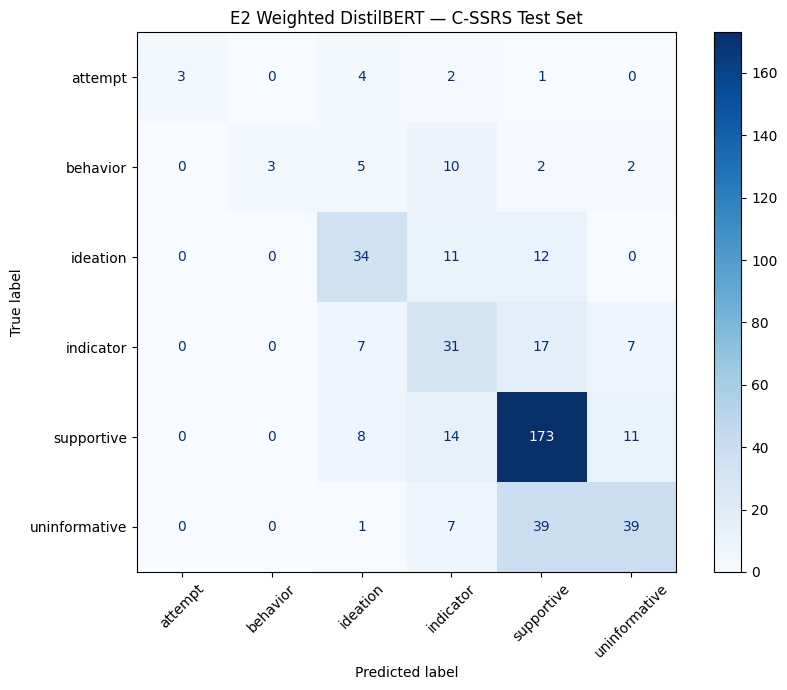


BINARY HIGH-RISK RESULTS
Actual high-risk posts: 32
Predicted high-risk posts: 6
Precision: 1.0000
Recall: 0.1875
F1-score: 0.3158


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Load saved test predictions
BASE = Path("/content/drive/MyDrive/mental-health-analysis")
predictions = pd.read_csv(BASE / "models/e2_test_predictions.csv")

# Six-class evaluation
y_true = predictions["risk_label"].str.lower()
y_pred = predictions["e2_prediction"].str.lower()

labels = [
    "attempt",
    "behavior",
    "ideation",
    "indicator",
    "supportive",
    "uninformative"
]

print("E2 TEST-SET RESULTS")
print("=" * 50)
print(f"Test posts: {len(predictions)}")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro-F1: {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted-F1: {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    zero_division=0,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(9, 7))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
display.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
ax.set_title("E2 Weighted DistilBERT — C-SSRS Test Set")
plt.tight_layout()
plt.show()

# Binary high-risk evaluation
high_risk_labels = {"behavior", "attempt"}
y_true_high = y_true.isin(high_risk_labels)
y_pred_high = y_pred.isin(high_risk_labels)

print("\nBINARY HIGH-RISK RESULTS")
print("=" * 50)
print("Actual high-risk posts:", int(y_true_high.sum()))
print("Predicted high-risk posts:", int(y_pred_high.sum()))
print(f"Precision: {precision_score(y_true_high, y_pred_high, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_true_high, y_pred_high, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_true_high, y_pred_high, zero_division=0):.4f}")

### Step 9: Evaluate High-Risk Ranking on the C-SSRS Test Set
**Objective:** Determine whether E2's combined `behavior` and `attempt` probability score can prioritize high-risk-labelled posts beyond its default class predictions.

We rank the 443 test posts by `high_risk_score` and inspect the top 30 candidates. We calculate precision, recall, and F1 at this fixed review budget.

This is a ranking evaluation, not a new threshold-selection exercise. We will not tune the model using these test results.

In [ ]:
# Use IPython's display function explicitly to avoid the naming conflict
from IPython.display import display as show_table

high_risk_in_top30 = top30.loc[
    top30["actual_high_risk"],
    ["post_id", "risk_label", "e2_prediction", "high_risk_score"]
]

print("Actual high-risk posts in the top 30:", len(high_risk_in_top30))
show_table(high_risk_in_top30)

Actual high-risk posts in the top 30: 14


,post_id,risk_label,e2_prediction,high_risk_score
0,279,attempt,attempt,0.930234
1,1193,behavior,behavior,0.867330
2,1375,attempt,attempt,0.604928
3,270,attempt,attempt,0.538417
4,2654,behavior,ideation,0.531202
5,1206,attempt,ideation,0.503656
6,1141,behavior,behavior,0.471586
7,1165,behavior,behavior,0.416039
16,814,behavior,ideation,0.220226
20,1209,behavior,indicator,0.184802


### Step 10: Compare C-SSRS Validation and Test Results
**Objective:** Compare E2's performance across the validation and held-out test datasets.

We compare accuracy, macro-F1, weighted-F1, default high-risk detection, and top-30 ranking performance.

This comparison helps us understand whether performance is consistent across splits. The validation and test datasets have different class distributions, so differences in scores must be interpreted in that context.

The test results will not be used to tune the model.

In [ ]:
comparison_results = pd.DataFrame([
    {"Metric": "Accuracy", "Validation": 0.6515, "Test": 0.6388},
    {"Metric": "Macro-F1", "Validation": 0.3374, "Test": 0.5079},
    {"Metric": "Weighted-F1", "Validation": 0.6450, "Test": 0.6231},
    {"Metric": "Actual high-risk posts", "Validation": 18, "Test": 32},
    {"Metric": "Default high-risk true positives", "Validation": 1, "Test": 6},
    {"Metric": "Top-30 true positives", "Validation": 5, "Test": 14},
    {"Metric": "Top-30 precision", "Validation": 5/30, "Test": 14/30},
    {"Metric": "Top-30 recall", "Validation": 5/18, "Test": 14/32},
])

show_table(comparison_results.round(4))

,Metric,Validation,Test
0,Accuracy,0.6515,0.6388
1,Macro-F1,0.3374,0.5079
2,Weighted-F1,0.6450,0.6231
3,Actual high-risk posts,18.0000,32.0000
4,Default high-risk true positives,1.0000,6.0000
5,Top-30 true positives,5.0000,14.0000
6,Top-30 precision,0.1667,0.4667
7,Top-30 recall,0.2778,0.4375


### Step 11: Save the C-SSRS Evaluation Summary
**Objective:** Save the validation-versus-test comparison as a CSV file for reproducibility and inclusion in the final-year project report.

The summary contains classification metrics and high-risk ranking results for the existing E2 Weighted DistilBERT model. It records the measured results without changing the model or its predictions.

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
MODELS = BASE / "models"
MODELS.mkdir(parents=True, exist_ok=True)

summary_path = MODELS / "e2_cssrs_validation_test_summary.csv"

comparison_results.to_csv(summary_path, index=False)

print("Evaluation summary saved to:")
print(summary_path)

print("\nSaved file preview:")
show_table(pd.read_csv(summary_path))

Evaluation summary saved to:
/content/drive/MyDrive/mental-health-analysis/models/e2_cssrs_validation_test_summary.csv

Saved file preview:


,Metric,Validation,Test
0,Accuracy,0.651500,0.638800
1,Macro-F1,0.337400,0.507900
2,Weighted-F1,0.645000,0.623100
3,Actual high-risk posts,18.000000,32.000000
4,Default high-risk true positives,1.000000,6.000000
5,Top-30 true positives,5.000000,14.000000
6,Top-30 precision,0.166667,0.466667
7,Top-30 recall,0.277778,0.437500


### Step 12: Save Detailed C-SSRS Test Evaluation Results
**Objective:** Save the per-class classification report and confusion matrix for E2 Weighted DistilBERT on the held-out test set.

The classification report provides precision, recall, F1-score, and support for all six classes. The confusion matrix shows which classes are correctly classified and which are confused with one another.

These outputs complement the overall metrics in `e2_cssrs_validation_test_summary.csv` and provide detailed evidence for the final project report.

In [ ]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
MODELS = BASE / "models"

# Load saved test predictions
predictions = pd.read_csv(MODELS / "e2_test_predictions.csv")

y_true = predictions["risk_label"].str.lower()
y_pred = predictions["e2_prediction"].str.lower()

labels = [
    "attempt",
    "behavior",
    "ideation",
    "indicator",
    "supportive",
    "uninformative"
]

# Save per-class classification metrics
report = classification_report(
    y_true,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_path = MODELS / "e2_cssrs_test_classification_report.csv"
report_df.to_csv(report_path)

# Save confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=[f"actual_{label}" for label in labels],
    columns=[f"predicted_{label}" for label in labels]
)

cm_path = MODELS / "e2_cssrs_test_confusion_matrix.csv"
cm_df.to_csv(cm_path)

print("Saved classification report:", report_path)
print("Saved confusion matrix:", cm_path)

print("\nPer-class test metrics:")
show_table(report_df.loc[labels].round(4))

print("\nConfusion matrix:")
show_table(cm_df)

Saved classification report: /content/drive/MyDrive/mental-health-analysis/models/e2_cssrs_test_classification_report.csv
Saved confusion matrix: /content/drive/MyDrive/mental-health-analysis/models/e2_cssrs_test_confusion_matrix.csv

Per-class test metrics:


,precision,recall,f1-score,support
attempt,1.0000,0.3000,0.4615,10.0
behavior,1.0000,0.1364,0.2400,22.0
ideation,0.5763,0.5965,0.5862,57.0
indicator,0.4133,0.5000,0.4526,62.0
supportive,0.7090,0.8398,0.7689,206.0
uninformative,0.6610,0.4535,0.5379,86.0



Confusion matrix:


,predicted_attempt,predicted_behavior,predicted_ideation,predicted_indicator,predicted_supportive,predicted_uninformative
actual_attempt,3,0,4,2,1,0
actual_behavior,0,3,5,10,2,2
actual_ideation,0,0,34,11,12,0
actual_indicator,0,0,7,31,17,7
actual_supportive,0,0,8,14,173,11
actual_uninformative,0,0,1,7,39,39


### Step 13: C-SSRS Dataset Leakage Audit
**Objective:** Check whether the C-SSRS training, validation, and test datasets contain overlapping records that could make evaluation results overly optimistic.

We will inspect:

- Exact duplicate text across dataset splits.
- Overlapping `post_id` values.
- Overlapping `user_id` values.

Overlapping posts can indicate data leakage. Overlapping users require additional interpretation because the appropriate split depends on whether the evaluation is intended to measure generalization to unseen posts or unseen users.

This audit is read-only. It will not modify the original datasets.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
CSSRS = BASE / "data/CSSRS"

# Load the three labelled splits
train_df = pd.read_parquet(CSSRS / "Copy of cssrs_train.parquet")
val_df = pd.read_parquet(CSSRS / "Copy of cssrs_val.parquet")
test_df = pd.read_parquet(CSSRS / "Copy of cssrs_test.parquet")

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

# Report dataset sizes and required columns
for name, df in splits.items():
    print(f"{name}: {len(df)} rows")
    print("  Columns:", df.columns.tolist())

# Check pairwise overlap
pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

print("\n--- POST ID OVERLAP ---")
for a, b in pairs:
    ids_a = set(splits[a]["post_id"].dropna())
    ids_b = set(splits[b]["post_id"].dropna())
    print(f"{a} vs {b}: {len(ids_a & ids_b)} shared post IDs")

print("\n--- USER ID OVERLAP ---")
for a, b in pairs:
    users_a = set(splits[a]["user_id"].dropna())
    users_b = set(splits[b]["user_id"].dropna())
    print(f"{a} vs {b}: {len(users_a & users_b)} shared users")

print("\n--- EXACT TEXT OVERLAP ---")
for a, b in pairs:
    texts_a = set(
        splits[a]["text"].dropna().astype(str).str.strip().str.lower()
    )
    texts_b = set(
        splits[b]["text"].dropna().astype(str).str.strip().str.lower()
    )
    shared_texts = texts_a & texts_b
    print(f"{a} vs {b}: {len(shared_texts)} shared exact texts")

train: 1815 rows
  Columns: ['post_id', 'user_id', 'text', 'risk_label', 'source_file']
validation: 482 rows
  Columns: ['post_id', 'user_id', 'text', 'risk_label', 'source_file']
test: 443 rows
  Columns: ['post_id', 'user_id', 'text', 'risk_label', 'source_file']

--- POST ID OVERLAP ---
train vs validation: 0 shared post IDs
train vs test: 0 shared post IDs
validation vs test: 0 shared post IDs

--- USER ID OVERLAP ---
train vs validation: 0 shared users
train vs test: 0 shared users
validation vs test: 0 shared users

--- EXACT TEXT OVERLAP ---
train vs validation: 0 shared exact texts
train vs test: 0 shared exact texts
validation vs test: 0 shared exact texts


### Step 14: Save C-SSRS Data Leakage Audit
**Objective:** Record the overlap checks between the training, validation, and test datasets.

The audit checks unique post IDs, user IDs, and normalized exact text. The results will be saved as a CSV file to support reproducibility and project documentation.

A zero-overlap result supports the integrity of the current split structure for these checks, but does not rule out near-duplicate content or other sources of leakage.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
CSSRS = BASE / "data/CSSRS"
MODELS = BASE / "models"

splits = {
    "train": pd.read_parquet(CSSRS / "Copy of cssrs_train.parquet"),
    "validation": pd.read_parquet(CSSRS / "Copy of cssrs_val.parquet"),
    "test": pd.read_parquet(CSSRS / "Copy of cssrs_test.parquet")
}

audit_rows = []

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    df_a, df_b = splits[a], splits[b]

    shared_ids = set(df_a["post_id"].dropna()) & set(df_b["post_id"].dropna())
    shared_users = set(df_a["user_id"].dropna()) & set(df_b["user_id"].dropna())

    texts_a = set(df_a["text"].dropna().astype(str).str.strip().str.lower())
    texts_b = set(df_b["text"].dropna().astype(str).str.strip().str.lower())
    shared_texts = texts_a & texts_b

    audit_rows.extend([
        {
            "comparison": f"{a} vs {b}",
            "check": "Shared post IDs",
            "overlap_count": len(shared_ids)
        },
        {
            "comparison": f"{a} vs {b}",
            "check": "Shared user IDs",
            "overlap_count": len(shared_users)
        },
        {
            "comparison": f"{a} vs {b}",
            "check": "Shared exact texts",
            "overlap_count": len(shared_texts)
        }
    ])

audit_df = pd.DataFrame(audit_rows)
output_path = MODELS / "cssrs_leakage_audit.csv"

audit_df.to_csv(output_path, index=False)

print("Audit saved to:", output_path)
show_table(audit_df)

Audit saved to: /content/drive/MyDrive/mental-health-analysis/models/cssrs_leakage_audit.csv


,comparison,check,overlap_count
0,train vs validation,Shared post IDs,0
1,train vs validation,Shared user IDs,0
2,train vs validation,Shared exact texts,0
3,train vs test,Shared post IDs,0
4,train vs test,Shared user IDs,0
5,train vs test,Shared exact texts,0
6,validation vs test,Shared post IDs,0
7,validation vs test,Shared user IDs,0
8,validation vs test,Shared exact texts,0


### Step 15: Inspect the RMHD Dataset
**Objective:** Inspect the processed RMHD dataset before applying the frozen C-SSRS E2 model.

We will check:
- Dataset size and available columns.
- Missing text and author values.
- Duplicate posts.
- Availability of timestamps and user identifiers.

This establishes whether the dataset is ready for inference and later temporal aggregation. We will not modify the original RMHD files.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/mental-health-analysis")

# Load the processed RMHD dataset
RMHD_PATH = BASE / "data/processed/rmhd_emotion_input.csv"
rmhd = pd.read_csv(RMHD_PATH)

print("RMHD dataset shape:", rmhd.shape)

print("\nColumns:")
print(rmhd.columns.tolist())

print("\nMissing values in important columns:")
for col in ["post_id", "author", "timestamp", "text"]:
    if col in rmhd.columns:
        print(f"{col}: {rmhd[col].isna().sum()}")

print("\nDuplicate post IDs:",
      rmhd["post_id"].duplicated().sum() if "post_id" in rmhd.columns else "Column unavailable")

print("\nDuplicate text rows:",
      rmhd["text"].duplicated().sum() if "text" in rmhd.columns else "Column unavailable")

print("\nUnique authors:",
      rmhd["author"].nunique() if "author" in rmhd.columns else "Column unavailable")



### Step 16: Inspect RMHD Samples and Duplicate Text
**Objective:** Examine representative RMHD posts and understand the repeated-text records before running model inference.

We will display a few posts using the notebook's explicit display function and inspect examples of repeated text alongside their post IDs and authors.

Repeated text will not be removed automatically because identical text may come from distinct posts or authors. We will preserve the original dataset until we understand the duplicates.

In [ ]:
from IPython.display import display as show_table

# Display representative posts
print("Sample RMHD posts:")
show_table(
    rmhd[["post_id", "author", "timestamp", "subreddit", "text"]].head(5)
)

# Inspect repeated text records
duplicate_mask = rmhd["text"].duplicated(keep=False)

duplicates = (
    rmhd.loc[
        duplicate_mask,
        ["post_id", "author", "timestamp", "subreddit", "text"]
    ]
    .sort_values("text")
)

print("\nRows whose text appears more than once:", len(duplicates))
print("Distinct repeated text strings:", rmhd.loc[duplicate_mask, "text"].nunique())

print("\nExamples of repeated text:")
show_table(duplicates.head(10))

### Step 17: Check C-SSRS and RMHD Dataset Overlap
**Objective:** Determine whether any labelled C-SSRS posts also appear in the RMHD corpus.

We will compare normalized text across the C-SSRS training, validation, and test datasets against RMHD.

This is a cross-dataset overlap check, not a claim that the datasets are independent in every possible way. We will report exact text matches and inspect any matches before deciding how they affect inference and evaluation.

No rows will be removed or modified.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
CSSRS = BASE / "data/CSSRS"
RMHD_PATH = BASE / "data/processed/rmhd_emotion_input.csv"

# Load labelled C-SSRS splits and RMHD
train_df = pd.read_parquet(CSSRS / "Copy of cssrs_train.parquet")
val_df = pd.read_parquet(CSSRS / "Copy of cssrs_val.parquet")
test_df = pd.read_parquet(CSSRS / "Copy of cssrs_test.parquet")
rmhd = pd.read_csv(RMHD_PATH)

# Normalize text consistently for exact-match comparison
def normalize_text(series):
    return (
        series.fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

rmhd = rmhd.copy()
rmhd["normalized_text"] = normalize_text(rmhd["text"])

cssrs_frames = []
for split_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    temp = df[["post_id", "user_id", "text", "risk_label"]].copy()
    temp["split"] = split_name
    temp["normalized_text"] = normalize_text(temp["text"])
    cssrs_frames.append(temp)

cssrs = pd.concat(cssrs_frames, ignore_index=True)

# Ignore empty text in the overlap calculation
cssrs_nonempty = cssrs[cssrs["normalized_text"] != ""]
rmhd_nonempty = rmhd[rmhd["normalized_text"] != ""]

shared_texts = set(cssrs_nonempty["normalized_text"]) & set(
    rmhd_nonempty["normalized_text"]
)

rmhd_matches = rmhd_nonempty[
    rmhd_nonempty["normalized_text"].isin(shared_texts)
]

print("Unique non-empty C-SSRS texts:", cssrs_nonempty["normalized_text"].nunique())
print("Unique non-empty RMHD texts:", rmhd_nonempty["normalized_text"].nunique())
print("Shared unique normalized texts:", len(shared_texts))
print("RMHD rows matching C-SSRS text:", len(rmhd_matches))

print("\nRMHD matches by subreddit:")
print(rmhd_matches["subreddit"].value_counts().head(10))

print("\nSample matching RMHD rows:")
display_cols = ["post_id", "author", "timestamp", "subreddit", "text"]
from IPython.display import display as show_table
show_table(rmhd_matches[display_cols].head(10))

### Step 18: Compare C-SSRS and RMHD Text Characteristics
**Objective:** Compare text length and vocabulary-related characteristics between the labelled C-SSRS dataset and RMHD.

We will measure:
- Character count per post.
- Word count per post.
- The proportion of very short and long posts.

These are basic domain-shift diagnostics. Similar text lengths do not prove that the datasets have the same language distribution, and differences do not automatically mean the model will fail. The results will help us decide whether further inspection is needed before interpreting RMHD predictions.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
CSSRS = BASE / "data/CSSRS"

# Load labelled C-SSRS data and RMHD
train_df = pd.read_parquet(CSSRS / "Copy of cssrs_train.parquet")
val_df = pd.read_parquet(CSSRS / "Copy of cssrs_val.parquet")
test_df = pd.read_parquet(CSSRS / "Copy of cssrs_test.parquet")
rmhd = pd.read_csv(BASE / "data/processed/rmhd_emotion_input.csv")

cssrs = pd.concat([train_df, val_df, test_df], ignore_index=True)

# Basic text characteristics
def add_text_features(df, text_col="text"):
    result = df.copy()
    text = result[text_col].fillna("").astype(str)
    result["char_count"] = text.str.len()
    result["word_count"] = text.str.split().str.len()
    return result

cssrs_features = add_text_features(cssrs)
rmhd_features = add_text_features(rmhd)

# Summarize distributions
rows = []

for name, df in [
    ("C-SSRS", cssrs_features),
    ("RMHD", rmhd_features)
]:
    rows.append({
        "Dataset": name,
        "Posts": len(df),
        "Median characters": df["char_count"].median(),
        "Median words": df["word_count"].median(),
        "Mean words": df["word_count"].mean(),
        "Posts under 5 words (%)": (df["word_count"] < 5).mean() * 100,
        "Posts over 200 words (%)": (df["word_count"] > 200).mean() * 100
    })

summary = pd.DataFrame(rows)

print("Text distribution comparison:")
show_table(summary.round(2))

### Step 19: Generate C-SSRS E2 Predictions for RMHD
**Objective:** Apply the frozen six-class E2 Weighted DistilBERT model to the RMHD corpus.

For each post, the model will generate:
- A predicted C-SSRS class.
- The probability assigned to each of the six classes.
- A combined high-risk score, calculated as `P(behavior) + P(attempt)`.

These outputs are model-generated signals, not verified clinical labels. RMHD does not have matching C-SSRS ground-truth labels for this evaluation, so predictions will be used for exploratory analysis and temporal feature construction rather than accuracy claims.

We will preserve all RMHD posts and save predictions to a separate file.

In [ ]:
import pandas as pd
import numpy as np
import torch
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
MODEL_PATH = BASE / "models/e2_weighted_distilbert/best_model"
RMHD_PATH = BASE / "data/processed/rmhd_emotion_input.csv"
OUTPUT_PATH = BASE / "models/e2_rmhd_predictions.csv"

# Load RMHD
rmhd = pd.read_csv(RMHD_PATH).reset_index(drop=True)

# Existing model label mapping
id2label = {
    0: "attempt",
    1: "behavior",
    2: "ideation",
    3: "indicator",
    4: "supportive",
    5: "uninformative"
}

# Load frozen model and tokenizer
tokenizer = AutoTokenizer.from_pretrained(str(MODEL_PATH))
model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_PATH)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

texts = rmhd["text"].fillna("").astype(str).tolist()
batch_size = 32
all_probs = []

print(f"Processing {len(texts):,} posts on {device}...")

# Batched inference
for start in range(0, len(texts), batch_size):
    batch_texts = texts[start:start + batch_size]

    encoded = tokenizer(
        batch_texts,
        truncation=True,
        padding=True,
        max_length=512,
        return_tensors="pt"
    )

    encoded = {k: v.to(device) for k, v in encoded.items()}

    with torch.no_grad():
        logits = model(**encoded).logits
        probs = torch.softmax(logits, dim=1)

    all_probs.append(probs.cpu().numpy())

    if (start // batch_size + 1) % 100 == 0:
        print(f"Processed {min(start + batch_size, len(texts)):,}/{len(texts):,}")

all_probs = np.concatenate(all_probs, axis=0)

# Build separate prediction output
predictions = rmhd.copy()
predicted_ids = all_probs.argmax(axis=1)

predictions["e2_prediction"] = [
    id2label[int(i)] for i in predicted_ids
]

for class_id, label in id2label.items():
    predictions[f"prob_{label}"] = all_probs[:, class_id]

predictions["high_risk_score"] = (
    predictions["prob_behavior"] +
    predictions["prob_attempt"]
)

# Save predictions without changing the original RMHD dataset
predictions.to_csv(OUTPUT_PATH, index=False)

print("\nInference complete.")
print("Saved to:", OUTPUT_PATH)
print("Output shape:", predictions.shape)

print("\nPredicted class distribution:")
print(predictions["e2_prediction"].value_counts())

print("\nHigh-risk score summary:")
print(predictions["high_risk_score"].describe())

print("\nFirst 5 predictions:")
from IPython.display import display as show_table
show_table(
    predictions[
        ["post_id", "author", "timestamp", "e2_prediction", "high_risk_score"]
    ].head(5)
)

### Step 20: Analyze E2 Predictions on RMHD
**Objective:** Examine the predicted class distribution and high-risk scores produced by the frozen E2 model across the RMHD corpus.

We will:
- Calculate the percentage of posts assigned to each predicted class.
- Summarize the combined high-risk score, defined as `P(behavior) + P(attempt)`.
- Compare the high-risk score distribution across subreddits.
- Examine the proportion of posts above selected score cutoffs as a descriptive analysis, not as validated risk thresholds.

Because RMHD does not have matching C-SSRS ground-truth labels, these results describe model outputs rather than measured classification accuracy or actual mental-health risk prevalence.

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
PRED_PATH = BASE / "models/e2_rmhd_predictions.csv"

predictions = pd.read_csv(PRED_PATH)

# 1. Predicted class distribution
class_summary = (
    predictions["e2_prediction"]
    .value_counts()
    .rename_axis("Predicted class")
    .reset_index(name="Posts")
)

class_summary["Percentage"] = (
    class_summary["Posts"] / len(predictions) * 100
)

print("Predicted class distribution:")
show_table(class_summary.round(2))

# 2. Combined high-risk score summary
print("\nCombined high-risk score summary:")
print(predictions["high_risk_score"].describe().round(4))

# 3. Descriptive score cutoffs — not validated thresholds
for cutoff in [0.5, 0.7, 0.9]:
    count = (predictions["high_risk_score"] >= cutoff).sum()
    print(
        f"Score >= {cutoff:.1f}: {count:,} posts "
        f"({count / len(predictions) * 100:.2f}%)"
    )

# 4. High-risk score by subreddit
subreddit_summary = (
    predictions.groupby("subreddit")
    .agg(
        posts=("post_id", "size"),
        mean_score=("high_risk_score", "mean"),
        median_score=("high_risk_score", "median"),
        predicted_high_risk_pct=(
            "e2_prediction",
            lambda s: s.isin(["behavior", "attempt"]).mean() * 100
        )
    )
    .sort_values("posts", ascending=False)
    .reset_index()
)

print("\nSubreddit summary — 15 largest subreddits:")
show_table(subreddit_summary.head(15).round(3))

Predicted class distribution:


,Predicted class,Posts,Percentage
0,uninformative,18506,22.16
1,indicator,16680,19.97
2,behavior,16454,19.70
3,ideation,16031,19.20
4,supportive,10463,12.53
5,attempt,5382,6.44



Combined high-risk score summary:
count    83516.0000
mean         0.2999
std          0.2594
min          0.0062
25%          0.0683
50%          0.2127
75%          0.5065
max          0.9708
Name: high_risk_score, dtype: float64
Score >= 0.5: 21,312 posts (25.52%)
Score >= 0.7: 8,922 posts (10.68%)
Score >= 0.9: 486 posts (0.58%)

Subreddit summary — 15 largest subreddits:


,subreddit,posts,mean_score,median_score,predicted_high_risk_pct
0,depression,29366,0.299,0.225,24.293
1,SuicideWatch,21334,0.380,0.348,36.139
2,Anxiety,12013,0.295,0.219,28.378
3,mentalhealth,10463,0.294,0.201,26.608
4,lonely,6638,0.160,0.086,7.713
5,If anyone is afraid to call a suicide hotline ...,9,0.449,0.508,66.667
6,.,9,0.069,0.057,0.000
7,Rejected from the only job I've wanted,6,0.258,0.256,0.000
8,A suicide note and a message.,6,0.612,0.605,100.000
9,My bestfriend and I made a suicide pact.,6,0.660,0.663,100.000


### Step 21: Inspect Existing Temporal Analysis Outputs
**Objective:** Locate and inspect the previously generated 90-day and 180-day temporal feature files.

We will check their dimensions, column names, and sample rows to determine how the existing user-level temporal features are organized.

We will also inspect the post-level temporal file to identify the keys used to connect post-level E2 predictions to the existing analysis.

This step is read-only. We will not modify any existing temporal outputs.

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

files_to_inspect = [
    "temporal_features_90d_180d.csv",
    "post_level_temporal_90d_180d.csv"
]

for filename in files_to_inspect:
    path = RESULTS / filename

    print("\n" + "=" * 70)
    print("File:", filename)

    if not path.exists():
        print("File not found:", path)
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nSample rows:")
    show_table(df.head(3))

    print("\nMissing values in first 15 columns:")
    show_table(df.iloc[:, :15].isna().sum().to_frame("missing_count"))

### Step 22: Match E2 Predictions with Existing Temporal Records
**Objective:** Connect the saved E2 predictions to the existing post-level temporal analysis using `post_id`.

We will check:
- Whether `post_id` is unique in each file.
- How many temporal-analysis posts have matching E2 predictions.
- Whether the author identifiers agree for matched posts.
- How many posts are represented in each temporal window.

This is a read-only integration check. We will not overwrite the original temporal files or assume that every RMHD post belongs to the existing temporal-analysis subset.

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"
MODELS = BASE / "models"

# Load existing temporal records and E2 predictions
temporal = pd.read_csv(
    RESULTS / "post_level_temporal_90d_180d.csv"
)

e2 = pd.read_csv(
    MODELS / "e2_rmhd_predictions.csv"
)

print("Temporal records:", temporal.shape)
print("E2 predictions:", e2.shape)

# Check key uniqueness
print("\nDuplicate post IDs:")
print("Temporal:", temporal["post_id"].duplicated().sum())
print("E2:", e2["post_id"].duplicated().sum())

# Match on post_id without changing either original file
matched = temporal.merge(
    e2[["post_id", "author", "high_risk_score", "e2_prediction"]],
    on="post_id",
    how="left",
    suffixes=("_temporal", "_e2"),
    validate="many_to_one",
    indicator=True
)

matched_count = (matched["_merge"] == "both").sum()
unmatched_count = (matched["_merge"] == "left_only").sum()

print("\nTemporal posts matched to E2:", matched_count)
print("Temporal posts without E2 match:", unmatched_count)
print(
    "Match percentage:",
    round(matched_count / len(temporal) * 100, 2),
    "%"
)

# Check author consistency for matched posts
valid = matched[matched["_merge"] == "both"]

if len(valid):
    author_mismatch = (
        valid["author_temporal"].astype(str)
        != valid["author_e2"].astype(str)
    )

    print("\nAuthor mismatches among matched posts:", author_mismatch.sum())

# Inspect existing temporal windows
if "window" in temporal.columns:
    print("\nTemporal window distribution:")
    show_table(
        temporal["window"].value_counts(dropna=False).rename_axis("window")
        .reset_index(name="rows")
    )

print("\nMatched record preview:")
show_table(
    matched.loc[
        matched["_merge"] == "both",
        [
            "post_id",
            "author_temporal",
            "timestamp",
            "window",
            "high_risk_score",
            "e2_prediction"
        ]
    ].head(5)
)

### Temporal Change in Predicted Risk Scores
This step compares E2-predicted risk scores between the baseline
and recent windows for each user.

For each user, calculate:
- Mean baseline risk score
- Mean recent risk score
- Change in risk score (recent minus baseline)
- Number of posts in each window

A positive change indicates that the average model-predicted risk
score increased in the recent window. A negative change indicates
that it decreased.

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"
MODELS = BASE / "models"

temporal = pd.read_csv(RESULTS / "post_level_temporal_90d_180d.csv")
e2 = pd.read_csv(MODELS / "e2_rmhd_predictions.csv")

# Attach E2 scores to the temporal records
matched = temporal.merge(
    e2[["post_id", "high_risk_score"]],
    on="post_id",
    how="left",
    validate="many_to_one"
)

# Confirm scores are available
print("Missing E2 risk scores:", matched["high_risk_score"].isna().sum())

# Summarize risk scores and post counts for each user/window
user_window = (
    matched.groupby(["author", "window"], as_index=False)
    .agg(
        mean_risk_score=("high_risk_score", "mean"),
        median_risk_score=("high_risk_score", "median"),
        post_count=("post_id", "count")
    )
)

# Convert baseline and recent windows into columns
wide = user_window.pivot(
    index="author",
    columns="window",
    values=["mean_risk_score", "median_risk_score", "post_count"]
)

wide.columns = [
    f"{metric}_{window}" for metric, window in wide.columns
]
wide = wide.reset_index()
wide.columns.name = None

# Calculate change only for users with both windows
required = ["mean_risk_score_baseline", "mean_risk_score_recent"]
both_windows = wide.dropna(subset=required).copy()

both_windows["mean_risk_change"] = (
    both_windows["mean_risk_score_recent"]
    - both_windows["mean_risk_score_baseline"]
)

print("Users represented in temporal records:", len(wide))
print("Users with both baseline and recent windows:", len(both_windows))
print("Users missing one or both windows:", len(wide) - len(both_windows))

print("\nSummary of user-level mean risk-score changes:")
show_table(
    both_windows["mean_risk_change"]
    .describe()
    .to_frame("mean_risk_change")
    .round(4)
)

print("\nUsers with the largest increases:")
show_table(
    both_windows.sort_values("mean_risk_change", ascending=False)
    [[
        "author",
        "post_count_baseline",
        "post_count_recent",
        "mean_risk_score_baseline",
        "mean_risk_score_recent",
        "mean_risk_change"
    ]]
    .head(10)
    .round(4)
)

print("\nUsers with the largest decreases:")
show_table(
    both_windows.sort_values("mean_risk_change", ascending=True)
    [[
        "author",
        "post_count_baseline",
        "post_count_recent",
        "mean_risk_score_baseline",
        "mean_risk_score_recent",
        "mean_risk_change"
    ]]
    .head(10)
    .round(4)
)

# Save results for subsequent analysis
output_path = RESULTS / "user_level_e2_temporal_risk_changes.csv"
both_windows.to_csv(output_path, index=False)
print("\nSaved:", output_path)

### Step 24: Robustness Check for Temporal Risk Changes
Users have different numbers of posts in their baseline and recent
windows. A mean calculated from very few posts may be unstable.

This step:
1. Summarizes posting activity in both windows.
2. Counts users meeting minimum-post requirements.
3. Compares risk-score changes for users with at least 5 posts
   and at least 10 posts in each window.

These are sensitivity analyses, not clinically validated thresholds.

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

users = pd.read_csv(
    RESULTS / "user_level_e2_temporal_risk_changes.csv"
)

# Inspect posting activity in each window
activity_columns = [
    "post_count_baseline",
    "post_count_recent"
]

print("Posting activity summary:")
show_table(users[activity_columns].describe().round(2))

# Compare increasingly strict minimum-post requirements
checks = []

for minimum_posts in [1, 5, 10]:
    subset = users[
        (users["post_count_baseline"] >= minimum_posts)
        & (users["post_count_recent"] >= minimum_posts)
    ]

    checks.append({
        "minimum_posts_per_window": minimum_posts,
        "users_retained": len(subset),
        "mean_risk_change": subset["mean_risk_change"].mean(),
        "median_risk_change": subset["mean_risk_change"].median(),
        "std_risk_change": subset["mean_risk_change"].std(),
        "users_with_increase": (subset["mean_risk_change"] > 0).sum(),
        "users_with_decrease": (subset["mean_risk_change"] < 0).sum(),
        "users_unchanged": (subset["mean_risk_change"] == 0).sum()
    })

comparison = pd.DataFrame(checks)

print("\nSensitivity analysis:")
show_table(comparison.round(4))

# Save the sensitivity analysis
output_path = RESULTS / "temporal_risk_activity_sensitivity.csv"
comparison.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Posting activity summary:


,post_count_baseline,post_count_recent
count,258.00,258.00
mean,43.14,21.36
std,76.05,29.14
min,15.00,5.00
25%,20.00,9.00
50%,27.00,14.00
75%,44.75,24.00
max,1072.00,289.00



Sensitivity analysis:


,minimum_posts_per_window,users_retained,mean_risk_change,median_risk_change,std_risk_change,users_with_increase,users_with_decrease,users_unchanged
0,1,258,-0.0120,-0.0150,0.0993,105,153,0
1,5,258,-0.0120,-0.0150,0.0993,105,153,0
2,10,170,-0.0134,-0.0122,0.0838,68,102,0



Saved: /content/drive/MyDrive/mental-health-analysis/results/temporal_risk_activity_sensitivity.csv


### Step 25: Association Between Emotion Changes and Predicted Risk Changes
Compare baseline-to-recent changes in E2 risk scores with changes
in the existing GoEmotions features.

For each user:
- Calculate recent minus baseline emotion scores.
- Compare each emotion change with the change in E2 mean risk score.
- Report correlation coefficients and sample sizes.

These associations are exploratory. They do not establish causation
or confirm a person's mental-health condition.

In [ ]:
import pandas as pd
from pathlib import Path
from scipy.stats import spearmanr
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

# Load the existing temporal emotion features and risk changes
emotions = pd.read_csv(RESULTS / "temporal_features_90d_180d.csv")
risk = pd.read_csv(RESULTS / "user_level_e2_temporal_risk_changes.csv")

print("Emotion feature dataset:", emotions.shape)
print("Risk change dataset:", risk.shape)
print("\nEmotion columns:")
print(emotions.columns.tolist())

# Identify emotion features with baseline and recent values
emotion_names = [
    col[len("baseline_"):]
    for col in emotions.columns
    if col.startswith("baseline_")
    and f"recent_{col[len('baseline_'):]}" in emotions.columns
]

print("\nNumber of matched emotion features:", len(emotion_names))
print("Matched emotion names:", emotion_names)

# Create recent-minus-baseline changes for each emotion
emotion_changes = emotions[["author"]].copy()

for emotion in emotion_names:
    emotion_changes[f"delta_{emotion}"] = (
        emotions[f"recent_{emotion}"] - emotions[f"baseline_{emotion}"]
    )

# Merge with E2 risk changes by user
combined = risk.merge(
    emotion_changes,
    on="author",
    how="inner",
    validate="one_to_one"
)

print("\nUsers matched:", len(combined))
print("Missing risk changes:", combined["mean_risk_change"].isna().sum())

# Spearman correlations between each emotion change and risk change
results = []

for emotion in emotion_names:
    col = f"delta_{emotion}"
    valid = combined[["mean_risk_change", col]].dropna()

    if len(valid) >= 3 and valid[col].nunique() > 1:
        rho, p_value = spearmanr(
            valid["mean_risk_change"],
            valid[col]
        )
        results.append({
            "emotion": emotion,
            "spearman_rho": rho,
            "p_value_uncorrected": p_value,
            "users": len(valid)
        })

correlations = pd.DataFrame(results)

if not correlations.empty:
    correlations["abs_rho"] = correlations["spearman_rho"].abs()
    correlations = correlations.sort_values("abs_rho", ascending=False)

    print("\nStrongest exploratory associations:")
    show_table(
        correlations.drop(columns="abs_rho").head(15).round(4)
    )

    output_path = RESULTS / "emotion_risk_change_correlations.csv"
    correlations.to_csv(output_path, index=False)
    print("\nSaved:", output_path)
else:
    print("No eligible emotion correlations could be calculated.")

### Correct Emotion Associations and Multiple-Testing Correction
Exclude post counts from the emotion analysis because posting activity
is not an emotion.

Recalculate Spearman correlations for the 28 GoEmotions features.
Apply the Benjamini–Hochberg false-discovery-rate correction to account
for testing multiple emotion features.

Report both raw p-values and adjusted p-values.

In [ ]:
import pandas as pd
from pathlib import Path
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

emotions = pd.read_csv(RESULTS / "temporal_features_90d_180d.csv")
risk = pd.read_csv(RESULTS / "user_level_e2_temporal_risk_changes.csv")

# Keep only actual emotion labels, excluding the post-count feature
emotion_names = [
    col.removeprefix("baseline_")
    for col in emotions.columns
    if col.startswith("baseline_")
    and col != "baseline_posts"
    and f"recent_{col.removeprefix('baseline_')}" in emotions.columns
    and col.removeprefix("baseline_") != "posts"
]

emotion_changes = emotions[["author"]].copy()

for emotion in emotion_names:
    emotion_changes[f"delta_{emotion}"] = (
        emotions[f"recent_{emotion}"] - emotions[f"baseline_{emotion}"]
    )

combined = risk.merge(
    emotion_changes,
    on="author",
    how="inner",
    validate="one_to_one"
)

results = []

for emotion in emotion_names:
    col = f"delta_{emotion}"
    valid = combined[["mean_risk_change", col]].dropna()

    rho, p_value = spearmanr(
        valid["mean_risk_change"],
        valid[col]
    )

    results.append({
        "emotion": emotion,
        "spearman_rho": rho,
        "p_value": p_value,
        "users": len(valid)
    })

correlations = pd.DataFrame(results)

# Correct for testing 28 emotions
correlations["p_adjusted_BH"] = multipletests(
    correlations["p_value"],
    method="fdr_bh"
)[1]

correlations["significant_after_BH"] = (
    correlations["p_adjusted_BH"] < 0.05
)

correlations["abs_rho"] = correlations["spearman_rho"].abs()
correlations = correlations.sort_values("abs_rho", ascending=False)

print("Emotion features tested:", len(emotion_names))
print("Users included:", len(combined))
print(
    "Features significant after BH correction:",
    int(correlations["significant_after_BH"].sum())
)

show_table(
    correlations[
        [
            "emotion",
            "spearman_rho",
            "p_value",
            "p_adjusted_BH",
            "significant_after_BH",
            "users"
        ]
    ].round(4)
)

output_path = RESULTS / "emotion_risk_change_correlations_corrected.csv"
correlations.drop(columns="abs_rho").to_csv(output_path, index=False)

print("\nSaved:", output_path)

Emotion features tested: 28
Users included: 258
Features significant after BH correction: 6


,emotion,spearman_rho,p_value,p_adjusted_BH,significant_after_BH,users
19,nervousness,0.2628,0.0000,0.0005,True,258
14,fear,0.2428,0.0001,0.0011,True,258
9,disappointment,0.2141,0.0005,0.0050,True,258
27,neutral,-0.2046,0.0009,0.0066,True,258
12,embarrassment,0.1980,0.0014,0.0078,True,258
7,curiosity,-0.1704,0.0061,0.0283,True,258
22,realization,0.1441,0.0206,0.0727,False,258
16,grief,0.1439,0.0208,0.0727,False,258
24,remorse,0.1358,0.0292,0.0909,False,258
21,pride,0.1235,0.0476,0.1332,False,258



Saved: /content/drive/MyDrive/mental-health-analysis/results/emotion_risk_change_correlations_corrected.csv


### Combined Temporal Behavioural Feature Dataset
Combine the existing user-level emotion features with E2 risk-score
changes and posting activity.

The dataset will contain:
- Baseline and recent emotion scores
- Emotion changes
- Baseline and recent E2 risk scores
- E2 risk-score change
- Baseline and recent post counts

This dataset will be used for subsequent behavioural pattern analysis.

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

# Load existing outputs
emotions = pd.read_csv(RESULTS / "temporal_features_90d_180d.csv")
risk = pd.read_csv(RESULTS / "user_level_e2_temporal_risk_changes.csv")

# Keep one row per author in each dataset
assert emotions["author"].is_unique, "Duplicate authors in emotion dataset"
assert risk["author"].is_unique, "Duplicate authors in risk dataset"

# Combine without discarding users
combined = emotions.merge(
    risk,
    on="author",
    how="outer",
    validate="one_to_one",
    indicator=True,
    suffixes=("_emotion", "_risk")
)

print("Merge status:")
show_table(combined["_merge"].value_counts().rename_axis("merge_status").reset_index(name="users"))

# Check that every author exists in both source datasets
assert (combined["_merge"] == "both").all(), "Some authors are unmatched"

combined = combined.drop(columns="_merge")

# Validate key features
required_columns = [
    "author",
    "baseline_posts",
    "recent_posts",
    "mean_risk_score_baseline",
    "mean_risk_score_recent",
    "mean_risk_change"
]

missing_columns = [c for c in required_columns if c not in combined.columns]
assert not missing_columns, f"Missing expected columns: {missing_columns}"

# Check missing values and duplicate authors
print("\nCombined dataset shape:", combined.shape)
print("Unique authors:", combined["author"].nunique())
print("Duplicate author rows:", combined["author"].duplicated().sum())
print("Total missing values:", int(combined.isna().sum().sum()))

print("\nRisk and activity feature preview:")
show_table(combined[required_columns].head(10).round(4))

# Save a new file; source files remain unchanged
output_path = RESULTS / "combined_temporal_behavioural_features.csv"
combined.to_csv(output_path, index=False)

print("\nSaved:", output_path)

### Exploratory Analysis of Temporal Behavioural Features
Examine the distribution of baseline and recent E2 risk scores,
the changes in risk scores, and the changes in emotional features.

The objective is to understand the overall patterns, variability,
and relationships in the combined dataset before developing
the experimental early-warning logic.

Summary statistics:


,mean_risk_score_baseline,mean_risk_score_recent,mean_risk_change,post_count_baseline,post_count_recent
count,258.0000,258.0000,258.0000,258.0000,258.0000
mean,0.3411,0.3291,-0.0120,43.1357,21.3566
std,0.1361,0.1554,0.0993,76.0518,29.1411
min,0.0132,0.0128,-0.3641,15.0000,5.0000
25%,0.2535,0.2138,-0.0743,20.0000,9.0000
50%,0.3454,0.3246,-0.0150,27.0000,14.0000
75%,0.4436,0.4412,0.0540,44.7500,24.0000
max,0.7067,0.7024,0.3011,1072.0000,289.0000


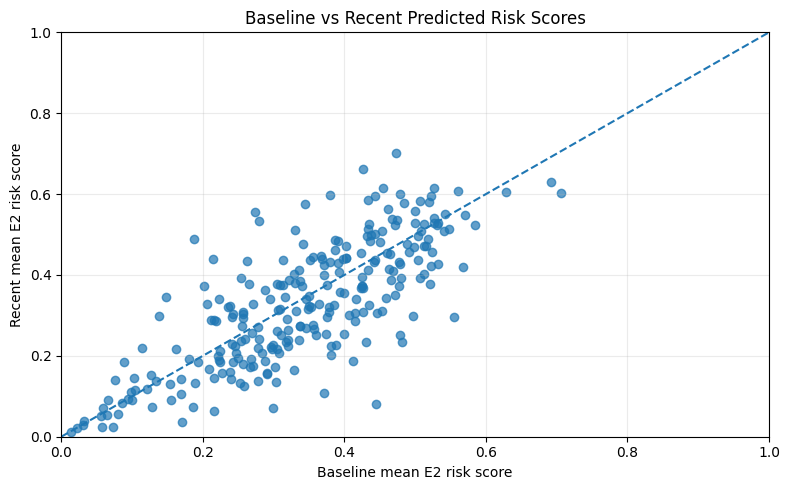

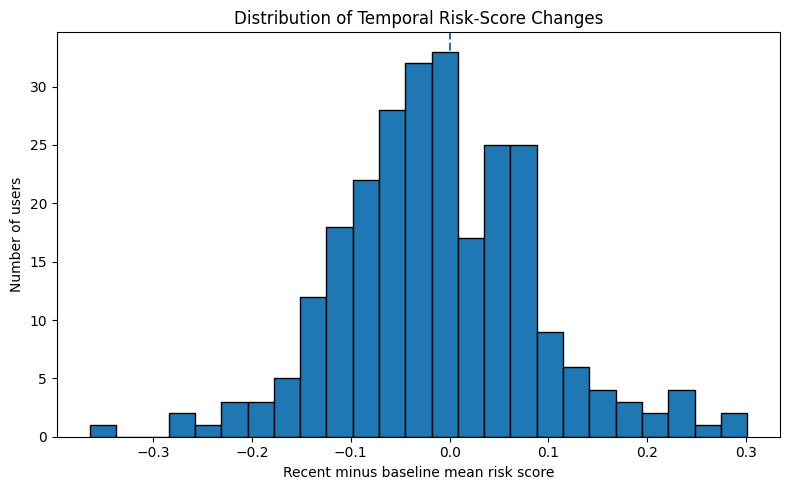


Mean changes in emotion features:


,emotion_feature,mean_change
0,delta_disappointment,-0.0060
1,delta_sadness,-0.0045
2,delta_fear,-0.0039
3,delta_desire,-0.0025
4,delta_confusion,-0.0023
5,delta_joy,-0.0016
6,delta_remorse,-0.0016
7,delta_excitement,-0.0014
8,delta_realization,-0.0008
9,delta_embarrassment,-0.0005


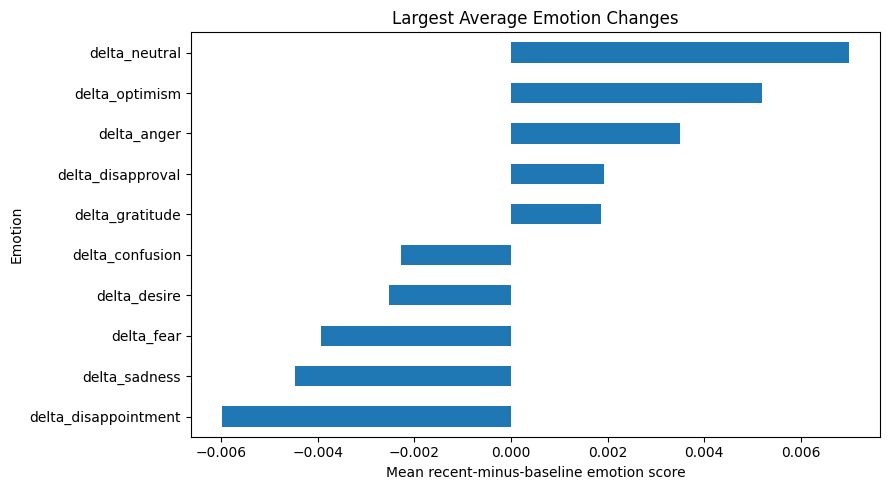

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

df = pd.read_csv(
    RESULTS / "combined_temporal_behavioural_features.csv"
)

# Summary statistics for risk scores and posting activity
summary_columns = [
    "mean_risk_score_baseline",
    "mean_risk_score_recent",
    "mean_risk_change",
    "post_count_baseline",
    "post_count_recent"
]

print("Summary statistics:")
show_table(df[summary_columns].describe().round(4))

# Compare baseline and recent risk scores
plt.figure(figsize=(8, 5))
plt.scatter(
    df["mean_risk_score_baseline"],
    df["mean_risk_score_recent"],
    alpha=0.7
)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Baseline mean E2 risk score")
plt.ylabel("Recent mean E2 risk score")
plt.title("Baseline vs Recent Predicted Risk Scores")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Distribution of changes in predicted risk scores
plt.figure(figsize=(8, 5))
plt.hist(df["mean_risk_change"], bins=25, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Recent minus baseline mean risk score")
plt.ylabel("Number of users")
plt.title("Distribution of Temporal Risk-Score Changes")
plt.tight_layout()
plt.show()

# Average changes in emotional features
emotion_columns = [
    col for col in df.columns
    if col.startswith("delta_")
    and col != "delta_posts"
]

emotion_summary = (
    df[emotion_columns]
    .mean()
    .sort_values()
)

print("\nMean changes in emotion features:")
show_table(
    emotion_summary.rename_axis("emotion_feature")
    .reset_index(name="mean_change")
    .round(4)
)

# Plot the 10 largest average increases and decreases
selected = pd.concat([
    emotion_summary.head(5),
    emotion_summary.tail(5)
]).sort_values()

plt.figure(figsize=(9, 5))
selected.plot(kind="barh")
plt.xlabel("Mean recent-minus-baseline emotion score")
plt.ylabel("Emotion")
plt.title("Largest Average Emotion Changes")
plt.tight_layout()
plt.show()

### Individual-Level Behavioural Pattern Analysis
Examine users' changes in predicted risk scores alongside changes
in the six emotion features associated with risk-score changes
after Benjamini–Hochberg correction.

Identify:
- Users with the largest increases in predicted risk scores
- Users with the largest decreases
- Their corresponding changes in nervousness, fear, disappointment,
  neutral emotion, embarrassment, and curiosity

These are exploratory examples, not individual mental-health
assessments or validated warnings.

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

df = pd.read_csv(
    RESULTS / "combined_temporal_behavioural_features.csv"
)

selected_emotions = [
    "nervousness",
    "fear",
    "disappointment",
    "neutral",
    "embarrassment",
    "curiosity"
]

columns = (
    ["author", "post_count_baseline", "post_count_recent",
     "mean_risk_score_baseline", "mean_risk_score_recent",
     "mean_risk_change"]
    + [f"delta_{emotion}" for emotion in selected_emotions]
)

# Users with the largest risk-score increases
increases = (
    df.sort_values("mean_risk_change", ascending=False)
    [columns]
    .head(10)
)

# Users with the largest risk-score decreases
decreases = (
    df.sort_values("mean_risk_change", ascending=True)
    [columns]
    .head(10)
)

print("Users with the largest increases:")
show_table(increases.round(4))

print("\nUsers with the largest decreases:")
show_table(decreases.round(4))

### Exploratory Multivariable Analysis of Temporal Behavioural Features
Examine whether changes in six emotion features jointly relate to
changes in E2-predicted risk scores, while accounting for posting activity.

Predictor features:
- Change in nervousness
- Change in fear
- Change in disappointment
- Change in neutral emotion
- Change in embarrassment
- Change in curiosity
- Change in posting activity

Outcome:
- Change in mean E2-predicted risk score

Report model fit, coefficients, confidence intervals, and p-values.
Interpret results as exploratory associations, not clinical predictions.

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from pathlib import Path
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

df = pd.read_csv(
    RESULTS / "combined_temporal_behavioural_features.csv"
)

emotion_features = [
    "delta_nervousness",
    "delta_fear",
    "delta_disappointment",
    "delta_neutral",
    "delta_embarrassment",
    "delta_curiosity"
]

# Use relative change in post counts to account for different
# baseline activity levels without using raw counts alone.
df["post_activity_change"] = (
    (df["recent_posts"] - df["baseline_posts"])
    / df["baseline_posts"].replace(0, np.nan)
)

predictors = emotion_features + ["post_activity_change"]
outcome = "mean_risk_change"

analysis = df[[outcome] + predictors].replace(
    [np.inf, -np.inf], np.nan
).dropna()

X = sm.add_constant(analysis[predictors])
y = analysis[outcome]

model = sm.OLS(y, X).fit()

print("Users included:", len(analysis))
print("R-squared:", round(model.rsquared, 4))
print("Adjusted R-squared:", round(model.rsquared_adj, 4))
print("Overall model p-value:", f"{model.f_pvalue:.6g}")

# Coefficients and confidence intervals
confidence = model.conf_int()
results = pd.DataFrame({
    "feature": model.params.index,
    "coefficient": model.params.values,
    "p_value": model.pvalues.values,
    "ci_lower": confidence[0].values,
    "ci_upper": confidence[1].values
})

results = results[results["feature"] != "const"]
results = results.sort_values("p_value")

print("\nPredictor results:")
show_table(results.round(4))

# Save results for the project report
output_path = RESULTS / "multivariable_temporal_association_results.csv"
results.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Users included: 258
R-squared: 0.1622
Adjusted R-squared: 0.1388
Overall model p-value: 1.56946e-07

Predictor results:


,feature,coefficient,p_value,ci_lower,ci_upper
3,delta_disappointment,0.4234,0.0000,0.2262,0.6205
2,delta_fear,0.2966,0.0092,0.0739,0.5193
6,delta_curiosity,-0.1703,0.1088,-0.3786,0.0381
1,delta_nervousness,0.2040,0.1508,-0.0748,0.4828
5,delta_embarrassment,0.4433,0.1910,-0.2226,1.1093
4,delta_neutral,-0.1037,0.2420,-0.2778,0.0704
7,post_activity_change,-0.0071,0.4975,-0.0277,0.0135



Saved: /content/drive/MyDrive/mental-health-analysis/results/multivariable_temporal_association_results.csv


### Regression Diagnostics and Robustness Checks
Evaluate the multivariable temporal association model by checking:

1. Multicollinearity among predictor features using VIF.
2. Influential observations using Cook's distance.
3. Residual patterns and heteroscedasticity.
4. HC3 heteroscedasticity-robust standard errors.

Compare the ordinary and robust coefficient results to determine
whether the associations involving disappointment and fear remain
statistically significant under these checks.

Variance inflation factors:


,feature,VIF
0,delta_nervousness,1.414
1,delta_fear,1.454
2,delta_disappointment,1.232
3,delta_neutral,1.173
4,delta_embarrassment,1.058
5,delta_curiosity,1.067
6,post_activity_change,1.016



Ordinary vs HC3-robust results:


,feature,coefficient,ordinary_p_value,HC3_robust_p_value,HC3_CI_lower,HC3_CI_upper
0,delta_nervousness,0.2040,0.1508,0.1428,-0.0693,0.4773
1,delta_fear,0.2966,0.0092,0.0582,-0.0104,0.6036
2,delta_disappointment,0.4234,0.0000,0.0004,0.1889,0.6579
3,delta_neutral,-0.1037,0.2420,0.2339,-0.2748,0.0674
4,delta_embarrassment,0.4433,0.1910,0.2548,-0.3217,1.2084
5,delta_curiosity,-0.1703,0.1088,0.1969,-0.4294,0.0889
6,post_activity_change,-0.0071,0.4975,0.4676,-0.0264,0.0121



Influence summary:
Cook's distance threshold (4/n): 0.0155
Observations above threshold: 25
Maximum Cook's distance: 0.09025

Breusch-Pagan test p-value: 0.687791


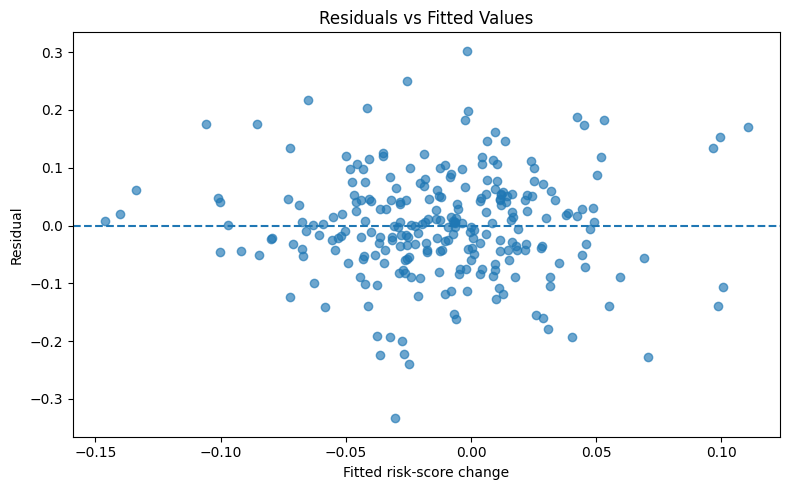


Saved: /content/drive/MyDrive/mental-health-analysis/results/multivariable_temporal_robustness_results.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from pathlib import Path
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor,
    OLSInfluence
)
from statsmodels.stats.diagnostic import het_breuschpagan
from IPython.display import display as show_table

BASE = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = BASE / "results"

df = pd.read_csv(
    RESULTS / "combined_temporal_behavioural_features.csv"
)

emotion_features = [
    "delta_nervousness",
    "delta_fear",
    "delta_disappointment",
    "delta_neutral",
    "delta_embarrassment",
    "delta_curiosity"
]

df["post_activity_change"] = (
    (df["recent_posts"] - df["baseline_posts"])
    / df["baseline_posts"].replace(0, np.nan)
)

predictors = emotion_features + ["post_activity_change"]
outcome = "mean_risk_change"

analysis = df[[outcome] + predictors].replace(
    [np.inf, -np.inf], np.nan
).dropna()

X = sm.add_constant(analysis[predictors])
y = analysis[outcome]

model = sm.OLS(y, X).fit()
robust_model = model.get_robustcov_results(cov_type="HC3")

# 1. Multicollinearity
vif_table = pd.DataFrame({
    "feature": predictors,
    "VIF": [
        variance_inflation_factor(X[predictors].values, i)
        for i in range(len(predictors))
    ]
})

print("Variance inflation factors:")
show_table(vif_table.round(3))

# 2. Compare ordinary and HC3-robust inference
robust_results = pd.DataFrame({
    "feature": predictors,
    "coefficient": [robust_model.params[X.columns.get_loc(c)] for c in predictors],
    "ordinary_p_value": [model.pvalues[c] for c in predictors],
    "HC3_robust_p_value": [
        robust_model.pvalues[X.columns.get_loc(c)] for c in predictors
    ],
    "HC3_CI_lower": [
        robust_model.conf_int()[X.columns.get_loc(c), 0] for c in predictors
    ],
    "HC3_CI_upper": [
        robust_model.conf_int()[X.columns.get_loc(c), 1] for c in predictors
    ]
})

print("\nOrdinary vs HC3-robust results:")
show_table(robust_results.round(4))

# 3. Influence diagnostics
influence = OLSInfluence(model)
cooks_d = influence.cooks_distance[0]
threshold = 4 / len(analysis)

print("\nInfluence summary:")
print("Cook's distance threshold (4/n):", round(threshold, 5))
print("Observations above threshold:", int((cooks_d > threshold).sum()))
print("Maximum Cook's distance:", round(float(cooks_d.max()), 5))

# 4. Breusch-Pagan test for heteroscedasticity
bp_stat, bp_p_value, _, _ = het_breuschpagan(model.resid, model.model.exog)

print("\nBreusch-Pagan test p-value:", round(float(bp_p_value), 6))

# Residual vs fitted plot
plt.figure(figsize=(8, 5))
plt.scatter(model.fittedvalues, model.resid, alpha=0.65)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted risk-score change")
plt.ylabel("Residual")
plt.title("Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

# Save robust regression results
output_path = RESULTS / "multivariable_temporal_robustness_results.csv"
robust_results.to_csv(output_path, index=False)

print("\nSaved:", output_path)

## 6. Robustness, Leakage Audits, and Final Summaries

This section is organized around the analysis objective. Review data paths and cell dependencies before running it.

#### Temporal subset coverage audit
Objective: Determine why the temporal analysis contains 258 users and 16,639 posts, compared with 680 users and 83,516 posts in the full RMHD dataset.

Investigate:
- How the anchor date is determined.
- How the baseline and recent windows are defined.
- The minimum number of posts required in each window.
- Whether users are excluded because they lack posts in either window.
- Whether a global cutoff date or another filtering condition excludes users.
- Whether the temporal analysis uses all eligible posts or an additional filtered subset.

Do not modify the existing datasets or rerun model training yet. First establish the exact filtering logic and report the inclusion and exclusion counts.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

files = {
    "RMHD clean": ROOT / "data/processed/rmhd_680_clean.csv",
    "RMHD emotion input": ROOT / "data/processed/rmhd_emotion_input.csv",
    "User temporal features": ROOT / "results/temporal_features_90d_180d.csv",
    "Post temporal features": ROOT / "results/post_level_temporal_90d_180d.csv",
    "E2 RMHD predictions": ROOT / "models/e2_rmhd_predictions.csv",
}

data = {}

for name, path in files.items():
    print(f"\n{'=' * 50}")
    print(name)

    if not path.exists():
        print("File not found:", path)
        continue

    df = pd.read_csv(path, low_memory=False)
    data[name] = df

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    if "author" in df.columns:
        print("Unique authors:", df["author"].nunique())
        print("Missing authors:", df["author"].isna().sum())

    for col in ["timestamp", "created_utc", "anchor_date"]:
        if col in df.columns:
            dates = pd.to_datetime(df[col], errors="coerce")
            print(
                f"{col}:",
                "earliest =", dates.min(),
                "| latest =", dates.max(),
                "| missing =", dates.isna().sum()
            )

    if "window" in df.columns:
        print("Window counts:")
        print(df["window"].value_counts(dropna=False).to_dict())

# Compare the number of users across datasets
print("\n========== USER COVERAGE ==========")

coverage = []

for name, df in data.items():
    if "author" in df.columns:
        coverage.append({
            "dataset": name,
            "rows": len(df),
            "unique_authors": df["author"].nunique()
        })

show_table(pd.DataFrame(coverage))

# Determine how many users have both temporal windows
if "Post temporal features" in data:
    temporal = data["Post temporal features"]

    if {"author", "window"}.issubset(temporal.columns):
        per_user = (
            temporal.groupby("author")
            .agg(
                window_count=("window", "nunique"),
                post_count=("window", "size")
            )
            .reset_index()
        )

        print("\n========== WINDOW COMBINATIONS ==========")

        combinations = (
            temporal.groupby("author")["window"]
            .apply(lambda s: ", ".join(sorted(s.dropna().astype(str).unique())))
            .value_counts()
            .rename_axis("windows")
            .reset_index(name="users")
        )

        show_table(combinations)

        print("\nUsers with fewer than two windows:",
              (per_user["window_count"] < 2).sum())

print("\nAudit complete. No files modified.")

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

print("Python scripts:")
scripts = list(ROOT.rglob("*.py"))

for path in scripts:
    print(path.relative_to(ROOT))

print("\nNotebook files:")
notebooks = list(ROOT.rglob("*.ipynb"))

for path in notebooks:
    print(path.relative_to(ROOT))

print("\nOther likely pipeline files:")
for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    name = path.name.lower()

    if any(word in name for word in [
        "pipeline", "temporal", "feature", "preprocess"
    ]):
        if path.suffix.lower() not in [".csv", ".parquet"]:
            print(path.relative_to(ROOT))

#### Primary Temporal Eligibility Audit
**Objective:** Verify whether the saved temporal analysis population follows the configured eligibility criteria.

The primary temporal analysis uses:
- **Baseline window:** 180 days
- **Recent window:** 90 days
- **Minimum baseline posts:** 15
- **Minimum recent posts:** 5

The audit will use each user's last observed post as a diagnostic anchor date to test a possible window-selection method. This is an assumption to investigate, not a confirmed description of the original pipeline.

The analysis should:
1. Count posts within the baseline and recent windows for each user.
2. Identify users who satisfy both minimum-post requirements.
3. Compare the resulting eligible-user count with the 258 users in the existing temporal dataset.
4. Compare the actual user sets to identify users included in only one dataset.
5. Report the results without modifying existing files.

**Decision criterion:** If the counts and user sets match, the last-post anchoring method is consistent with the saved temporal dataset. If they differ, investigate the original anchor-date definition and window boundaries before changing the analysis.



In [ ]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

config_path = ROOT / "configs/temporal_analysis_config.json"
hash_path = ROOT / "configs/temporal_analysis_config.sha256"

print("TEMPORAL ANALYSIS CONFIGURATION")
print("=" * 50)

if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as f:
        config = json.load(f)

    print(json.dumps(config, indent=2))
else:
    print("Configuration file not found.")

print("\nCONFIGURATION CHECKSUM")
print("=" * 50)

if hash_path.exists():
    print(hash_path.read_text(encoding="utf-8"))
else:
    print("Checksum file not found.")

TEMPORAL ANALYSIS CONFIGURATION
{
  "alternative_window": {
    "baseline_days": 120,
    "minimum_baseline_posts": 15,
    "minimum_recent_posts": 5,
    "recent_days": 60
  },
  "analysis_name": "temporal_behavioral_analysis",
  "limitations": [
    "Model outputs are predicted emotion probabilities, not verified human emotions",
    "Temporal deviations are not clinical diagnoses",
    "Subreddit metadata is unreliable and will not be used as a covariate"
  ],
  "primary_features": {
    "directional_test": "two-sided unless direction is prespecified",
    "individual_emotions": "all 28 emotion probabilities",
    "multiple_testing_correction": "Benjamini-Hochberg FDR",
    "source": "GoEmotions model probabilities"
  },
  "primary_window": {
    "baseline_days": 180,
    "minimum_baseline_posts": 15,
    "minimum_recent_posts": 5,
    "recent_days": 90
  },
  "sensitivity_checks": [
    "strict eligibility tier",
    "alternative 60-day recent and 120-day baseline window",
    "exc

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

df = pd.read_csv(
    ROOT / "data/processed/rmhd_emotion_input.csv",
    low_memory=False
)

df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce", utc=True
)

df = df.dropna(subset=["author", "timestamp"]).copy()

# Use each user's last observed post as a diagnostic anchor.
anchors = df.groupby("author")["timestamp"].max().rename("anchor_date")
df = df.join(anchors, on="author")

days_before_anchor = (
    df["anchor_date"] - df["timestamp"]
).dt.total_seconds() / 86400

# Primary windows: baseline 180 days, recent 90 days.
# Recent: [0, 90) days before the anchor.
# Baseline: [90, 270) days before the anchor.
df["window"] = "outside"
df.loc[
    (days_before_anchor >= 0) & (days_before_anchor < 90),
    "window"
] = "recent"
df.loc[
    (days_before_anchor >= 90) & (days_before_anchor < 270),
    "window"
] = "baseline"

counts = (
    df.groupby(["author", "window"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["baseline", "recent"], fill_value=0)
)

counts["eligible"] = (
    (counts["baseline"] >= 15) &
    (counts["recent"] >= 5)
)

print("Primary eligibility using last-post anchor")
print("Users assessed:", len(counts))
print("Eligible users:", int(counts["eligible"].sum()))
print("Ineligible users:", int((~counts["eligible"]).sum()))

print("\nEligibility breakdown:")
show_table(
    counts.groupby("eligible")
    .agg(
        users=("baseline", "size"),
        median_baseline_posts=("baseline", "median"),
        median_recent_posts=("recent", "median")
    )
    .reset_index()
)

# Compare diagnostic eligibility with the saved temporal population.
saved_users = set(
    pd.read_csv(
        ROOT / "results/temporal_features_90d_180d.csv",
        usecols=["author"]
    )["author"].dropna()
)

reproduced_users = set(counts.index[counts["eligible"]])

print("\nComparison with saved temporal dataset")
print("Saved temporal users:", len(saved_users))
print("Diagnostic eligible users:", len(reproduced_users))
print("In both:", len(saved_users & reproduced_users))
print("Saved only:", len(saved_users - reproduced_users))
print("Diagnostic only:", len(reproduced_users - saved_users))

print("\nNo files modified.")

Primary eligibility using last-post anchor
Users assessed: 680
Eligible users: 258
Ineligible users: 422

Eligibility breakdown:


,eligible,users,median_baseline_posts,median_recent_posts
0,False,422,8.0,3.0
1,True,258,27.0,14.0



Comparison with saved temporal dataset
Saved temporal users: 258
Diagnostic eligible users: 258
In both: 258
Saved only: 0
Diagnostic only: 0

No files modified.


,Metric,Mean,Median
0,Baseline posts/day,0.2396,0.1500
1,Recent posts/day,0.2373,0.1556
2,Absolute change in posts/day,-0.0023,-0.0111
3,Relative change in posting rate,0.2385,-0.0788


In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

df = pd.read_csv(
    ROOT / "results/combined_temporal_behavioural_features.csv"
)

print("Dataset shape:", df.shape)
print("\nRelevant columns:")

cols = [
    c for c in df.columns
    if any(term in c.lower() for term in [
        "baseline_posts",
        "recent_posts",
        "risk_change",
        "delta_disappointment",
        "delta_fear",
        "delta_nervousness",
        "delta_curiosity",
        "delta_embarrassment",
        "delta_neutral"
    ])
]

print(cols)
show_table(df[cols].head())

Dataset shape: (258, 94)

Relevant columns:
['recent_posts', 'baseline_posts', 'delta_curiosity', 'delta_disappointment', 'delta_embarrassment', 'delta_fear', 'delta_nervousness', 'delta_neutral', 'mean_risk_change']


,recent_posts,baseline_posts,delta_curiosity,delta_disappointment,delta_embarrassment,delta_fear,delta_nervousness,delta_neutral,mean_risk_change
0,12,45,-0.004960,0.001767,-0.003783,0.004715,0.007416,0.008330,0.064908
1,15,25,-0.043730,0.093797,0.028220,0.012942,-0.043867,0.002390,0.040838
2,35,51,-0.054547,-0.011083,-0.003807,0.053243,-0.051350,0.005599,-0.002162
3,9,20,-0.003247,-0.075638,0.000839,-0.104422,-0.027495,0.062581,-0.103215
4,5,28,-0.090353,-0.063731,0.001510,-0.001105,0.016694,0.011366,-0.093829


#### The baseline window is 180 days and the recent window is 90 days. We calculate each user's posts per day before comparing activity, so the unequal window lengths are accounted for.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

df = pd.read_csv(
    ROOT / "results/combined_temporal_behavioural_features.csv"
)

df["baseline_posts_per_day"] = df["baseline_posts"] / 180
df["recent_posts_per_day"] = df["recent_posts"] / 90

df["relative_posting_rate_change"] = (
    df["recent_posts_per_day"] - df["baseline_posts_per_day"]
) / df["baseline_posts_per_day"]

print("Dataset shape:", df.shape)
print("Missing relative activity values:",
      df["relative_posting_rate_change"].isna().sum())

show_table(
    df[
        [
            "baseline_posts",
            "recent_posts",
            "baseline_posts_per_day",
            "recent_posts_per_day",
            "relative_posting_rate_change",
        ]
    ].head()
)

Dataset shape: (258, 97)
Missing relative activity values: 0


,baseline_posts,recent_posts,baseline_posts_per_day,recent_posts_per_day,relative_posting_rate_change
0,45,12,0.250000,0.133333,-0.466667
1,25,15,0.138889,0.166667,0.200000
2,51,35,0.283333,0.388889,0.372549
3,20,9,0.111111,0.100000,-0.100000
4,28,5,0.155556,0.055556,-0.642857


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

predictors = [
    "delta_disappointment",
    "delta_fear",
    "delta_nervousness",
    "delta_curiosity",
    "delta_embarrassment",
    "delta_neutral",
    "relative_posting_rate_change",
]

outcome = "mean_risk_change"

model_df = df[[outcome] + predictors].replace(
    [np.inf, -np.inf], np.nan
).dropna()

X = sm.add_constant(model_df[predictors])
y = model_df[outcome]

ols_model = sm.OLS(y, X).fit()
robust_model = ols_model.get_robustcov_results(cov_type="HC3")

results = pd.DataFrame({
    "Predictor": X.columns,
    "Coefficient": robust_model.params,
    "Robust_SE": robust_model.bse,
    "p_value": robust_model.pvalues,
    "CI_lower": robust_model.conf_int()[:, 0],
    "CI_upper": robust_model.conf_int()[:, 1],
})

results = results[results["Predictor"] != "const"].copy()
results["p_adjusted_BH"] = multipletests(
    results["p_value"], method="fdr_bh"
)[1]

print("Observations:", int(ols_model.nobs))
print("R-squared:", round(ols_model.rsquared, 4))
print("Adjusted R-squared:", round(ols_model.rsquared_adj, 4))
print("Overall OLS p-value:", ols_model.f_pvalue)

show_table(
    results.sort_values("p_value").round(4).reset_index(drop=True)
)

Observations: 258
R-squared: 0.1622
Adjusted R-squared: 0.1388
Overall OLS p-value: 1.5694623201792076e-07


,Predictor,Coefficient,Robust_SE,p_value,CI_lower,CI_upper,p_adjusted_BH
0,delta_disappointment,0.4234,0.1190,0.0004,0.1889,0.6579,0.0031
1,delta_fear,0.2966,0.1559,0.0582,-0.0104,0.6036,0.2038
2,delta_nervousness,0.2040,0.1388,0.1428,-0.0693,0.4773,0.2973
3,delta_curiosity,-0.1703,0.1316,0.1969,-0.4294,0.0889,0.2973
4,delta_neutral,-0.1037,0.0869,0.2339,-0.2748,0.0674,0.2973
5,delta_embarrassment,0.4433,0.3884,0.2548,-0.3217,1.2084,0.2973
6,relative_posting_rate_change,-0.0036,0.0049,0.4676,-0.0132,0.0061,0.4676


In [ ]:
output_path = (
    ROOT / "results/multivariable_temporal_rate_adjusted_results.csv"
)

results.to_csv(output_path, index=False)

print("Saved to:", output_path)

Saved to: /content/drive/MyDrive/mental-health-analysis/results/multivariable_temporal_rate_adjusted_results.csv


In [ ]:
from IPython.display import display as show_table

activity = df["relative_posting_rate_change"]

summary = activity.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).to_frame(name="Relative posting-rate change")

print("Posting-rate change distribution:")
show_table(summary.round(4))

print(
    "\nUsers with absolute relative change > 1:",
    int((activity.abs() > 1).sum())
)
print(
    "Users with absolute relative change > 2:",
    int((activity.abs() > 2).sum())
)

Posting-rate change distribution:


,Relative posting-rate change
count,258.0000
mean,0.2385
std,1.1074
min,-0.8462
1%,-0.7664
5%,-0.6984
25%,-0.4509
50%,-0.0788
75%,0.4667
95%,2.9150



Users with absolute relative change > 1: 35
Users with absolute relative change > 2: 18


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display as show_table

predictors = [
    "delta_disappointment",
    "delta_fear",
    "delta_nervousness",
    "delta_curiosity",
    "delta_embarrassment",
    "delta_neutral",
    "relative_posting_rate_change",
]

outcome = "mean_risk_change"

sensitivity_df = df[[outcome] + predictors].replace(
    [np.inf, -np.inf], np.nan
).dropna().copy()

X = sm.add_constant(sensitivity_df[predictors])
y = sensitivity_df[outcome]

full_model = sm.OLS(y, X).fit()
influence = full_model.get_influence()
cooks_d = influence.cooks_distance[0]

threshold = 4 / len(sensitivity_df)
keep = cooks_d <= threshold

print("Original observations:", len(sensitivity_df))
print("Cook's distance threshold:", round(threshold, 5))
print("Observations retained:", int(keep.sum()))
print("Observations excluded:", int((~keep).sum()))

robust_full = full_model.get_robustcov_results(cov_type="HC3")

sensitivity_model = sm.OLS(
    y.loc[keep], X.loc[keep]
).fit()
robust_sensitivity = sensitivity_model.get_robustcov_results(
    cov_type="HC3"
)

def extract_result(model, robust_model, label):
    return pd.DataFrame({
        "Model": [label] * len(model.params),
        "Predictor": model.params.index,
        "Coefficient": robust_model.params,
        "Robust_SE": robust_model.bse,
        "p_value": robust_model.pvalues,
        "CI_lower": robust_model.conf_int()[:, 0],
        "CI_upper": robust_model.conf_int()[:, 1],
    })

comparison = pd.concat([
    extract_result(full_model, robust_full, "All observations"),
    extract_result(
        sensitivity_model,
        robust_sensitivity,
        "Exclude high Cook's distance"
    ),
], ignore_index=True)

print("\nModel fit comparison:")
show_table(pd.DataFrame([
    {
        "Model": "All observations",
        "N": int(full_model.nobs),
        "R_squared": full_model.rsquared,
        "Adjusted_R_squared": full_model.rsquared_adj,
    },
    {
        "Model": "Exclude high Cook's distance",
        "N": int(sensitivity_model.nobs),
        "R_squared": sensitivity_model.rsquared,
        "Adjusted_R_squared": sensitivity_model.rsquared_adj,
    },
]).round(4))

print("\nCoefficient comparison:")
show_table(
    comparison[
        comparison["Predictor"].isin([
            "delta_disappointment",
            "delta_fear",
            "relative_posting_rate_change",
        ])
    ].round(4)
)

Original observations: 258
Cook's distance threshold: 0.0155
Observations retained: 233
Observations excluded: 25

Model fit comparison:


,Model,N,R_squared,Adjusted_R_squared
0,All observations,258,0.1622,0.1388
1,Exclude high Cook's distance,233,0.2005,0.1757



Coefficient comparison:


,Model,Predictor,Coefficient,Robust_SE,p_value,CI_lower,CI_upper
1,All observations,delta_disappointment,0.4234,0.1190,0.0004,0.1889,0.6579
2,All observations,delta_fear,0.2966,0.1559,0.0582,-0.0104,0.6036
7,All observations,relative_posting_rate_change,-0.0036,0.0049,0.4676,-0.0132,0.0061
9,Exclude high Cook's distance,delta_disappointment,0.4895,0.0910,0.0000,0.3102,0.6688
10,Exclude high Cook's distance,delta_fear,0.3749,0.1080,0.0006,0.1621,0.5876
15,Exclude high Cook's distance,relative_posting_rate_change,0.0000,0.0044,0.9982,-0.0087,0.0087


#### Near-Duplicate Leakage Audit
Check whether similar or near-identical posts appear across the C-SSRS training, validation, and test sets. This helps identify potential data leakage that could make model evaluation overly optimistic. The audit will examine normalized text and similar posts without modifying the existing datasets.

In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

# Locate C-SSRS split files without modifying them
for folder in [ROOT / "data", ROOT / "data/processed"]:
    if folder.exists():
        print(f"\nFiles in {folder}:")
        for path in sorted(folder.rglob("*")):
            if path.is_file() and any(
                term in path.name.lower()
                for term in ["cssrs", "train", "validation", "val", "test"]
            ):
                print(path.relative_to(ROOT))



Files in /content/drive/MyDrive/mental-health-analysis/data:
data/CSSRS/Copy of cssrs_test.parquet
data/CSSRS/Copy of cssrs_train.parquet
data/CSSRS/Copy of cssrs_val.parquet

Files in /content/drive/MyDrive/mental-health-analysis/data/processed:


#### Inspect C-SSRS Splits
Load the training, validation, and test datasets and inspect their columns, dimensions, and text fields. This identifies the correct columns for the near-duplicate leakage audit without modifying the original data.

In [ ]:

from pathlib import Path
import pandas as pd
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
DATA_DIR = ROOT / "data/CSSRS"

files = {
    "train": DATA_DIR / "Copy of cssrs_train.parquet",
    "validation": DATA_DIR / "Copy of cssrs_val.parquet",
    "test": DATA_DIR / "Copy of cssrs_test.parquet",
}

splits = {}

for name, path in files.items():
    df = pd.read_parquet(path)
    splits[name] = df

    print(f"\n{name.upper()} split")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    show_table(df.head(3))


#### Cross-Split Leakage Audit
Compare the C-SSRS training, validation, and test sets for exact text duplicates, near-duplicate posts, and shared users. This audit identifies potential data leakage that could inflate evaluation results. The original datasets will remain unchanged.

In [ ]:

import pandas as pd
import re
import hashlib
from itertools import combinations
from IPython.display import display as show_table

def normalize_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", "", text)
    return text

audit_frames = []

for split_name, df in splits.items():
    temp = df.copy()
    temp["split"] = split_name
    temp["normalized_text"] = temp["text"].map(normalize_text)
    audit_frames.append(temp)

all_posts = pd.concat(audit_frames, ignore_index=True)

print("Total posts:", len(all_posts))
print("Empty normalized texts:", (all_posts["normalized_text"] == "").sum())

# Exact normalized-text matches across different splits
exact_matches = []

for split_a, split_b in combinations(splits.keys(), 2):
    a = all_posts[
        (all_posts["split"] == split_a) &
        (all_posts["normalized_text"] != "")
    ]
    b = all_posts[
        (all_posts["split"] == split_b) &
        (all_posts["normalized_text"] != "")
    ]

    matches = a.merge(
        b,
        on="normalized_text",
        suffixes=("_a", "_b")
    )

    for _, row in matches.iterrows():
        exact_matches.append({
            "split_a": split_a,
            "split_b": split_b,
            "post_id_a": row["post_id_a"],
            "post_id_b": row["post_id_b"],
            "user_id_a": row["user_id_a"],
            "user_id_b": row["user_id_b"],
            "text": row["normalized_text"][:250],
        })

exact_df = pd.DataFrame(exact_matches)

print("\nExact cross-split text matches:", len(exact_df))
if not exact_df.empty:
    show_table(exact_df.head(20))
else:
    print("No exact cross-split text matches found.")

# Shared users across split pairs
user_overlap = []

for split_a, split_b in combinations(splits.keys(), 2):
    users_a = set(
        all_posts.loc[all_posts["split"] == split_a, "user_id"]
        .dropna().astype(str)
    )
    users_b = set(
        all_posts.loc[all_posts["split"] == split_b, "user_id"]
        .dropna().astype(str)
    )

    shared = users_a & users_b
    user_overlap.append({
        "split_a": split_a,
        "split_b": split_b,
        "unique_users_a": len(users_a),
        "unique_users_b": len(users_b),
        "shared_users": len(shared),
        "shared_user_examples": ", ".join(sorted(shared)[:10]),
    })

print("\nShared-user audit:")
show_table(pd.DataFrame(user_overlap))

# Save audit outputs
out_dir = ROOT / "results"
out_dir.mkdir(parents=True, exist_ok=True)

exact_df.to_csv(out_dir / "cssrs_exact_cross_split_matches.csv", index=False)
pd.DataFrame(user_overlap).to_csv(
    out_dir / "cssrs_shared_user_audit.csv", index=False
)

print("\nSaved exact-match and shared-user audit results.")


Total posts: 2740
Empty normalized texts: 0

Exact cross-split text matches: 0
No exact cross-split text matches found.

Shared-user audit:


,split_a,split_b,unique_users_a,unique_users_b,shared_users,shared_user_examples
0,train,validation,263,56,0,
1,train,test,263,57,0,
2,validation,test,56,57,0,



Saved exact-match and shared-user audit results.


#### Near-Duplicate Leakage Audit
Identify highly similar posts across the C-SSRS training, validation, and test splits using character-level TF-IDF and cosine similarity. Flag candidate pairs with similarity ≥ 0.85 for manual review. This threshold identifies possible duplicates, not confirmed leakage.

In [ ]:

import pandas as pd
import numpy as np
from itertools import combinations
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display as show_table

# Reuse all_posts and its normalized_text/split columns from the previous cell
threshold = 0.85
candidate_pairs = []

vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=1,
    dtype=np.float32,
    sublinear_tf=True
)

X = vectorizer.fit_transform(all_posts["normalized_text"])

for split_a, split_b in combinations(
    ["train", "validation", "test"], 2
):
    idx_a = np.flatnonzero(
        all_posts["split"].to_numpy() == split_a
    )
    idx_b = np.flatnonzero(
        all_posts["split"].to_numpy() == split_b
    )

    similarities = cosine_similarity(X[idx_a], X[idx_b])

    rows, cols = np.where(similarities >= threshold)

    for i, j in zip(rows, cols):
        a = all_posts.iloc[idx_a[i]]
        b = all_posts.iloc[idx_b[j]]

        candidate_pairs.append({
            "split_a": split_a,
            "split_b": split_b,
            "post_id_a": a["post_id"],
            "post_id_b": b["post_id"],
            "user_id_a": a["user_id"],
            "user_id_b": b["user_id"],
            "similarity": float(similarities[i, j]),
            "text_a": str(a["text"])[:300],
            "text_b": str(b["text"])[:300],
        })

near_df = pd.DataFrame(candidate_pairs)

if not near_df.empty:
    near_df = near_df.sort_values(
        "similarity", ascending=False
    ).reset_index(drop=True)

print("Similarity threshold:", threshold)
print("Candidate pairs:", len(near_df))

if near_df.empty:
    print("No cross-split candidate pairs met the threshold.")
else:
    show_table(near_df.head(30))

output_path = ROOT / "results/cssrs_near_duplicate_candidates.csv"
near_df.to_csv(output_path, index=False)
print("\nSaved candidates to:", output_path)


Similarity threshold: 0.85
Candidate pairs: 0
No cross-split candidate pairs met the threshold.

Saved candidates to: /content/drive/MyDrive/mental-health-analysis/results/cssrs_near_duplicate_candidates.csv


#### C-SSRS Data Leakage Audit-conclusion
A cross-split leakage audit was conducted on 2,740 C-SSRS posts across the training (1,815), validation (482), and test (443) sets. No exact normalized-text duplicates or shared users were identified across the splits. A character-level TF-IDF cosine similarity audit, using a threshold of 0.85, also identified no candidate near-duplicate pairs. These findings provide evidence against the evaluated forms of cross-split leakage, although they do not rule out every possible source of data leakage.

#### User-Level Risk Indicator Design
Develop an interpretable user-level indicator using changes in E2-estimated risk scores across baseline and recent windows, supported by temporal emotion changes and posting activity. Define the indicator's components and decision rules transparently. Treat the output as an exploratory early-warning signal, not a clinical diagnosis or validated measure of mental-health risk.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

df = pd.read_csv(
    ROOT / "results/combined_temporal_behavioural_features.csv"
)

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nRisk and activity features:")
risk_activity_cols = [
    c for c in df.columns
    if any(term in c.lower() for term in [
        "risk", "baseline_posts", "recent_posts"
    ])
]
show_table(df[risk_activity_cols].head())


#### User-Level Risk Indicator: Initial Analysis
Examine the distribution of changes in E2-estimated risk scores between the baseline and recent windows. Identify potential increases, stability, and decreases while considering the number of posts available in each window. These categories are exploratory model-based signals, not clinical risk classifications.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

df = pd.read_csv(
    ROOT / "results/combined_temporal_behavioural_features.csv"
)

# Summarize user-level E2 risk-score changes
change_summary = df["mean_risk_change"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
).to_frame(name="Mean risk-score change")

print("Risk-score change distribution:")
show_table(change_summary.round(4))

# Examine possible increases/decreases using descriptive thresholds only
thresholds = [0.05, 0.10, 0.15]

summary_rows = []
for threshold in thresholds:
    summary_rows.append({
        "Absolute change threshold": threshold,
        "Increase above threshold": int(
            (df["mean_risk_change"] >= threshold).sum()
        ),
        "Decrease below negative threshold": int(
            (df["mean_risk_change"] <= -threshold).sum()
        ),
        "Within threshold": int(
            (df["mean_risk_change"].abs() < threshold).sum()
        ),
    })

print("\nExploratory threshold counts:")
show_table(pd.DataFrame(summary_rows))

print("\nPost-count summary:")
show_table(
    df[["baseline_posts", "recent_posts"]]
    .describe()
    .round(2)
)


#### Exploratory User-Level Risk Indicators
Categorize users according to changes in their mean E2-estimated risk scores between the baseline and recent windows. Use a change of +0.10 or more to flag an increased model-estimated signal, −0.10 or less to flag a decreased signal, and intermediate values to indicate relative stability. These categories are exploratory and must not be interpreted as clinical diagnoses. Interpret results alongside post counts and temporal emotion patterns.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

df = pd.read_csv(
    ROOT / "results/combined_temporal_behavioural_features.csv"
)

def classify_change(change):
    if change >= 0.10:
        return "Increased model-estimated signal"
    elif change <= -0.10:
        return "Decreased model-estimated signal"
    return "Relatively stable model-estimated signal"

df["risk_indicator_category"] = df["mean_risk_change"].apply(
    classify_change
)

category_summary = (
    df["risk_indicator_category"]
    .value_counts()
    .rename_axis("Indicator category")
    .reset_index(name="Users")
)

category_summary["Percentage"] = (
    category_summary["Users"] / len(df) * 100
).round(2)

print("Exploratory indicator distribution:")
show_table(category_summary)

print("\nExample records:")
show_table(
    df[
        [
            "author",
            "mean_risk_score_baseline",
            "mean_risk_score_recent",
            "mean_risk_change",
            "baseline_posts",
            "recent_posts",
            "risk_indicator_category",
        ]
    ].head(10)
)

output_path = (
    ROOT / "results/exploratory_user_risk_indicators.csv"
)
df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)


#### Risk Indicator Activity Sensitivity
Evaluate whether the exploratory user-level risk-indicator categories remain similar when restricting the analysis to users with at least 10 posts in both the baseline and recent windows. Compare category counts and percentages with the full 258-user cohort. This is a sensitivity analysis, not clinical validation.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

df = pd.read_csv(
    ROOT / "results/exploratory_user_risk_indicators.csv"
)

# Compare the full cohort with users having >=10 posts per window
cohorts = {
    "All users": df,
    "At least 10 posts per window": df[
        (df["baseline_posts"] >= 10) &
        (df["recent_posts"] >= 10)
    ],
}

rows = []

for cohort_name, cohort in cohorts.items():
    counts = cohort["risk_indicator_category"].value_counts()

    for category in [
        "Increased model-estimated signal",
        "Relatively stable model-estimated signal",
        "Decreased model-estimated signal",
    ]:
        count = int(counts.get(category, 0))
        rows.append({
            "Cohort": cohort_name,
            "Total users": len(cohort),
            "Category": category,
            "Users": count,
            "Percentage": round(
                100 * count / len(cohort), 2
            ) if len(cohort) else 0,
        })

print("Category sensitivity to minimum posting activity:")
show_table(pd.DataFrame(rows))

print("\nUsers retained:")
print(
    len(cohorts["At least 10 posts per window"]),
    "of",
    len(df)
)


Category sensitivity to minimum posting activity:


,Cohort,Total users,Category,Users,Percentage
0,All users,258,Increased model-estimated signal,25,9.69
1,All users,258,Relatively stable model-estimated signal,189,73.26
2,All users,258,Decreased model-estimated signal,44,17.05
3,At least 10 posts per window,170,Increased model-estimated signal,11,6.47
4,At least 10 posts per window,170,Relatively stable model-estimated signal,135,79.41
5,At least 10 posts per window,170,Decreased model-estimated signal,24,14.12



Users retained:
170 of 258


#### Posting-Activity Sensitivity Results
The exploratory indicator was evaluated in the full cohort of 258 users and a restricted cohort of 170 users with at least 10 posts in both temporal windows. The proportion classified as having an increased model-estimated signal decreased from 9.69% to 6.47%, while the relatively stable category increased from 73.26% to 79.41%. This indicates that the indicator distribution depends on the minimum posting-activity requirement. The analysis assesses sensitivity, not clinical validity or predictive accuracy.

#### Final User-Level Risk Indicator Summary
Summarize each user's baseline and recent E2-estimated risk scores, score change, posting activity, and exploratory indicator category. Visualize the distribution of indicator categories for inclusion in the project report. These indicators represent changes in model-estimated scores, not clinically verified risk.

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"

df = pd.read_csv(
    RESULTS / "exploratory_user_risk_indicators.csv"
)

# Final summary table
summary = df[
    [
        "mean_risk_score_baseline",
        "mean_risk_score_recent",
        "mean_risk_change",
        "baseline_posts",
        "recent_posts",
        "risk_indicator_category",
    ]
].copy()

summary = summary.rename(columns={
    "mean_risk_score_baseline": "Baseline mean risk score",
    "mean_risk_score_recent": "Recent mean risk score",
    "mean_risk_change": "Risk-score change",
    "baseline_posts": "Baseline posts",
    "recent_posts": "Recent posts",
    "risk_indicator_category": "Exploratory indicator",
})

summary = summary.round({
    "Baseline mean risk score": 4,
    "Recent mean risk score": 4,
    "Risk-score change": 4,
})

summary_path = RESULTS / "final_user_risk_indicator_summary.csv"
summary.to_csv(summary_path, index=False)

print("Final summary table:")
show_table(summary.head(10))

print("\nSaved summary to:", summary_path)

# Indicator category distribution
category_order = [
    "Increased model-estimated signal",
    "Relatively stable model-estimated signal",
    "Decreased model-estimated signal",
]

counts = (
    df["risk_indicator_category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(counts.index, counts.values)

ax.set_title("Distribution of Exploratory User-Level Risk Indicators")
ax.set_ylabel("Number of users")
ax.set_xlabel("Indicator category")
ax.tick_params(axis="x", rotation=15)

for bar, count in zip(bars, counts.values):
    percentage = 100 * count / len(df)
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count} ({percentage:.1f}%)",
        ha="center",
        va="bottom",
    )

fig.tight_layout()

chart_path = RESULTS / "user_risk_indicator_distribution.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved chart to:", chart_path)


#### Temporal Emotion–Risk Association Review
Review the previously calculated correlations between changes in GoEmotions features and changes in E2-estimated risk scores. Identify which emotion associations remained significant after Benjamini–Hochberg correction. Use these findings as supporting evidence for the exploratory user-level indicator, not as clinically validated signals.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
path = ROOT / "results/emotion_risk_change_correlations_corrected.csv"

if not path.exists():
    raise FileNotFoundError(f"Correlation results not found: {path}")

correlations = pd.read_csv(path)

print("Dataset shape:", correlations.shape)
print("Available columns:", correlations.columns.tolist())

show_table(correlations)


Dataset shape: (28, 6)
Available columns: ['emotion', 'spearman_rho', 'p_value', 'users', 'p_adjusted_BH', 'significant_after_BH']


,emotion,spearman_rho,p_value,users,p_adjusted_BH,significant_after_BH
0,nervousness,0.262842,0.000019,258,0.000531,True
1,fear,0.242772,0.000082,258,0.001142,True
2,disappointment,0.214112,0.000535,258,0.004992,True
3,neutral,-0.204586,0.000949,258,0.006643,True
4,embarrassment,0.198045,0.001387,258,0.007767,True
5,curiosity,-0.170413,0.006069,258,0.028321,True
6,realization,0.144051,0.020632,258,0.072746,False
7,grief,0.143880,0.020784,258,0.072746,False
8,remorse,0.135793,0.029207,258,0.090866,False
9,pride,0.123471,0.047570,258,0.133196,False


#### Supporting Temporal Emotion Signals
Summarize changes in the six emotions that showed statistically significant Spearman associations with E2-estimated risk-score changes after Benjamini–Hochberg correction. Present these emotion changes as supporting analytical signals alongside the existing user-level indicator, without treating them as independent clinical risk factors or changing the indicator categories.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"

df = pd.read_csv(
    RESULTS / "exploratory_user_risk_indicators.csv"
)

significant_emotions = [
    "nervousness",
    "fear",
    "disappointment",
    "neutral",
    "embarrassment",
    "curiosity",
]

emotion_cols = [
    f"delta_{emotion}" for emotion in significant_emotions
]

# Verify that all expected columns exist
missing = [col for col in emotion_cols if col not in df.columns]
if missing:
    raise KeyError(f"Missing emotion columns: {missing}")

emotion_summary = pd.DataFrame({
    "Emotion": significant_emotions,
    "Mean change": [df[col].mean() for col in emotion_cols],
    "Median change": [df[col].median() for col in emotion_cols],
    "Users with increase": [(df[col] > 0).sum() for col in emotion_cols],
    "Users with decrease": [(df[col] < 0).sum() for col in emotion_cols],
})

emotion_summary["Mean change"] = emotion_summary["Mean change"].round(4)
emotion_summary["Median change"] = emotion_summary["Median change"].round(4)

show_table(emotion_summary)

output_path = RESULTS / "significant_temporal_emotion_summary.csv"
emotion_summary.to_csv(output_path, index=False)

print("Saved to:", output_path)


,Emotion,Mean change,Median change,Users with increase,Users with decrease
0,nervousness,-0.0001,-0.0021,115,143
1,fear,-0.0039,-0.0031,101,157
2,disappointment,-0.0060,-0.0071,112,146
3,neutral,0.0070,0.0030,137,121
4,embarrassment,-0.0005,-0.0004,108,150
5,curiosity,0.0017,-0.0026,120,138


Saved to: /content/drive/MyDrive/mental-health-analysis/results/significant_temporal_emotion_summary.csv


#### Temporal Emotion Patterns-result
Six emotion changes—nervousness, fear, disappointment, neutral, embarrassment, and curiosity—showed statistically significant Spearman associations with changes in E2-estimated risk scores after Benjamini–Hochberg correction. Fear, nervousness, disappointment, and embarrassment had positive associations, while neutral and curiosity had negative associations. However, the average temporal changes were small: fear and disappointment decreased on average, whereas neutral increased. These findings suggest that between-user differences in emotion changes were associated with between-user differences in model-estimated risk-score changes, even when cohort-level average emotion changes were small. The results are exploratory and do not establish causality or clinically verified changes in mental-health risk.

#### Consolidated Experimental Results
Combine the key findings from C-SSRS model evaluation, temporal emotion–risk correlations, multivariable regression, influence sensitivity analysis, and exploratory user-level indicators. Present the results consistently, distinguishing classifier performance from exploratory associations and model-estimated signals. No model retraining is required.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"

# Load previously generated results
files = {
    "cssrs_evaluation": ROOT / "models/e2_cssrs_validation_test_summary.csv",
    "emotion_correlations": RESULTS / "emotion_risk_change_correlations_corrected.csv",
    "regression": RESULTS / "multivariable_temporal_rate_adjusted_results.csv",
    "indicator_summary": RESULTS / "final_user_risk_indicator_summary.csv",
    "emotion_summary": RESULTS / "significant_temporal_emotion_summary.csv",
    "activity_sensitivity": RESULTS / "temporal_risk_activity_sensitivity.csv",
}

for name, path in files.items():
    print(f"\n{name}:")
    if path.exists():
        result = pd.read_csv(path)
        print("Shape:", result.shape)
        print("Columns:", result.columns.tolist())
        show_table(result.head(5))
    else:
        print("FILE NOT FOUND:", path)



cssrs_evaluation:
Shape: (8, 3)
Columns: ['Metric', 'Validation', 'Test']


,Metric,Validation,Test
0,Accuracy,0.6515,0.6388
1,Macro-F1,0.3374,0.5079
2,Weighted-F1,0.6450,0.6231
3,Actual high-risk posts,18.0000,32.0000
4,Default high-risk true positives,1.0000,6.0000



emotion_correlations:
Shape: (28, 6)
Columns: ['emotion', 'spearman_rho', 'p_value', 'users', 'p_adjusted_BH', 'significant_after_BH']


,emotion,spearman_rho,p_value,users,p_adjusted_BH,significant_after_BH
0,nervousness,0.262842,0.000019,258,0.000531,True
1,fear,0.242772,0.000082,258,0.001142,True
2,disappointment,0.214112,0.000535,258,0.004992,True
3,neutral,-0.204586,0.000949,258,0.006643,True
4,embarrassment,0.198045,0.001387,258,0.007767,True



regression:
Shape: (7, 7)
Columns: ['Predictor', 'Coefficient', 'Robust_SE', 'p_value', 'CI_lower', 'CI_upper', 'p_adjusted_BH']


...

,Baseline mean risk score,Recent mean risk score,Risk-score change,Baseline posts,Recent posts,Exploratory indicator
0,0.0754,0.1403,0.0649,45,12,Relatively stable model-estimated signal
1,0.3985,0.4393,0.0408,25,15,Relatively stable model-estimated signal
2,0.0862,0.0840,-0.0022,51,35,Relatively stable model-estimated signal
3,0.7067,0.6035,-0.1032,20,9,Decreased model-estimated signal
4,0.2667,0.1729,-0.0938,28,5,Relatively stable model-estimated signal



emotion_summary:
Shape: (6, 5)
Columns: ['Emotion', 'Mean change', 'Median change', 'Users with increase', 'Users with decrease']


,Emotion,Mean change,Median change,Users with increase,Users with decrease
0,nervousness,-0.0001,-0.0021,115,143
1,fear,-0.0039,-0.0031,101,157
2,disappointment,-0.0060,-0.0071,112,146
3,neutral,0.0070,0.0030,137,121
4,embarrassment,-0.0005,-0.0004,108,150



activity_sensitivity:
Shape: (3, 8)
Columns: ['minimum_posts_per_window', 'users_retained', 'mean_risk_change', 'median_risk_change', 'std_risk_change', 'users_with_increase', 'users_with_decrease', 'users_unchanged']


,minimum_posts_per_window,users_retained,mean_risk_change,median_risk_change,std_risk_change,users_with_increase,users_with_decrease,users_unchanged
0,1,258,-0.011975,-0.014955,0.099345,105,153,0
1,5,258,-0.011975,-0.014955,0.099345,105,153,0
2,10,170,-0.013422,-0.012172,0.083767,68,102,0


#### Consolidated Project Results
Summarize the principal findings from the C-SSRS classifier, temporal emotion–risk correlation analysis, multivariable regression, posting-activity sensitivity analysis, and exploratory user-level indicators. Save a consolidated results table for consistent use in the final report and presentation. Distinguish classification metrics from exploratory associations and model-estimated signals.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"
MODELS = ROOT / "models"

# Load existing results
evaluation = pd.read_csv(
    MODELS / "e2_cssrs_validation_test_summary.csv"
)
correlations = pd.read_csv(
    RESULTS / "emotion_risk_change_correlations_corrected.csv"
)
regression = pd.read_csv(
    RESULTS / "multivariable_temporal_rate_adjusted_results.csv"
)
activity = pd.read_csv(
    RESULTS / "temporal_risk_activity_sensitivity.csv"
)
indicators = pd.read_csv(
    RESULTS / "final_user_risk_indicator_summary.csv"
)

# Classifier evaluation summary
eval_lookup = evaluation.set_index("Metric")

test_accuracy = eval_lookup.loc["Accuracy", "Test"]
test_macro_f1 = eval_lookup.loc["Macro-F1", "Test"]
test_weighted_f1 = eval_lookup.loc["Weighted-F1", "Test"]

# Significant emotion associations
significant = correlations[
    correlations["significant_after_BH"].astype(str).str.lower().eq("true")
].copy()

significant["Finding"] = significant.apply(
    lambda row: (
        f'{row["emotion"]}: rho={row["spearman_rho"]:.3f}, '
        f'BH-adjusted p={row["p_adjusted_BH"]:.4g}'
    ),
    axis=1,
)

# Regression findings
disappointment = regression[
    regression["Predictor"] == "delta_disappointment"
].iloc[0]

fear = regression[
    regression["Predictor"] == "delta_fear"
].iloc[0]

activity_regression = regression[
    regression["Predictor"] == "relative_posting_rate_change"
].iloc[0]

# Indicator distribution
indicator_counts = (
    indicators["Exploratory indicator"]
    .value_counts()
)

# Posting activity sensitivity
activity_10 = activity[
    activity["minimum_posts_per_window"] == 10
].iloc[0]

summary_rows = [
    {
        "Analysis": "C-SSRS E2 test evaluation",
        "Result": (
            f"Accuracy={test_accuracy:.4f}; "
            f"Macro-F1={test_macro_f1:.4f}; "
            f"Weighted-F1={test_weighted_f1:.4f}"
        ),
        "Interpretation": (
            "Classifier performance; default high-risk predictions "
            "under-detect behavior and attempt cases."
        ),
    },
    {
        "Analysis": "Emotion–risk correlations",
        "Result": (
            f"{len(significant)} of 28 emotions significant after BH correction"
        ),
        "Interpretation": (
            "Exploratory associations between emotion changes and "
            "E2-estimated risk-score changes."
        ),
    },
    {
        "Analysis": "Multivariable regression: disappointment",
        "Result": (
            f'Coefficient={disappointment["Coefficient"]:.4f}; '
            f'robust p={disappointment["p_value"]:.4g}; '
            f'BH-adjusted p={disappointment["p_adjusted_BH"]:.4g}'
        ),
        "Interpretation": (
            "Positive association in the rate-adjusted model; "
            "not evidence of causation or clinical validity."
        ),
    },
    {
        "Analysis": "Multivariable regression: fear",
        "Result": (
            f'Coefficient={fear["Coefficient"]:.4f}; '
            f'robust p={fear["p_value"]:.4g}; '
            f'BH-adjusted p={fear["p_adjusted_BH"]:.4g}'
        ),
        "Interpretation": (
            "Not statistically significant after correction in the "
            "full-sample regression."
        ),
    },
    {
        "Analysis": "Posting-rate predictor",
        "Result": (
            f'Coefficient={activity_regression["Coefficient"]:.4f}; '
            f'p={activity_regression["p_value"]:.4f}'
        ),
        "Interpretation": (
            "No statistically significant independent association "
            "in the full-sample model."
        ),
    },
    {
        "Analysis": "Exploratory user-level indicators",
        "Result": (
            f'Increased={indicator_counts.get("Increased model-estimated signal", 0)}; '
            f'Stable={indicator_counts.get("Relatively stable model-estimated signal", 0)}; '
            f'Decreased={indicator_counts.get("Decreased model-estimated signal", 0)}'
        ),
        "Interpretation": (
            "Categories based on a ±0.10 score-change threshold; "
            "exploratory, not clinically validated."
        ),
    },
    {
        "Analysis": "Activity sensitivity (at least 10 posts per window)",
        "Result": (
            f'N={int(activity_10["users_retained"])}; '
            f'mean change={activity_10["mean_risk_change"]:.4f}; '
            f'median change={activity_10["median_risk_change"]:.4f}'
        ),
        "Interpretation": (
            "Indicator distributions vary with the minimum posting "
            "requirement."
        ),
    },
]

consolidated = pd.DataFrame(summary_rows)

output_path = RESULTS / "consolidated_project_results.csv"
consolidated.to_csv(output_path, index=False)

print("Consolidated results:")
show_table(consolidated)

print("\nSignificant emotion associations:")
show_table(
    significant[
        ["emotion", "spearman_rho", "p_adjusted_BH"]
    ].round(4)
)

print("\nSaved to:", output_path)


Consolidated results:


,Analysis,Result,Interpretation
0,C-SSRS E2 test evaluation,Accuracy=0.6388; Macro-F1=0.5079; Weighted-F1=...,Classifier performance; default high-risk pred...
1,Emotion–risk correlations,6 of 28 emotions significant after BH correction,Exploratory associations between emotion chang...
2,Multivariable regression: disappointment,Coefficient=0.4234; robust p=0.0004497; BH-adj...,Positive association in the rate-adjusted mode...
3,Multivariable regression: fear,Coefficient=0.2966; robust p=0.05824; BH-adjus...,Not statistically significant after correction...
4,Posting-rate predictor,Coefficient=-0.0036; p=0.4676,No statistically significant independent assoc...
5,Exploratory user-level indicators,Increased=25; Stable=189; Decreased=44,Categories based on a ±0.10 score-change thres...
6,Activity sensitivity (at least 10 posts per wi...,N=170; mean change=-0.0134; median change=-0.0122,Indicator distributions vary with the minimum ...



Significant emotion associations:


,emotion,spearman_rho,p_adjusted_BH
0,nervousness,0.2628,0.0005
1,fear,0.2428,0.0011
2,disappointment,0.2141,0.0050
3,neutral,-0.2046,0.0066
4,embarrassment,0.1980,0.0078
5,curiosity,-0.1704,0.0283



Saved to: /content/drive/MyDrive/mental-health-analysis/results/consolidated_project_results.csv


#### Results and Discussion
Present the C-SSRS classifier evaluation, temporal emotion–risk correlations, multivariable regression, posting-activity sensitivity analysis, and exploratory user-level indicator distribution. Report the statistical results accurately, distinguish exploratory associations from predictive performance, and discuss the limitations of model-estimated risk scores and the absence of independent clinical ground truth.

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"
MODELS = ROOT / "models"

evaluation = pd.read_csv(
    MODELS / "e2_cssrs_validation_test_summary.csv"
)
correlations = pd.read_csv(
    RESULTS / "emotion_risk_change_correlations_corrected.csv"
)
regression = pd.read_csv(
    RESULTS / "multivariable_temporal_rate_adjusted_results.csv"
)

print("C-SSRS evaluation:")
show_table(evaluation)

print("\nSix significant emotion correlations:")
show_table(
    correlations.loc[
        correlations["significant_after_BH"].astype(str).str.lower() == "true",
        ["emotion", "spearman_rho", "p_value", "p_adjusted_BH"]
    ].round(5)
)

print("\nFull-sample regression with HC3 robust inference:")
show_table(
    regression[
        [
            "Predictor", "Coefficient", "Robust_SE",
            "p_value", "CI_lower", "CI_upper", "p_adjusted_BH"
        ]
    ].round(5)
)


C-SSRS evaluation:


,Metric,Validation,Test
0,Accuracy,0.651500,0.638800
1,Macro-F1,0.337400,0.507900
2,Weighted-F1,0.645000,0.623100
3,Actual high-risk posts,18.000000,32.000000
4,Default high-risk true positives,1.000000,6.000000
5,Top-30 true positives,5.000000,14.000000
6,Top-30 precision,0.166667,0.466667
7,Top-30 recall,0.277778,0.437500



Six significant emotion correlations:


,emotion,spearman_rho,p_value,p_adjusted_BH
0,nervousness,0.26284,0.00002,0.00053
1,fear,0.24277,0.00008,0.00114
2,disappointment,0.21411,0.00053,0.00499
3,neutral,-0.20459,0.00095,0.00664
4,embarrassment,0.19805,0.00139,0.00777
5,curiosity,-0.17041,0.00607,0.02832



Full-sample regression with HC3 robust inference:


,Predictor,Coefficient,Robust_SE,p_value,CI_lower,CI_upper,p_adjusted_BH
0,delta_disappointment,0.42338,0.11905,0.00045,0.18891,0.65785,0.00315
1,delta_fear,0.29658,0.15588,0.05824,-0.01043,0.60359,0.20385
2,delta_nervousness,0.20398,0.13876,0.14281,-0.06931,0.47727,0.29727
3,delta_curiosity,-0.17027,0.13159,0.19689,-0.42943,0.08890,0.29727
4,delta_embarrassment,0.44335,0.38843,0.25481,-0.32167,1.20837,0.29727
5,delta_neutral,-0.10366,0.08687,0.23387,-0.27475,0.06743,0.29727
6,relative_posting_rate_change,-0.00356,0.00489,0.46759,-0.01318,0.00607,0.46759


#### Post Length and Truncation Diagnostic
Examine whether post length may confound the relationship between temporal emotion changes and E2-estimated risk-score changes. Calculate word and tokenizer-token counts, inspect the tokenizer's maximum input length, quantify potential truncation, and assess the relationship between post length and risk scores at both post and user levels. This is a diagnostic analysis; do not modify or retrain the existing model.

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from IPython.display import display as show_table
from transformers import AutoTokenizer

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

temporal_path = ROOT / "results/post_level_temporal_90d_180d.csv"
predictions_path = ROOT / "models/e2_rmhd_predictions.csv"
model_path = ROOT / "models/e2_weighted_distilbert/best_model"

temporal = pd.read_csv(temporal_path)
predictions = pd.read_csv(predictions_path)

print("Temporal columns:", temporal.columns.tolist())
print("Prediction columns:", predictions.columns.tolist())

required_temporal = {"post_id", "author", "window"}
required_predictions = {"post_id", "text", "high_risk_score"}

assert required_temporal.issubset(temporal.columns), (
    f"Missing temporal columns: {required_temporal - set(temporal.columns)}"
)
assert required_predictions.issubset(predictions.columns), (
    f"Missing prediction columns: {required_predictions - set(predictions.columns)}"
)
assert not temporal["post_id"].duplicated().any()
assert not predictions["post_id"].duplicated().any()

tokenizer = AutoTokenizer.from_pretrained(str(model_path), local_files_only=True)

joined = temporal.merge(
    predictions[["post_id", "text", "high_risk_score"]],
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert joined["high_risk_score"].notna().all(), "Some temporal posts lack E2 scores."
assert joined["text"].notna().all(), "Some joined posts have missing text."

joined["word_count"] = joined["text"].astype(str).str.split().str.len()

def count_tokens(text):
    return len(
        tokenizer(
            str(text),
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )

joined["token_count"] = joined["text"].map(count_tokens)

# DistilBERT commonly supports up to 512 positions; inspect the actual tokenizer.
max_length = tokenizer.model_max_length
if max_length > 100_000:
    max_length = 512  # Avoid treating a sentinel value as a real model limit.

print("Tokenizer maximum length used for diagnostic:", max_length)

length_summary = pd.DataFrame({
    "Metric": [
        "Posts examined",
        "Median word count",
        "Median token count",
        "Posts exceeding maximum length",
        "Percentage exceeding maximum length",
        "Spearman rho: token count vs risk score",
        "P-value: token count vs risk score"
    ],
    "Result": [
        len(joined),
        joined["word_count"].median(),
        joined["token_count"].median(),
        int((joined["token_count"] > max_length).sum()),
        100 * (joined["token_count"] > max_length).mean(),
        spearmanr(
            joined["token_count"], joined["high_risk_score"]
        ).statistic,
        spearmanr(
            joined["token_count"], joined["high_risk_score"]
        ).pvalue
    ]
})

print("\nOverall post-length diagnostic:")
show_table(length_summary.round(5))

print("\nLength and score by temporal window:")
window_summary = (
    joined.groupby("window")
    .agg(
        posts=("post_id", "size"),
        mean_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        mean_tokens=("token_count", "mean"),
        median_tokens=("token_count", "median"),
        mean_risk_score=("high_risk_score", "mean"),
        truncated_posts=("token_count", lambda x: (x > max_length).sum())
    )
    .reset_index()
)
show_table(window_summary.round(4))

# User-level change in mean token length, aligned with the risk-change definition.
user_length = (
    joined.groupby(["author", "window"])
    .agg(
        mean_token_count=("token_count", "mean"),
        mean_risk_score=("high_risk_score", "mean")
    )
    .reset_index()
)

length_wide = user_length.pivot(
    index="author", columns="window",
    values=["mean_token_count", "mean_risk_score"]
)

print("\nWindow labels:", joined["window"].dropna().unique().tolist())
print("User-level window table columns:", length_wide.columns.tolist())


In [ ]:

from scipy.stats import spearmanr
from IPython.display import display as show_table

# Calculate user-level changes using the existing joined data.
user_window = (
    joined.groupby(["author", "window"])
    .agg(
        mean_tokens=("token_count", "mean"),
        mean_words=("word_count", "mean"),
        mean_risk=("high_risk_score", "mean"),
        post_count=("post_id", "size")
    )
    .reset_index()
)

wide = user_window.pivot(index="author", columns="window")

changes = pd.DataFrame(index=wide.index)
changes["delta_mean_tokens"] = (
    wide[("mean_tokens", "recent")] -
    wide[("mean_tokens", "baseline")]
)
changes["delta_mean_words"] = (
    wide[("mean_words", "recent")] -
    wide[("mean_words", "baseline")]
)
changes["mean_risk_change"] = (
    wide[("mean_risk", "recent")] -
    wide[("mean_risk", "baseline")]
)

def correlation_row(name, x, y):
    valid = pd.concat([x, y], axis=1).dropna()
    result = spearmanr(valid.iloc[:, 0], valid.iloc[:, 1])
    return {
        "Association": name,
        "Users": len(valid),
        "Spearman rho": result.statistic,
        "p-value": result.pvalue
    }

results = pd.DataFrame([
    correlation_row(
        "Change in mean token count vs risk-score change",
        changes["delta_mean_tokens"],
        changes["mean_risk_change"]
    ),
    correlation_row(
        "Change in mean word count vs risk-score change",
        changes["delta_mean_words"],
        changes["mean_risk_change"]
    )
])

print("User-level post-length associations:")
show_table(results.round(5))

print("\nDescriptive changes:")
show_table(
    changes[
        ["delta_mean_tokens", "delta_mean_words", "mean_risk_change"]
    ].describe().round(4)
)

# Save diagnostic outputs.
out_dir = ROOT / "results"
results.to_csv(out_dir / "post_length_risk_diagnostic.csv", index=False)
changes.reset_index().to_csv(
    out_dir / "user_level_length_changes_diagnostic.csv",
    index=False
)

print("\nSaved post-length diagnostic files.")


User-level post-length associations:


,Association,Users,Spearman rho,p-value
0,Change in mean token count vs risk-score change,258,0.20907,0.00073
1,Change in mean word count vs risk-score change,258,0.20745,0.00080



Descriptive changes:


,delta_mean_tokens,delta_mean_words,mean_risk_change
count,258.0000,258.0000,258.0000
mean,-3.3629,-3.3935,-0.0120
std,74.3618,58.7638,0.0993
min,-395.7937,-338.5397,-0.3641
25%,-27.9907,-23.4275,-0.0743
50%,-2.6279,-2.2476,-0.0150
75%,21.5258,18.2505,0.0540
max,489.6685,403.9837,0.3011



Saved post-length diagnostic files.


In [ ]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"

combined = pd.read_csv(
    RESULTS / "combined_temporal_behavioural_features.csv"
)
length_changes = pd.read_csv(
    RESULTS / "user_level_length_changes_diagnostic.csv"
)

print("Combined dataset columns:")
print(combined.columns.tolist())

print("\nLength-change dataset columns:")
print(length_changes.columns.tolist())

# Identify the relevant columns without silently guessing their names.
def find_column(df, candidates, description):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"Could not find {description}. Available columns: {df.columns.tolist()}"
    )

author_col = find_column(combined, ["author"], "author ID")
length_author_col = find_column(length_changes, ["author"], "length author ID")
outcome_col = find_column(
    combined, ["mean_risk_change"], "risk-change outcome"
)

emotion_predictors = [
    "delta_disappointment",
    "delta_fear",
    "delta_nervousness",
    "delta_curiosity",
    "delta_embarrassment",
    "delta_neutral"
]

missing_emotions = [
    col for col in emotion_predictors if col not in combined.columns
]
if missing_emotions:
    raise ValueError(f"Missing emotion predictors: {missing_emotions}")

baseline_posts_col = find_column(
    combined,
    ["baseline_posts", "post_count_baseline", "baseline_post_count",
     "post_count_baseline_window"],
    "baseline post count"
)
recent_posts_col = find_column(
    combined,
    ["recent_posts", "post_count_recent", "recent_post_count",
     "post_count_recent_window"],
    "recent post count"
)

# Join by author; validate that each author occurs once in each user-level file.
assert not combined[author_col].duplicated().any()
assert not length_changes[length_author_col].duplicated().any()

data = combined.merge(
    length_changes[
        [length_author_col, "delta_mean_tokens", "delta_mean_words"]
    ],
    left_on=author_col,
    right_on=length_author_col,
    how="inner",
    validate="one_to_one"
)

data["relative_posting_rate_change"] = (
    (data[recent_posts_col] / 90) -
    (data[baseline_posts_col] / 180)
) / (data[baseline_posts_col] / 180)

# Primary sensitivity: add token-length change to the existing seven predictors.
predictors = emotion_predictors + [
    "relative_posting_rate_change",
    "delta_mean_tokens"
]

model_data = data[[outcome_col] + predictors].replace(
    [np.inf, -np.inf], np.nan
).dropna()

X = sm.add_constant(model_data[predictors], has_constant="add")
y = model_data[outcome_col]

fit = sm.OLS(y, X).fit(cov_type="HC3")

pvals = fit.pvalues[predictors]
adjusted = multipletests(pvals, method="fdr_bh")[1]

results = pd.DataFrame({
    "Predictor": predictors,
    "Coefficient": [fit.params[p] for p in predictors],
    "Robust_SE": [fit.bse[p] for p in predictors],
    "p_value": [fit.pvalues[p] for p in predictors],
    "CI_lower": [fit.conf_int().loc[p, 0] for p in predictors],
    "CI_upper": [fit.conf_int().loc[p, 1] for p in predictors],
    "p_adjusted_BH": adjusted
})

print(f"Users included: {len(model_data)}")
print(f"R-squared: {fit.rsquared:.4f}")
print(f"Adjusted R-squared: {fit.rsquared_adj:.4f}")
print("\nLength-adjusted regression with HC3 robust standard errors:")
show_table(results.round(5))

# Save the sensitivity model and a compact model summary.
results.to_csv(
    RESULTS / "multivariable_temporal_length_adjusted_results.csv",
    index=False
)

pd.DataFrame([{
    "users": len(model_data),
    "R_squared": fit.rsquared,
    "adjusted_R_squared": fit.rsquared_adj,
    "outcome": outcome_col,
    "length_covariate": "delta_mean_tokens",
    "covariance": "HC3"
}]).to_csv(
    RESULTS / "multivariable_temporal_length_adjusted_summary.csv",
    index=False
)

print("\nSaved length-adjusted regression results.")


#### Multiple-Testing Correction for the Influential-Observation Sensitivity Model
Apply the Benjamini–Hochberg procedure to all seven predictor p-values from the Cook's-distance sensitivity regression. This analysis checks whether the conclusions remain statistically significant after accounting for multiple comparisons. The full-sample regression remains the primary model, and the reduced-sample regression is reported only as a sensitivity analysis.

In [ ]:

import pandas as pd
from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"

# Load the saved sensitivity regression results.
# First inspect the files to identify the exact saved artifact.
for path in sorted(RESULTS.glob("*robustness*")):
    print(path.name)

for path in sorted(RESULTS.glob("*influenc*")):
    print(path.name)


multivariable_temporal_robustness_results.csv


In [ ]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"

data = pd.read_csv(
    RESULTS / "combined_temporal_behavioural_features.csv"
)

emotion_predictors = [
    "delta_disappointment",
    "delta_fear",
    "delta_nervousness",
    "delta_curiosity",
    "delta_embarrassment",
    "delta_neutral"
]

required = [
    "author", "mean_risk_change",
    "baseline_posts", "recent_posts",
    *emotion_predictors
]
missing = [c for c in required if c not in data.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

if data["author"].duplicated().any():
    raise ValueError("Expected one row per author.")

data["relative_posting_rate_change"] = (
    (data["recent_posts"] / 90) -
    (data["baseline_posts"] / 180)
) / (data["baseline_posts"] / 180)

predictors = emotion_predictors + ["relative_posting_rate_change"]

model_data = data[["author", "mean_risk_change"] + predictors].replace(
    [np.inf, -np.inf], np.nan
).dropna().reset_index(drop=True)

# Fit the full-sample OLS model to calculate Cook's distance.
X = sm.add_constant(model_data[predictors], has_constant="add")
y = model_data["mean_risk_change"]
full_fit = sm.OLS(y, X).fit()

cooks_d = full_fit.get_influence().cooks_distance[0]
threshold = 4 / len(model_data)
keep = cooks_d <= threshold

print("Full-sample users:", len(model_data))
print("Cook's distance threshold:", round(threshold, 6))
print("Observations excluded:", int((~keep).sum()))
print("Observations retained:", int(keep.sum()))

# Refit on retained observations using HC3 robust standard errors.
reduced = model_data.loc[keep].copy()
X_reduced = sm.add_constant(reduced[predictors], has_constant="add")
y_reduced = reduced["mean_risk_change"]

fit = sm.OLS(y_reduced, X_reduced).fit(cov_type="HC3")

p_values = fit.pvalues[predictors]
p_adjusted = multipletests(p_values, method="fdr_bh")[1]
ci = fit.conf_int()

results = pd.DataFrame({
    "feature": predictors,
    "coefficient": [fit.params[p] for p in predictors],
    "HC3_robust_SE": [fit.bse[p] for p in predictors],
    "HC3_robust_p_value": [fit.pvalues[p] for p in predictors],
    "HC3_CI_lower": [ci.loc[p, 0] for p in predictors],
    "HC3_CI_upper": [ci.loc[p, 1] for p in predictors],
    "BH_adjusted_p_value": p_adjusted
})

print("\nCook's-excluded model:")
print("R-squared:", round(fit.rsquared, 4))
print("Adjusted R-squared:", round(fit.rsquared_adj, 4))
show_table(results.round(6))

# Save under a new name to avoid overwriting the existing file.
output_path = RESULTS / "multivariable_temporal_cooks_excluded_BH_results.csv"
results.to_csv(output_path, index=False)

print("\nSaved:", output_path)


Full-sample users: 258
Cook's distance threshold: 0.015504
Observations excluded: 25
Observations retained: 233

Cook's-excluded model:
R-squared: 0.2005
Adjusted R-squared: 0.1757


,feature,coefficient,HC3_robust_SE,HC3_robust_p_value,HC3_CI_lower,HC3_CI_upper,BH_adjusted_p_value
0,delta_disappointment,0.489478,0.090987,0.000000,0.311147,0.667808,0.000001
1,delta_fear,0.374871,0.107962,0.000516,0.163270,0.586472,0.001806
2,delta_nervousness,0.280764,0.109260,0.010179,0.066619,0.494909,0.023751
3,delta_curiosity,-0.084127,0.090873,0.354567,-0.262235,0.093981,0.496394
4,delta_embarrassment,0.709634,0.597111,0.234658,-0.460683,1.879950,0.410652
5,delta_neutral,-0.006065,0.066358,0.927176,-0.136124,0.123994,0.998163
6,relative_posting_rate_change,0.000010,0.004415,0.998163,-0.008644,0.008664,0.998163



Saved: /content/drive/MyDrive/mental-health-analysis/results/multivariable_temporal_cooks_excluded_BH_results.csv


In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"

combined = pd.read_csv(
    RESULTS / "combined_temporal_behavioural_features.csv"
)

needed = [
    "author",
    "mean_risk_change",
    "delta_nervousness",
    "delta_fear",
    "delta_disappointment",
    "delta_neutral",
    "delta_embarrassment",
    "delta_curiosity",
    "recent_posts",
    "baseline_posts"
]

print("Missing columns:", [c for c in needed if c not in combined.columns])
print("Shape:", combined.shape)
print("Unique users:", combined["author"].nunique())
show_table(combined[needed].head())


#### User-Level Bootstrap Confidence Intervals
A nonparametric bootstrap will resample users with replacement to estimate the uncertainty of the six emotion–risk Spearman correlations and the disappointment coefficient in the primary multivariable regression. The analysis will use 5,000 resamples and a fixed random seed for reproducibility. The resulting percentile confidence intervals quantify between-user sampling uncertainty; they do not account fully for post-level measurement noise, shared-model effects, or the exploratory predictor-selection process.

In [ ]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import spearmanr
from pathlib import Path
from IPython.display import display as show_table

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
RESULTS = ROOT / "results"

data = pd.read_csv(
    RESULTS / "combined_temporal_behavioural_features.csv"
)

emotion_cols = {
    "Nervousness": "delta_nervousness",
    "Fear": "delta_fear",
    "Disappointment": "delta_disappointment",
    "Neutral": "delta_neutral",
    "Embarrassment": "delta_embarrassment",
    "Curiosity": "delta_curiosity"
}

required = [
    "author", "mean_risk_change",
    "baseline_posts", "recent_posts",
    *emotion_cols.values()
]
missing = [c for c in required if c not in data.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

data = data[required].replace([np.inf, -np.inf], np.nan).dropna()
if data["author"].duplicated().any():
    raise ValueError("Expected exactly one row per user.")

# Match the rate-adjusted primary regression.
data["relative_posting_rate_change"] = (
    (data["recent_posts"] / 90) -
    (data["baseline_posts"] / 180)
) / (data["baseline_posts"] / 180)

predictors = [
    "delta_disappointment",
    "delta_fear",
    "delta_nervousness",
    "delta_curiosity",
    "delta_embarrassment",
    "delta_neutral",
    "relative_posting_rate_change"
]

n = len(data)
B = 5000
rng = np.random.default_rng(20261019)

correlation_draws = {name: [] for name in emotion_cols}
disappointment_coef_draws = []

# Resample users, preserving each sampled user's complete row.
for b in range(B):
    indices = rng.integers(0, n, size=n)
    sample = data.iloc[indices].reset_index(drop=True)

    # Bootstrap Spearman correlations.
    for name, col in emotion_cols.items():
        rho = spearmanr(
            sample[col], sample["mean_risk_change"]
        ).statistic
        if np.isfinite(rho):
            correlation_draws[name].append(rho)

    # Refit the primary rate-adjusted regression.
    X = sm.add_constant(sample[predictors], has_constant="add")
    y = sample["mean_risk_change"]

    try:
        fit = sm.OLS(y, X).fit()
        coef = fit.params.get("delta_disappointment", np.nan)
        if np.isfinite(coef):
            disappointment_coef_draws.append(coef)
    except Exception:
        continue

def percentile_summary(values):
    values = np.asarray(values, dtype=float)
    return {
        "bootstrap_draws": len(values),
        "CI_2.5%": np.quantile(values, 0.025),
        "CI_97.5%": np.quantile(values, 0.975)
    }

# Observed correlation estimates and bootstrap CIs.
correlation_rows = []
for name, col in emotion_cols.items():
    observed = spearmanr(
        data[col], data["mean_risk_change"]
    ).statistic
    summary = percentile_summary(correlation_draws[name])
    correlation_rows.append({
        "Emotion": name,
        "Observed_Spearman_rho": observed,
        **summary
    })

correlation_ci = pd.DataFrame(correlation_rows)

# Observed HC3 regression coefficient and user-bootstrap CI.
X_full = sm.add_constant(data[predictors], has_constant="add")
primary_fit = sm.OLS(data["mean_risk_change"], X_full).fit(cov_type="HC3")

coef_summary = percentile_summary(disappointment_coef_draws)
coefficient_ci = pd.DataFrame([{
    "Predictor": "delta_disappointment",
    "Observed_coefficient_HC3": primary_fit.params["delta_disappointment"],
    "HC3_robust_SE": primary_fit.bse["delta_disappointment"],
    "HC3_p_value": primary_fit.pvalues["delta_disappointment"],
    **coef_summary
}])

show_table(correlation_ci.round(5))
show_table(coefficient_ci.round(5))

correlation_ci.to_csv(
    RESULTS / "user_bootstrap_emotion_risk_correlations.csv",
    index=False
)
coefficient_ci.to_csv(
    RESULTS / "user_bootstrap_disappointment_coefficient.csv",
    index=False
)

print("\nSaved bootstrap results:")
print(RESULTS / "user_bootstrap_emotion_risk_correlations.csv")
print(RESULTS / "user_bootstrap_disappointment_coefficient.csv")
print("Seed:", 20261019, "| Requested draws:", B, "| Users:", n)


,Emotion,Observed_Spearman_rho,bootstrap_draws,CI_2.5%,CI_97.5%
0,Nervousness,0.26284,5000,0.14565,0.37058
1,Fear,0.24277,5000,0.12069,0.36051
2,Disappointment,0.21411,5000,0.08509,0.33502
3,Neutral,-0.20459,5000,-0.32100,-0.08271
4,Embarrassment,0.19805,5000,0.07894,0.32024
5,Curiosity,-0.17041,5000,-0.29537,-0.04448


,Predictor,Observed_coefficient_HC3,HC3_robust_SE,HC3_p_value,bootstrap_draws,CI_2.5%,CI_97.5%
0,delta_disappointment,0.42338,0.11905,0.00038,5000,0.19509,0.64668



Saved bootstrap results:
/content/drive/MyDrive/mental-health-analysis/results/user_bootstrap_emotion_risk_correlations.csv
/content/drive/MyDrive/mental-health-analysis/results/user_bootstrap_disappointment_coefficient.csv
Seed: 20261019 | Requested draws: 5000 | Users: 258


In [ ]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

if not ROOT.exists():
    from google.colab import drive
    drive.mount("/content/drive")

RESULTS = ROOT / "results"

files_to_check = {
    "Emotion correlation bootstrap": RESULTS / "user_bootstrap_emotion_risk_correlations.csv",
    "Disappointment coefficient bootstrap": RESULTS / "user_bootstrap_disappointment_coefficient.csv",
    "Cook's-excluded BH correction": RESULTS / "multivariable_temporal_cooks_excluded_BH_results.csv",
}

from IPython.display import display as show_table

for name, path in files_to_check.items():
    print(f"\n{'=' * 65}\n{name}\nFile: {path}")

    if not path.exists():
        print("❌ FILE NOT FOUND")
        continue

    df = pd.read_csv(path)
    print(f"✅ Found | Rows: {len(df)} | Columns: {len(df.columns)}")
    print("Column names:", df.columns.tolist())
    show_table(df.head(10))

print("\nVerification preview complete.")


Emotion correlation bootstrap
File: /content/drive/MyDrive/mental-health-analysis/results/user_bootstrap_emotion_risk_correlations.csv
✅ Found | Rows: 6 | Columns: 5
Column names: ['Emotion', 'Observed_Spearman_rho', 'bootstrap_draws', 'CI_2.5%', 'CI_97.5%']


,Emotion,Observed_Spearman_rho,bootstrap_draws,CI_2.5%,CI_97.5%
0,Nervousness,0.262842,5000,0.145651,0.370578
1,Fear,0.242772,5000,0.120694,0.360507
2,Disappointment,0.214112,5000,0.085091,0.335021
3,Neutral,-0.204586,5000,-0.321004,-0.082706
4,Embarrassment,0.198045,5000,0.078938,0.320237
5,Curiosity,-0.170413,5000,-0.295366,-0.044481



Disappointment coefficient bootstrap
File: /content/drive/MyDrive/mental-health-analysis/results/user_bootstrap_disappointment_coefficient.csv
✅ Found | Rows: 1 | Columns: 7
Column names: ['Predictor', 'Observed_coefficient_HC3', 'HC3_robust_SE', 'HC3_p_value', 'bootstrap_draws', 'CI_2.5%', 'CI_97.5%']


,Predictor,Observed_coefficient_HC3,HC3_robust_SE,HC3_p_value,bootstrap_draws,CI_2.5%,CI_97.5%
0,delta_disappointment,0.423382,0.11905,0.000376,5000,0.195092,0.646676



Cook's-excluded BH correction
File: /content/drive/MyDrive/mental-health-analysis/results/multivariable_temporal_cooks_excluded_BH_results.csv
✅ Found | Rows: 7 | Columns: 7
Column names: ['feature', 'coefficient', 'HC3_robust_SE', 'HC3_robust_p_value', 'HC3_CI_lower', 'HC3_CI_upper', 'BH_adjusted_p_value']


,feature,coefficient,HC3_robust_SE,HC3_robust_p_value,HC3_CI_lower,HC3_CI_upper,BH_adjusted_p_value
0,delta_disappointment,0.489478,0.090987,7.462486e-08,0.311147,0.667808,5.223740e-07
1,delta_fear,0.374871,0.107962,5.160916e-04,0.163270,0.586472,1.806321e-03
2,delta_nervousness,0.280764,0.109260,1.017889e-02,0.066619,0.494909,2.375074e-02
3,delta_curiosity,-0.084127,0.090873,3.545673e-01,-0.262235,0.093981,4.963942e-01
4,delta_embarrassment,0.709634,0.597111,2.346584e-01,-0.460683,1.879950,4.106522e-01
5,delta_neutral,-0.006065,0.066358,9.271765e-01,-0.136124,0.123994,9.981625e-01
6,relative_posting_rate_change,0.000010,0.004415,9.981625e-01,-0.008644,0.008664,9.981625e-01



Verification preview complete.


In [ ]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")
terms = [
    "user_bootstrap_emotion_risk_correlations",
    "user_bootstrap_disappointment_coefficient",
    "20261019",
    "bootstrap_draws",
    "groupby('user_id')",
    'groupby("user_id")',
]

found = 0

for folder in [ROOT / "results", ROOT / "models", ROOT / "configs", ROOT]:
    if not folder.exists():
        continue

    for path in folder.iterdir() if folder != ROOT else []:
        pass

# Search project Python scripts and notebooks, excluding large data/model folders.
for folder in [ROOT, ROOT / "results", ROOT / "configs"]:
    if not folder.exists():
        continue
    for path in folder.rglob("*"):
        if not path.is_file() or path.suffix not in {".py", ".ipynb"}:
            continue
        if any(part in {"data", "models", ".git"} for part in path.parts):
            continue
        try:
            content = path.read_text(encoding="utf-8", errors="ignore")
        except Exception:
            continue

        matches = [term for term in terms if term in content]
        if matches:
            print(f"\nFILE: {path}")
            print("Matches:", matches)
            lines = content.splitlines()
            shown = set()
            for i, line in enumerate(lines):
                if any(term in line for term in terms):
                    for j in range(max(0, i-2), min(len(lines), i+3)):
                        if j not in shown:
                            print(f"{j+1}: {lines[j][:250]}")
                            shown.add(j)
            found += 1

if found == 0:
    print("No matching bootstrap source found in the searched folders.")

No matching bootstrap source found in the searched folders.


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/mental-health-analysis")

if not ROOT.exists():
    from google.colab import drive
    drive.mount("/content/drive")

if not ROOT.exists():
    raise FileNotFoundError(f"Project folder not found: {ROOT}")

records = []

for path in sorted(ROOT.rglob("*")):
    if not path.is_file() or ".git" in path.parts:
        continue

    rel = path.relative_to(ROOT)
    row = {
        "path": str(rel),
        "extension": path.suffix.lower() or "[none]",
        "size_MB": round(path.stat().st_size / (1024 * 1024), 3),
    }

    if path.suffix.lower() == ".csv":
        try:
            row["columns"] = " | ".join(
                map(str, pd.read_csv(path, nrows=0).columns)
            )
        except Exception as e:
            row["columns"] = f"Could not read: {type(e).__name__}"

    records.append(row)

inventory = pd.DataFrame(records)
inventory_path = Path("/content/project_inventory.csv")
inventory.to_csv(inventory_path, index=False)

print(f"Files found: {len(inventory)}")
print(f"Inventory saved to: {inventory_path}")
print(inventory.to_string(index=False))


## Interpretation, Limitations, and Publication Checklist

### Interpretation guardrails

- Emotion probabilities and risk scores are model-generated estimates, not ground-truth diagnoses or validated clinical outcomes.
- The temporal analyses are observational and exploratory; associations do not establish causation.
- The exploratory ±0.10 change threshold is not a clinically validated cutoff and should not be described as a validated alert or screening decision.
- Report validation and held-out test performance separately. Do not use the test set to tune models or select thresholds.
- Interpret sensitivity analyses alongside the primary full-sample results, including influence and text-length limitations.

### Before publishing or rerunning

- [ ] Confirm dataset source, licensing, and access instructions.
- [ ] Keep raw posts, usernames, per-post predictions, and per-user records out of the public repository.
- [ ] Store model weights and large generated data outside Git unless their licensing and size are explicitly appropriate.
- [ ] Replace machine-specific Drive paths with documented configuration if you want the notebook to run for other users.
- [ ] Add or verify a dependency file with tested package versions.
- [ ] Re-run only the cells needed to reproduce a result; inference/training cells may be expensive.
- [ ] Check all remaining saved outputs before committing the notebook.